In [1]:
# ============================================================
# Cell 1 — Install dependencies
# ============================================================

!pip install -q osmnx geopandas torch torch-geometric scikit-learn matplotlib seaborn folium mapclassify

print("Dependencies installed")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.7/63.7 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.4/104.4 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 30.4 MB/s eta 0:00:00
Dependencies installed


In [2]:
# ============================================================
# Cell 2 — Mount Google Drive and set paths
# ============================================================

from google.colab import drive
drive.mount('/content/drive', force_remount=True)

import os

DATA_DIR = '/content/drive/MyDrive/bfp_capstone_newrc/'
OUTPUT_DIR = '/content/drive/MyDrive/bfp_capstone_newrc/outputs/'

os.makedirs(OUTPUT_DIR, exist_ok=True)

print(f"Data directory: {DATA_DIR}")
print(f"Output directory: {OUTPUT_DIR}")

Mounted at /content/drive
Data directory: /content/drive/MyDrive/bfp_capstone_newrc/
Output directory: /content/drive/MyDrive/bfp_capstone_newrc/outputs/


In [3]:
# ============================================================
# Cell 3 — Imports and reproducibility
# ============================================================

import os
import glob
import time
import warnings
from collections import defaultdict
from itertools import combinations

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn.functional as F
import networkx as nx

from shapely.geometry import Point
from scipy.spatial import cKDTree

from torch_geometric.data import Data
from torch_geometric.nn import GCNConv, GATConv, SAGEConv

from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Using device: {device}")
print("Imports loaded.")

Using device: cuda
Imports loaded.


In [4]:
# ============================================================
# Cell 4 — Load base road network and barangay boundaries
# ============================================================

print("Loading base road network...")

roads = gpd.read_file(DATA_DIR + "roads_panabo.gpkg").to_crs(epsg=4326)
barangays = gpd.read_file(DATA_DIR + "PanaboBarangayBoundaries.geojson").to_crs(epsg=4326)

roads = roads.reset_index(drop=True)

if "road_id" not in roads.columns:
    roads["road_id"] = np.arange(len(roads))

print(f"Total road segments: {len(roads)}")
print(f"Road columns: {roads.columns.tolist()}")

print(f"\nTotal barangays: {len(barangays)}")
print(f"Barangay columns: {barangays.columns.tolist()}")

Loading base road network...
Total road segments: 3639
Road columns: ['full_id', 'osm_id', 'osm_type', 'highway', 'name', 'surface', 'maxspeed', 'ref', 'geometry', 'road_id']

Total barangays: 42
Barangay columns: ['OBJECTID', 'BRGY_NAME', 'CITYMUN', 'PROVINCE', 'REGION', 'TOTPOP2020', 'Shape__Area', 'Shape__Length', 'geometry']


In [5]:
# ============================================================
# Cell 5 — Merge standard narrow road files
# ============================================================

print("Merging narrow road files...")

narrow_files = sorted(glob.glob(DATA_DIR + "narrow_roads_part*.gpkg"))

print(f"Found {len(narrow_files)} narrow road files:")
for f in narrow_files:
    print(" -", os.path.basename(f))

# Part15 is treated as severe narrow, so keep it separate.
standard_files = [
    f for f in narrow_files
    if "part15" not in os.path.basename(f)
]

severe_files = [
    f for f in narrow_files
    if "part15" in os.path.basename(f)
]

if len(standard_files) > 0:
    layers = []

    for f in standard_files:
        gdf = gpd.read_file(f).to_crs(epsg=4326)
        layers.append(gdf)

    merged_standard = pd.concat(layers, ignore_index=True)
    merged_standard = gpd.GeoDataFrame(
        merged_standard,
        geometry="geometry",
        crs="EPSG:4326"
    )

    output_path = DATA_DIR + "narrow_roads_standard.gpkg"
    merged_standard.to_file(output_path, driver="GPKG")

    print(f"Merged {len(standard_files)} standard narrow files.")
    print(f"Saved: {output_path}")
    print(f"Standard narrow features: {len(merged_standard)}")
else:
    print("No standard narrow road files found.")

if len(severe_files) > 0:
    print("Severe narrow road file found:")
    for f in severe_files:
        print(" -", os.path.basename(f))
else:
    print("No severe narrow road part15 file found.")

Merging narrow road files...
Found 14 narrow road files:
 - narrow_roads_part11.gpkg
 - narrow_roads_part12.gpkg
 - narrow_roads_part13.gpkg
 - narrow_roads_part14.gpkg
 - narrow_roads_part15.gpkg
 - narrow_roads_part16.gpkg
 - narrow_roads_part17.gpkg
 - narrow_roads_part18.gpkg
 - narrow_roads_part19.gpkg
 - narrow_roads_part2.gpkg
 - narrow_roads_part3.gpkg
 - narrow_roads_part4.gpkg
 - narrow_roads_part5.gpkg
 - narrow_roads_part8.gpkg
Merged 13 standard narrow files.
Saved: /content/drive/MyDrive/bfp_capstone_newrc/narrow_roads_standard.gpkg
Standard narrow features: 1237
Severe narrow road file found:
 - narrow_roads_part15.gpkg


In [6]:
# ============================================================
# Cell 6 — Create structured master constraint layer
# STRICT SELECTED-GEOMETRY ONLY VERSION
#
# Purpose:
# - Do NOT add nearby roads.
# - Do NOT use nearest matching.
# - Do NOT match by osm_id/full_id alone because that can expand to extra segments.
# - Only roads whose geometry is actually present in the selected GPKG file are labeled.
# - Keeps est_width_m, width_min_m, width_max_m for narrow-road annotations.
# - Uses ONLY new_panabo_nightmarket_4pm_to_12am.gpkg.
# ============================================================

print("Creating structured master constraint layer using STRICT selected-geometry matching only...")

import os
import numpy as np
import pandas as pd
import geopandas as gpd
from shapely.geometry import LineString, MultiLineString

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------

if "roads" not in globals():
    raise NameError("roads is not defined. Run the base road loading cell first.")

if "DATA_DIR" not in globals():
    raise NameError("DATA_DIR is not defined. Run your path setup cell first.")

if not isinstance(roads, gpd.GeoDataFrame):
    roads = gpd.GeoDataFrame(roads, geometry="geometry", crs="EPSG:4326")

if roads.crs is None:
    roads = roads.set_crs(epsg=4326)

roads = roads.to_crs(epsg=4326).copy()
roads = roads.reset_index(drop=True)

if "road_id" not in roads.columns:
    roads["road_id"] = np.arange(len(roads))

print("")
print(f"Base road segments: {len(roads)}")
print("Base road columns:")
print(roads.columns.tolist())

# ------------------------------------------------------------
# Settings
# ------------------------------------------------------------

# Set this to True only if you want to use narrow_roads_standard.gpkg.
# Default False preserves your per-part width estimates.
USE_MERGED_NARROW_LAYER = False

# Geometry matching tolerance.
# This is NOT nearest-road matching.
# It only allows tiny geometry precision differences.
GEOMETRY_ROUND_DECIMALS = 2      # 0.01 meter in projected CRS
STRICT_OVERLAP_TOLERANCE_M = 0.30
STRICT_MIN_ROAD_COVERAGE = 0.98

# ------------------------------------------------------------
# Reset / initialize structured columns
# ------------------------------------------------------------

numeric_default_zero_cols = [
    # Narrow-road labels
    "is_narrow",
    "is_narrow_slight",
    "is_narrow_severe",
    "narrow_severity",

    # Area indicators
    "near_school",
    "near_market",
    "near_nightmarket",
    "near_highway",

    # Source traffic labels
    "traffic_school",
    "traffic_school_peak",
    "traffic_general",
    "traffic_highway",
    "traffic_market",
    "traffic_pnm",
    "traffic_nightmarket",

    # Time-window traffic indicators
    "traffic_morning",
    "traffic_noon",
    "traffic_afternoon",
    "traffic_evening",
    "traffic_night",

    # General traffic severity
    "traffic_severity",

    # Detailed school traffic severity
    "school_morning_severity",
    "school_noon_severity",
    "school_afternoon_severity",

    # Other constraints
    "is_construction",
    "is_hard",

    # Final binary labels / manual verification
    "is_constrained",
    "confirmed_normal",
    "confirmed_narrow",
    "confirmed_not_narrow",

    # Annotation confidence
    "source_confidence",
    "constraint_confidence",
]

for col in numeric_default_zero_cols:
    roads[col] = 0

# Width-related columns
roads["est_width_m"] = np.nan
roads["width_min_m"] = np.nan
roads["width_max_m"] = np.nan
roads["width_confidence"] = 0
roads["narrow_notes"] = ""

# Text / output fields
roads["constraint_score"] = 0.0
roads["primary_constraint"] = "normal"
roads["constraint_type"] = "normal"
roads["notes"] = ""

# Time text fields for ALT/documentation
roads["traffic_start_1"] = ""
roads["traffic_end_1"] = ""
roads["traffic_start_2"] = ""
roads["traffic_end_2"] = ""
roads["traffic_notes"] = ""
roads["traffic_note"] = ""

# ------------------------------------------------------------
# Geometry-key helper
# ------------------------------------------------------------

def canonical_linestring_key(line, decimals=2):
    """
    Creates direction-independent coordinate key for a LineString.
    Works in projected CRS meters.
    """

    if line is None or line.is_empty:
        return None

    if line.geom_type != "LineString":
        return None

    coords = []

    for x, y in line.coords:
        coords.append((round(float(x), decimals), round(float(y), decimals)))

    forward = tuple(coords)
    backward = tuple(reversed(coords))

    return min(forward, backward)


def canonical_geometry_key(geom, decimals=2):
    """
    Creates a normalized key for LineString or MultiLineString.
    Direction-independent.
    """

    if geom is None or geom.is_empty:
        return None

    if geom.geom_type == "LineString":
        return ("LineString", canonical_linestring_key(geom, decimals))

    if geom.geom_type == "MultiLineString":
        part_keys = []

        for part in geom.geoms:
            key = canonical_linestring_key(part, decimals)
            if key is not None:
                part_keys.append(key)

        if len(part_keys) == 0:
            return None

        return ("MultiLineString", tuple(sorted(part_keys)))

    return None


def build_road_geometry_lookup(roads_gdf):
    """
    Builds geometry-key -> road_id lookup.
    """

    roads_m = roads_gdf.to_crs(epsg=32651).copy()

    lookup = {}

    for idx, row in roads_m.iterrows():
        key = canonical_geometry_key(
            row.geometry,
            decimals=GEOMETRY_ROUND_DECIMALS
        )

        if key is None:
            continue

        if key not in lookup:
            lookup[key] = []

        lookup[key].append(row["road_id"])

    return lookup, roads_m


ROAD_GEOM_LOOKUP, roads_m_for_matching = build_road_geometry_lookup(roads)

print("")
print(f"Built road geometry lookup with {len(ROAD_GEOM_LOOKUP)} unique geometry keys.")

# ------------------------------------------------------------
# Helper functions
# ------------------------------------------------------------

def first_existing_file(filenames):
    """
    Accepts a string or list of filenames.
    Returns the first existing path and filename.
    """

    if isinstance(filenames, str):
        filenames = [filenames]

    for filename in filenames:
        path = DATA_DIR + filename

        if os.path.exists(path):
            return path, filename

    return None, filenames[0]


def append_text(existing, new_text):
    existing = "" if existing is None or str(existing) == "nan" else str(existing)

    if existing.strip() == "":
        return new_text

    if new_text in existing:
        return existing

    return existing + " | " + new_text


def strict_overlap_match(layer_m, roads_m):
    """
    Strict fallback when exact geometry key fails.
    This does NOT search nearest roads.
    It only matches roads whose geometry is almost fully covered by a selected GPKG geometry.
    """

    matched_ids = set()

    if len(layer_m) == 0:
        return matched_ids

    sindex = roads_m.sindex

    for _, selected_row in layer_m.iterrows():
        selected_geom = selected_row.geometry

        if selected_geom is None or selected_geom.is_empty:
            continue

        query_geom = selected_geom.buffer(STRICT_OVERLAP_TOLERANCE_M)

        candidate_idx = list(sindex.query(query_geom, predicate="intersects"))

        for road_idx in candidate_idx:
            road_row = roads_m.iloc[road_idx]
            road_geom = road_row.geometry

            if road_geom is None or road_geom.is_empty:
                continue

            road_len = max(float(road_geom.length), 1e-9)

            # How much of the base road lies inside the selected geometry buffer?
            covered_len = road_geom.intersection(query_geom).length
            road_coverage = covered_len / road_len

            if road_coverage >= STRICT_MIN_ROAD_COVERAGE:
                matched_ids.add(road_row["road_id"])

    return matched_ids


def match_layer_to_roads_selected_geometry_only(filenames):
    """
    Matches a selected-edge layer to base roads using selected geometry only.

    Rules:
    1. Match exact geometry key first.
    2. If precision differs, use strict overlap coverage.
    3. Do NOT use nearest matching.
    4. Do NOT use full_id/osm_id alone.
    """

    path, used_name = first_existing_file(filenames)

    if path is None:
        print(f"Missing file: {filenames}")
        return np.array([]), used_name, 0, "missing"

    layer = gpd.read_file(path)

    if len(layer) == 0:
        print(f"Empty layer: {used_name}")
        return np.array([]), used_name, 0, "empty"

    if layer.crs is None:
        layer = layer.set_crs(epsg=4326)

    selected_count = len(layer)

    layer_m = layer.to_crs(epsg=32651).copy()
    layer_m = layer_m.explode(index_parts=False).reset_index(drop=True)

    matched_ids = set()
    exact_geom_matches = 0

    # 1. Exact geometry-key match
    for _, row in layer_m.iterrows():
        key = canonical_geometry_key(
            row.geometry,
            decimals=GEOMETRY_ROUND_DECIMALS
        )

        if key is None:
            continue

        if key in ROAD_GEOM_LOOKUP:
            for rid in ROAD_GEOM_LOOKUP[key]:
                matched_ids.add(rid)

            exact_geom_matches += 1

    # 2. Strict overlap fallback for precision differences only
    strict_overlap_ids = strict_overlap_match(
        layer_m,
        roads_m_for_matching
    )

    for rid in strict_overlap_ids:
        matched_ids.add(rid)

    matched_ids = np.array(sorted(list(matched_ids)))

    print(
        f"{used_name}: selected features={selected_count}, "
        f"exact geometry features matched={exact_geom_matches}, "
        f"final matched roads={len(matched_ids)}"
    )

    return matched_ids, used_name, selected_count, "selected_geometry_only"


def apply_constraint_exact_geometry(
    filenames,
    updates,
    score,
    primary_name,
    hard=False,
    confidence=2,
    traffic_note=None
):
    """
    Applies structured constraint columns to geometry-matched roads only.
    """

    matched_ids, used_name, selected_count, match_method = match_layer_to_roads_selected_geometry_only(filenames)

    if len(matched_ids) == 0:
        print(f"{primary_name}: 0 matched from {used_name}")
        return np.array([])

    mask = roads["road_id"].isin(matched_ids)

    previous_scores = roads.loc[mask, "constraint_score"].copy()

    for col, value in updates.items():
        roads.loc[mask, col] = value

    roads.loc[mask, "constraint_score"] = np.maximum(
        roads.loc[mask, "constraint_score"].astype(float),
        score
    )

    roads.loc[mask, "is_constrained"] = 1

    if hard:
        roads.loc[mask, "is_hard"] = 1

    roads.loc[mask, "source_confidence"] = np.maximum(
        roads.loc[mask, "source_confidence"].astype(float),
        confidence
    )

    roads.loc[mask, "constraint_confidence"] = np.maximum(
        roads.loc[mask, "constraint_confidence"].astype(float),
        confidence
    )

    matched_indices = roads.index[mask]

    for idx, prev_score in zip(matched_indices, previous_scores):
        if score >= prev_score:
            roads.at[idx, "primary_constraint"] = primary_name
            roads.at[idx, "constraint_type"] = primary_name

    if traffic_note is not None:
        for idx in roads.index[mask]:
            roads.at[idx, "traffic_notes"] = append_text(
                roads.at[idx, "traffic_notes"],
                traffic_note
            )
            roads.at[idx, "traffic_note"] = append_text(
                roads.at[idx, "traffic_note"],
                traffic_note
            )

    print(f"{primary_name}: {len(matched_ids)} selected-geometry matched roads")

    return matched_ids


def apply_narrow_profile_geometry(
    filename,
    width_min,
    width_max,
    est_width,
    severity,
    confidence,
    note,
    severe=False,
    slight=False
):
    """
    Applies narrow-road annotation using selected-geometry-only matching.
    """

    if severe:
        primary_name = "narrow_road_severe"
        score = 0.85
        hard = False
    elif slight:
        primary_name = "narrow_road_slight"
        score = 0.45
        hard = False
    else:
        primary_name = "narrow_road"
        score = 0.55
        hard = False

    updates = {
        "is_narrow": 1,
        "narrow_severity": severity,
        "confirmed_narrow": 1,
        "est_width_m": est_width,
        "width_min_m": width_min,
        "width_max_m": width_max,
        "width_confidence": confidence,
    }

    if slight:
        updates["is_narrow_slight"] = 1

    if severe:
        updates["is_narrow_severe"] = 1

    ids = apply_constraint_exact_geometry(
        filename,
        updates=updates,
        score=score,
        primary_name=primary_name,
        hard=hard,
        confidence=confidence,
        traffic_note=note
    )

    if len(ids) > 0:
        mask = roads["road_id"].isin(ids)

        for idx in roads.index[mask]:
            roads.at[idx, "narrow_notes"] = append_text(
                roads.at[idx, "narrow_notes"],
                note
            )

    return ids

# ------------------------------------------------------------
# Diagnostic check for one narrow layer
# ------------------------------------------------------------

print("")
print("Diagnostic check for narrow_roads_part2.gpkg:")

test_path = DATA_DIR + "narrow_roads_part2.gpkg"

if os.path.exists(test_path):
    test_layer = gpd.read_file(test_path)
    print("narrow_roads_part2 columns:")
    print(test_layer.columns.tolist())
    print(f"narrow_roads_part2 selected features: {len(test_layer)}")
else:
    print("narrow_roads_part2.gpkg not found.")

# ------------------------------------------------------------
# Apply selected annotation files
# ------------------------------------------------------------

print("")
print("Applying selected constraints using selected-geometry-only matching...")

match_report = []

def record_match(layer_name, matched_ids):
    match_report.append({
        "layer": layer_name,
        "matched_roads": len(matched_ids)
    })

# ------------------------------------------------------------
# Narrow roads with width profiles
# ------------------------------------------------------------

if USE_MERGED_NARROW_LAYER and os.path.exists(DATA_DIR + "narrow_roads_standard.gpkg"):
    narrow_ids = apply_narrow_profile_geometry(
        filename="narrow_roads_standard.gpkg",
        width_min=2.70,
        width_max=4.20,
        est_width=3.50,
        severity=2,
        confidence=2,
        note="Manually selected merged narrow road layer.",
        severe=False,
        slight=False
    )

    record_match("narrow_roads_standard.gpkg", narrow_ids)

else:
    narrow_profiles = [
        # filename, width_min, width_max, est_width, severity, confidence, note, severe, slight
        ("narrow_roads_part2.gpkg", 3.30, 4.20, 3.75, 1, 2, "Mixed rough/cemented; generally slightly narrow/passable; two roads noted as not very narrow.", False, True),
        ("narrow_roads_part3.gpkg", 2.00, 2.70, 2.35, 3, 3, "Mostly severe narrow; mostly rough road.", True, False),
        ("narrow_roads_part4.gpkg", 2.00, 3.50, 2.80, 3, 3, "Mostly narrow to severe; mostly rough road.", True, False),
        ("narrow_roads_part5.gpkg", 2.70, 3.50, 3.10, 2, 3, "Clearly visible narrow road; mostly rough road.", False, False),
        ("narrow_roads_part11.gpkg", 3.40, 4.80, 4.10, 1, 2, "Many edges; mixed narrowness; mixed rough/cemented.", False, True),
        ("narrow_roads_part12.gpkg", 3.30, 3.80, 3.55, 1, 3, "Confirmed narrow or slightly narrow; mixed rough/cemented.", False, True),
        ("narrow_roads_part13.gpkg", 3.40, 3.90, 3.65, 1, 3, "Confirmed narrow but passable; mixed rough/cemented.", False, True),
        ("narrow_roads_part14.gpkg", 2.50, 4.20, 3.85, 1, 2, "Moderate/passable but narrow; mostly rough road.", False, True),
        ("narrow_roads_part15.gpkg", 2.00, 2.50, 2.25, 3, 3, "Confirmed severe narrow; mostly rough road.", True, False),
        ("narrow_roads_part16.gpkg", 3.40, 4.20, 3.80, 1, 2, "Slightly narrow or narrow; mixed rough/cemented.", False, True),
        ("narrow_roads_part17.gpkg", 3.50, 4.30, 3.90, 1, 2, "Mostly slightly narrow/moderate/passable; two roads not narrow.", False, True),
        ("narrow_roads_part18.gpkg", 3.50, 4.50, 4.00, 1, 2, "Moderate/passable; rough roads; low to high confidence.", False, True),
    ]

    for profile in narrow_profiles:
        filename, width_min, width_max, est_width, severity, confidence, note, severe, slight = profile

        ids = apply_narrow_profile_geometry(
            filename=filename,
            width_min=width_min,
            width_max=width_max,
            est_width=est_width,
            severity=severity,
            confidence=confidence,
            note=note,
            severe=severe,
            slight=slight
        )

        record_match(filename, ids)

# ------------------------------------------------------------
# Construction
# ------------------------------------------------------------

construction_ids = apply_constraint_exact_geometry(
    "overpass_road_construction_temp.gpkg",
    updates={
        "is_construction": 1
    },
    score=1.00,
    primary_name="construction",
    hard=True,
    confidence=3,
    traffic_note="Temporary road construction / overpass work."
)

record_match("overpass_road_construction_temp.gpkg", construction_ids)

# ------------------------------------------------------------
# School roads
# ------------------------------------------------------------

school_ids = apply_constraint_exact_geometry(
    "school_roads_630am_8am_330_530pm.gpkg",
    updates={
        "traffic_school": 1,
        "traffic_school_peak": 1,
        "near_school": 1,

        "traffic_morning": 1,
        "traffic_noon": 1,
        "traffic_afternoon": 1,

        "traffic_severity": 3,

        "school_morning_severity": 3,
        "school_noon_severity": 1,
        "school_afternoon_severity": 3,
    },
    score=0.90,
    primary_name="traffic_school_peak",
    hard=False,
    confidence=3,
    traffic_note=(
        "School road; almost impassable during 6:30-8:00 AM and 3:30-5:30 PM; "
        "crowded but passable at noon due to students, vehicles, and pedicabs."
    )
)

record_match("school_roads_630am_8am_330_530pm.gpkg", school_ids)

if len(school_ids) > 0:
    school_mask = roads["road_id"].isin(school_ids)

    roads.loc[school_mask, "traffic_start_1"] = "06:30"
    roads.loc[school_mask, "traffic_end_1"] = "08:00"
    roads.loc[school_mask, "traffic_start_2"] = "15:30"
    roads.loc[school_mask, "traffic_end_2"] = "17:30"

# ------------------------------------------------------------
# General traffic
# ------------------------------------------------------------

general_ids = apply_constraint_exact_geometry(
    "traffic_roads_4pm_730pm.gpkg",
    updates={
        "traffic_general": 1,
        "traffic_evening": 1,
        "traffic_severity": 2
    },
    score=0.70,
    primary_name="traffic_general",
    hard=False,
    confidence=2,
    traffic_note="General traffic-prone road; usually affected from 4:00 PM to 7:30 PM."
)

record_match("traffic_roads_4pm_730pm.gpkg", general_ids)

if len(general_ids) > 0:
    mask = roads["road_id"].isin(general_ids)
    roads.loc[mask, "traffic_start_1"] = "16:00"
    roads.loc[mask, "traffic_end_1"] = "19:30"

# ------------------------------------------------------------
# Highway traffic
# ------------------------------------------------------------

highway_ids = apply_constraint_exact_geometry(
    "highway_traffics.gpkg",
    updates={
        "traffic_highway": 1,
        "near_highway": 1,
        "traffic_evening": 1,
        "traffic_severity": 1
    },
    score=0.60,
    primary_name="traffic_highway",
    hard=False,
    confidence=2,
    traffic_note="Highway traffic-prone road; usually affected during afternoon/evening movement."
)

record_match("highway_traffics.gpkg", highway_ids)

# ------------------------------------------------------------
# Public market crowded roads
# ------------------------------------------------------------

market_ids = apply_constraint_exact_geometry(
    "public_market_crowded.gpkg",
    updates={
        "traffic_market": 1,
        "near_market": 1,
        "traffic_evening": 1,
        "traffic_severity": 3
    },
    score=0.85,
    primary_name="traffic_market",
    hard=False,
    confidence=3,
    traffic_note="Public market crowded road; high pedestrian and vehicle activity."
)

record_match("public_market_crowded.gpkg", market_ids)

# ------------------------------------------------------------
# PNM / night-market nearby traffic
# ------------------------------------------------------------

pnm_ids = apply_constraint_exact_geometry(
    "pnm_traffic_4pm_8pm.gpkg",
    updates={
        "traffic_pnm": 1,
        "near_nightmarket": 1,
        "traffic_evening": 1,
        "traffic_severity": 3
    },
    score=0.80,
    primary_name="traffic_pnm",
    hard=False,
    confidence=3,
    traffic_note="PNM / night-market nearby traffic; usually affected from 4:00 PM to 8:00 PM."
)

record_match("pnm_traffic_4pm_8pm.gpkg", pnm_ids)

if len(pnm_ids) > 0:
    mask = roads["road_id"].isin(pnm_ids)
    roads.loc[mask, "traffic_start_1"] = "16:00"
    roads.loc[mask, "traffic_end_1"] = "20:00"

# ------------------------------------------------------------
# Corrected Panabo night market only
# ------------------------------------------------------------

nightmarket_ids = apply_constraint_exact_geometry(
    "new_panabo_nightmarket_4pm_to_12am.gpkg",
    updates={
        "traffic_nightmarket": 1,
        "near_nightmarket": 1,
        "traffic_evening": 1,
        "traffic_night": 1,
        "traffic_severity": 3
    },
    score=1.00,
    primary_name="traffic_nightmarket",
    hard=True,
    confidence=3,
    traffic_note="Corrected Panabo night market road; crowded from 4:00 PM to 12:00 AM."
)

record_match("new_panabo_nightmarket_4pm_to_12am.gpkg", nightmarket_ids)

if len(nightmarket_ids) > 0:
    mask = roads["road_id"].isin(nightmarket_ids)
    roads.loc[mask, "traffic_start_1"] = "16:00"
    roads.loc[mask, "traffic_end_1"] = "24:00"

# ------------------------------------------------------------
# Final cleanup
# ------------------------------------------------------------

roads["is_constrained"] = (roads["constraint_score"] > 0).astype(int)

print("")
print("Selected-geometry match report:")
match_report_df = pd.DataFrame(match_report)
print(match_report_df.to_string(index=False))

print("")
print("Primary constraint distribution:")
print(roads["primary_constraint"].value_counts())

print("")
print("Binary constrained distribution:")
print(roads["is_constrained"].value_counts())

print("")
print(f"Total constrained: {int(roads['is_constrained'].sum())} / {len(roads)}")

# ------------------------------------------------------------
# Save master layer
# ------------------------------------------------------------

strict_master_path = DATA_DIR + "roads_panabo_master_constraints_SELECTED_GEOMETRY_ONLY.gpkg"
legacy_master_path = DATA_DIR + "roads_panabo_master_constraints.gpkg"

roads.to_file(strict_master_path, driver="GPKG")
roads.to_file(legacy_master_path, driver="GPKG")

print("")
print("Saved selected-geometry-only master layer to:")
print(strict_master_path)

print("")
print("Saved compatibility master layer to:")
print(legacy_master_path)

print("")
print("IMPORTANT:")
print("This Cell 6 does NOT use nearest matching.")
print("It does NOT match by osm_id/full_id alone.")
print("Only road geometries actually present in the selected GPKG files are labeled.")
print("If red roads are still many after this, they are truly present in your selected GPKG files.")

Creating structured master constraint layer using STRICT selected-geometry matching only...

Base road segments: 3639
Base road columns:
['full_id', 'osm_id', 'osm_type', 'highway', 'name', 'surface', 'maxspeed', 'ref', 'geometry', 'road_id']

Built road geometry lookup with 3639 unique geometry keys.

Diagnostic check for narrow_roads_part2.gpkg:
narrow_roads_part2 columns:
['full_id', 'osm_id', 'osm_type', 'highway', 'name', 'surface', 'maxspeed', 'ref', 'geometry']
narrow_roads_part2 selected features: 112

Applying selected constraints using selected-geometry-only matching...
narrow_roads_part2.gpkg: selected features=112, exact geometry features matched=112, final matched roads=112
narrow_road_slight: 112 selected-geometry matched roads
narrow_roads_part3.gpkg: selected features=32, exact geometry features matched=32, final matched roads=32
narrow_road_severe: 32 selected-geometry matched roads
narrow_roads_part4.gpkg: selected features=12, exact geometry features matched=12, fina

In [7]:
# ============================================================
# Cell 7 — Apply inspected narrow-road width estimates
# CLEAN EXACT-GEOMETRY VERSION
#
# Purpose:
# - Keep estimated width values.
# - Do NOT use nearest matching.
# - Do NOT add nearby roads.
# - Only roads actually present in the narrow_roads_part*.gpkg files
#   receive width estimates and narrow labels.
# - Clears any old narrow labels first, then rebuilds narrow labels
#   only from exact selected geometries.
# ============================================================

print("Applying inspected narrow-road width estimates using EXACT selected geometries only...")

import os
import numpy as np
import pandas as pd
import geopandas as gpd

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------

if "roads" not in globals():
    raise NameError("roads is missing. Run Cell 6 first.")

if "DATA_DIR" not in globals():
    raise NameError("DATA_DIR is missing. Run your path setup cell first.")

if not isinstance(roads, gpd.GeoDataFrame):
    roads = gpd.GeoDataFrame(roads, geometry="geometry", crs="EPSG:4326")

if roads.crs is None:
    roads = roads.set_crs(epsg=4326)

roads = roads.to_crs(epsg=4326).copy()
roads = roads.reset_index(drop=True)

if "road_id" not in roads.columns:
    roads["road_id"] = np.arange(len(roads))

# ------------------------------------------------------------
# Exact geometry matching settings
# ------------------------------------------------------------

GEOMETRY_ROUND_DECIMALS = 2

# ------------------------------------------------------------
# Required columns
# ------------------------------------------------------------

required_cols = {
    "is_narrow": 0,
    "is_narrow_slight": 0,
    "is_narrow_severe": 0,
    "narrow_severity": 0,
    "confirmed_narrow": 0,
    "confirmed_not_narrow": 0,
    "est_width_m": np.nan,
    "width_min_m": np.nan,
    "width_max_m": np.nan,
    "width_confidence": 0,
    "narrow_notes": "",
    "narrow_source_file": "",
    "constraint_score": 0.0,
    "primary_constraint": "normal",
    "constraint_type": "normal",
    "is_constrained": 0,
}

for col, default_value in required_cols.items():
    if col not in roads.columns:
        roads[col] = default_value

# ------------------------------------------------------------
# Clear all previous narrow labels first
# This removes any nearby-road expansion from old Cell 7.
# Traffic, construction, night market, school, etc. are preserved.
# ------------------------------------------------------------

narrow_reset_cols = {
    "is_narrow": 0,
    "is_narrow_slight": 0,
    "is_narrow_severe": 0,
    "narrow_severity": 0,
    "confirmed_narrow": 0,
    "confirmed_not_narrow": 0,
    "est_width_m": np.nan,
    "width_min_m": np.nan,
    "width_max_m": np.nan,
    "width_confidence": 0,
    "narrow_notes": "",
    "narrow_source_file": "",
}

for col, default_value in narrow_reset_cols.items():
    roads[col] = default_value

print("Cleared old narrow labels before applying exact selected-file widths.")

# ------------------------------------------------------------
# Geometry key helpers
# ------------------------------------------------------------

def canonical_linestring_key(line, decimals=2):
    if line is None or line.is_empty:
        return None

    if line.geom_type != "LineString":
        return None

    coords = [
        (round(float(x), decimals), round(float(y), decimals))
        for x, y in line.coords
    ]

    forward = tuple(coords)
    backward = tuple(reversed(coords))

    return min(forward, backward)


def canonical_geometry_key(geom, decimals=2):
    if geom is None or geom.is_empty:
        return None

    if geom.geom_type == "LineString":
        return ("LineString", canonical_linestring_key(geom, decimals))

    if geom.geom_type == "MultiLineString":
        keys = []

        for part in geom.geoms:
            key = canonical_linestring_key(part, decimals)
            if key is not None:
                keys.append(key)

        if len(keys) == 0:
            return None

        return ("MultiLineString", tuple(sorted(keys)))

    return None


def build_exact_geometry_lookup(roads_gdf):
    roads_m = roads_gdf.to_crs(epsg=32651).copy()

    lookup = {}

    for _, row in roads_m.iterrows():
        key = canonical_geometry_key(
            row.geometry,
            decimals=GEOMETRY_ROUND_DECIMALS
        )

        if key is None:
            continue

        if key not in lookup:
            lookup[key] = []

        lookup[key].append(row["road_id"])

    return lookup


ROAD_GEOM_LOOKUP = build_exact_geometry_lookup(roads)

print(f"Built exact road geometry lookup: {len(ROAD_GEOM_LOOKUP)} unique geometry keys.")

# ------------------------------------------------------------
# Exact selected geometry matcher
# ------------------------------------------------------------

def match_exact_selected_geometries(filename):
    path = DATA_DIR + filename

    if not os.path.exists(path):
        print(f"{filename}: missing")
        return np.array([])

    layer = gpd.read_file(path)

    if len(layer) == 0:
        print(f"{filename}: empty")
        return np.array([])

    if layer.crs is None:
        layer = layer.set_crs(epsg=4326)

    layer_m = layer.to_crs(epsg=32651).copy()
    layer_m = layer_m.explode(index_parts=False).reset_index(drop=True)

    matched_ids = set()
    exact_feature_matches = 0

    for _, row in layer_m.iterrows():
        key = canonical_geometry_key(
            row.geometry,
            decimals=GEOMETRY_ROUND_DECIMALS
        )

        if key is None:
            continue

        if key in ROAD_GEOM_LOOKUP:
            exact_feature_matches += 1

            for road_id in ROAD_GEOM_LOOKUP[key]:
                matched_ids.add(road_id)

    matched_ids = np.array(sorted(list(matched_ids)))

    print(
        f"{filename}: selected features={len(layer)}, "
        f"exact geometry features matched={exact_feature_matches}, "
        f"roads updated={len(matched_ids)}"
    )

    return matched_ids


def append_note(existing, new_note):
    existing = "" if existing is None or str(existing) == "nan" else str(existing)

    if existing.strip() == "":
        return new_note

    if new_note in existing:
        return existing

    return existing + " | " + new_note


# ------------------------------------------------------------
# Apply exact width profiles
# ------------------------------------------------------------

def apply_exact_width_profile(
    filename,
    width_min,
    width_max,
    est_width,
    severity,
    confidence,
    note,
    severe=False,
    slight=False
):
    matched_ids = match_exact_selected_geometries(filename)

    if len(matched_ids) == 0:
        print(f"{filename}: 0 roads updated")
        return matched_ids

    mask = roads["road_id"].isin(matched_ids)

    roads.loc[mask, "is_narrow"] = 1
    roads.loc[mask, "confirmed_narrow"] = 1
    roads.loc[mask, "confirmed_not_narrow"] = 0

    roads.loc[mask, "narrow_severity"] = severity
    roads.loc[mask, "width_min_m"] = width_min
    roads.loc[mask, "width_max_m"] = width_max
    roads.loc[mask, "est_width_m"] = est_width
    roads.loc[mask, "width_confidence"] = confidence
    roads.loc[mask, "narrow_source_file"] = filename

    if slight:
        roads.loc[mask, "is_narrow_slight"] = 1

    if severe:
        roads.loc[mask, "is_narrow_severe"] = 1

    for idx in roads.index[mask]:
        roads.at[idx, "narrow_notes"] = append_note(
            roads.at[idx, "narrow_notes"],
            note
        )

    return matched_ids


# ------------------------------------------------------------
# Your inspected narrow-road profiles
# Only these files are used.
# ------------------------------------------------------------

narrow_width_profiles = [
    {
        "filename": "narrow_roads_part2.gpkg",
        "width_min": 3.3,
        "width_max": 4.2,
        "est_width": 3.75,
        "severity": 1,
        "confidence": 2,
        "note": "mixed rough/cemented roads; generally slightly narrow to passable; two edges later marked not narrow",
        "severe": False,
        "slight": True,
    },
    {
        "filename": "narrow_roads_part3.gpkg",
        "width_min": 2.0,
        "width_max": 2.7,
        "est_width": 2.35,
        "severity": 3,
        "confidence": 3,
        "note": "mostly severe narrow roads; mostly rough road; clearly visible on map",
        "severe": True,
        "slight": False,
    },
    {
        "filename": "narrow_roads_part4.gpkg",
        "width_min": 2.0,
        "width_max": 3.5,
        "est_width": 2.80,
        "severity": 3,
        "confidence": 3,
        "note": "mostly narrow to severe; mostly rough road; one edge below 2m; clearly visible on map",
        "severe": True,
        "slight": False,
    },
    {
        "filename": "narrow_roads_part5.gpkg",
        "width_min": 2.7,
        "width_max": 3.5,
        "est_width": 3.10,
        "severity": 2,
        "confidence": 3,
        "note": "clearly visible narrow road; mostly rough road, with canals and parked vehicles",
        "severe": False,
        "slight": False,
    },
    {
        "filename": "narrow_roads_part11.gpkg",
        "width_min": 3.4,
        "width_max": 4.8,
        "est_width": 4.10,
        "severity": 1,
        "confidence": 2,
        "note": "many mixed roads; low to medium confidence; rough and cemented; at least slightly narrow",
        "severe": False,
        "slight": True,
    },
    {
        "filename": "narrow_roads_part12.gpkg",
        "width_min": 3.3,
        "width_max": 3.8,
        "est_width": 3.55,
        "severity": 1,
        "confidence": 3,
        "note": "mixed rough/cemented roads; confirmed narrow or slightly narrow; clearly visible",
        "severe": False,
        "slight": True,
    },
    {
        "filename": "narrow_roads_part13.gpkg",
        "width_min": 3.4,
        "width_max": 3.9,
        "est_width": 3.65,
        "severity": 1,
        "confidence": 3,
        "note": "mixed rough/cemented roads; confirmed narrow but passable; clearly visible",
        "severe": False,
        "slight": True,
    },
    {
        "filename": "narrow_roads_part14.gpkg",
        "width_min": 3.5,
        "width_max": 4.2,
        "est_width": 3.85,
        "severity": 1,
        "confidence": 2,
        "note": "mostly rough road; moderate/passable but narrow; some edges around 2.5m",
        "severe": False,
        "slight": True,
    },
    {
        "filename": "narrow_roads_part15.gpkg",
        "width_min": 2.0,
        "width_max": 2.5,
        "est_width": 2.25,
        "severity": 3,
        "confidence": 3,
        "note": "confirmed severe narrow roads; mostly rough; clearly visible on map",
        "severe": True,
        "slight": False,
    },
    {
        "filename": "narrow_roads_part16.gpkg",
        "width_min": 3.4,
        "width_max": 4.2,
        "est_width": 3.80,
        "severity": 1,
        "confidence": 2,
        "note": "mixed rough/cemented roads; confirmed at least slightly narrow or narrow",
        "severe": False,
        "slight": True,
    },
    {
        "filename": "narrow_roads_part17.gpkg",
        "width_min": 3.5,
        "width_max": 4.3,
        "est_width": 3.90,
        "severity": 1,
        "confidence": 2,
        "note": "mixed rough/cemented roads; two edges confirmed not narrow; rest slightly narrow or moderate/passable",
        "severe": False,
        "slight": True,
    },
    {
        "filename": "narrow_roads_part18.gpkg",
        "width_min": 3.5,
        "width_max": 4.5,
        "est_width": 4.00,
        "severity": 1,
        "confidence": 2,
        "note": "mostly rough roads; less populated/banana areas; moderate/passable but at least slightly narrow",
        "severe": False,
        "slight": True,
    },
]

width_match_report = []

for profile in narrow_width_profiles:
    matched_ids = apply_exact_width_profile(**profile)

    width_match_report.append({
        "file": profile["filename"],
        "matched_roads": len(matched_ids),
        "est_width_m": profile["est_width"],
        "severity": profile["severity"],
    })

# ------------------------------------------------------------
# Recompute constraint fields
# This does not use estimated width by itself.
# Only exact selected GPKG matches with is_narrow = 1 become narrow constraints.
# ------------------------------------------------------------

def recompute_constraint_fields(row):
    candidates = []

    # Traffic / construction constraints preserved from Cell 6
    if row.get("traffic_highway", 0) == 1:
        candidates.append(("traffic_highway", 0.60))

    if row.get("traffic_general", 0) == 1:
        candidates.append(("traffic_general", 0.70))

    if row.get("traffic_pnm", 0) == 1:
        candidates.append(("traffic_pnm", 0.80))

    if row.get("traffic_market", 0) == 1:
        candidates.append(("traffic_market", 0.85))

    if row.get("traffic_school", 0) == 1:
        candidates.append(("traffic_school_peak", 0.90))

    if row.get("traffic_nightmarket", 0) == 1:
        candidates.append(("traffic_nightmarket", 1.00))

    if row.get("is_construction", 0) == 1:
        candidates.append(("construction", 1.00))

    # Narrow constraints only if exact selected file set is_narrow = 1
    if row.get("is_narrow", 0) == 1:
        sev = int(row.get("narrow_severity", 0))

        if sev >= 3 or row.get("is_narrow_severe", 0) == 1:
            candidates.append(("narrow_road_severe", 0.85))
        elif sev == 2:
            candidates.append(("narrow_road", 0.55))
        elif sev == 1:
            candidates.append(("narrow_road_slight", 0.45))

    if len(candidates) == 0:
        return pd.Series({
            "constraint_type": "normal",
            "primary_constraint": "normal",
            "constraint_score": 0.0,
            "is_constrained": 0
        })

    primary, score = max(candidates, key=lambda x: x[1])

    return pd.Series({
        "constraint_type": primary,
        "primary_constraint": primary,
        "constraint_score": score,
        "is_constrained": 1
    })


updated_fields = roads.apply(recompute_constraint_fields, axis=1)

for col in ["constraint_type", "primary_constraint", "constraint_score", "is_constrained"]:
    roads[col] = updated_fields[col]

# ------------------------------------------------------------
# Summary and save
# ------------------------------------------------------------

print("")
print("Exact width match report:")
width_match_df = pd.DataFrame(width_match_report)
print(width_match_df.to_string(index=False))

print("\nUpdated narrow severity distribution:")
print(roads["narrow_severity"].value_counts().sort_index())

print("\nWidth estimate summary for exact selected narrow roads:")
print(
    roads[roads["confirmed_narrow"] == 1][
        ["est_width_m", "width_min_m", "width_max_m", "width_confidence"]
    ].describe()
)

print("\nPrimary constraint distribution after exact width profiling:")
print(roads["primary_constraint"].value_counts())

print(f"\nTotal constrained after update: {int(roads['is_constrained'].sum())} / {len(roads)}")

master_path = DATA_DIR + "roads_panabo_master_constraints.gpkg"
exact_width_path = DATA_DIR + "roads_panabo_master_constraints_EXACT_WIDTH_ONLY.gpkg"

roads.to_file(master_path, driver="GPKG")
roads.to_file(exact_width_path, driver="GPKG")

print("\nSaved updated master layer with exact width estimates to:")
print(master_path)

print("\nSaved audit copy to:")
print(exact_width_path)

print("\nIMPORTANT:")
print("This Cell 7 does NOT use sjoin_nearest.")
print("It only applies width and narrow labels to exact geometries from the narrow_roads_part*.gpkg files.")

Applying inspected narrow-road width estimates using EXACT selected geometries only...
Cleared old narrow labels before applying exact selected-file widths.
Built exact road geometry lookup: 3639 unique geometry keys.
narrow_roads_part2.gpkg: selected features=112, exact geometry features matched=112, roads updated=112
narrow_roads_part3.gpkg: selected features=32, exact geometry features matched=32, roads updated=32
narrow_roads_part4.gpkg: selected features=12, exact geometry features matched=12, roads updated=12
narrow_roads_part5.gpkg: selected features=9, exact geometry features matched=9, roads updated=9
narrow_roads_part11.gpkg: selected features=436, exact geometry features matched=436, roads updated=436
narrow_roads_part12.gpkg: selected features=63, exact geometry features matched=63, roads updated=63
narrow_roads_part13.gpkg: selected features=99, exact geometry features matched=99, roads updated=99
narrow_roads_part14.gpkg: selected features=72, exact geometry features matc

In [8]:
# ============================================================
# Cell 8 — Optional reload edited master constraint layer
# Use this after editing roads_panabo_master_constraints.gpkg in QGIS.
# If you are running everything from scratch, this simply reloads the file made by Cell 6/7.
# ============================================================

master_path = DATA_DIR + "roads_panabo_master_constraints.gpkg"

if not os.path.exists(master_path):
    raise FileNotFoundError(f"Master layer not found: {master_path}")

roads = gpd.read_file(master_path).to_crs(epsg=4326)

roads = roads.reset_index(drop=True)

if "road_id" not in roads.columns:
    roads["road_id"] = np.arange(len(roads))

if "primary_constraint" in roads.columns:
    roads["constraint_type"] = roads["primary_constraint"]

roads["is_constrained"] = (roads["constraint_score"] > 0).astype(int)

print("Loaded master constraint layer.")
print(f"Total roads: {len(roads)}")

print("\nConstraint distribution:")
print(roads["constraint_type"].value_counts())

print("\nConstrained count:")
print(roads["is_constrained"].value_counts())

print("\nAvailable columns:")
print(roads.columns.tolist())

Loaded master constraint layer.
Total roads: 3639

Constraint distribution:
constraint_type
normal                 2431
narrow_road_slight     1063
narrow_road_severe       76
traffic_school_peak      12
traffic_pnm              12
traffic_nightmarket      10
traffic_general           9
narrow_road               9
traffic_highway           7
traffic_market            5
construction              5
Name: count, dtype: int64

Constrained count:
is_constrained
0    2431
1    1208
Name: count, dtype: int64

Available columns:
['full_id', 'osm_id', 'osm_type', 'highway', 'name', 'surface', 'maxspeed', 'ref', 'road_id', 'is_narrow', 'is_narrow_slight', 'is_narrow_severe', 'narrow_severity', 'near_school', 'near_market', 'near_nightmarket', 'near_highway', 'traffic_school', 'traffic_school_peak', 'traffic_general', 'traffic_highway', 'traffic_market', 'traffic_pnm', 'traffic_nightmarket', 'traffic_morning', 'traffic_noon', 'traffic_afternoon', 'traffic_evening', 'traffic_night', 'traffic_sever

In [9]:
# ============================================================
# Cell 8.1 — Simplify training labels from master layer
# CLEAN VERSION
#
# Rules:
# - Does NOT use estimated width alone as a constraint.
# - Does NOT use narrow_severity alone as a constraint.
# - Narrow labels only count if is_narrow / is_narrow_severe = 1.
# - This prevents width estimates from creating new narrow roads.
# ============================================================

print("Simplifying training labels for GNN using clean manual constraint flags...")

import pandas as pd

def simplify_constraint_for_gnn(row):
    candidates = []

    # Hard constraints
    if row.get("is_construction", 0) == 1:
        candidates.append(("construction", 1.00))

    if row.get("traffic_nightmarket", 0) == 1:
        candidates.append(("traffic_nightmarket", 1.00))

    # Traffic constraints
    if row.get("traffic_market", 0) == 1:
        candidates.append(("traffic_market", 0.85))

    if row.get("traffic_pnm", 0) == 1:
        candidates.append(("traffic_pnm", 0.80))

    if row.get("traffic_general", 0) == 1:
        candidates.append(("traffic_general", 0.70))

    if row.get("traffic_school", 0) == 1:
        candidates.append(("traffic_school", 0.65))

    if row.get("traffic_highway", 0) == 1:
        candidates.append(("traffic_highway", 0.60))

    # Narrow constraints
    # Important:
    # Do NOT use est_width_m alone.
    # Do NOT use narrow_severity alone.
    # Only exact selected GPKG matches should have is_narrow = 1.
    if row.get("is_narrow_severe", 0) == 1:
        candidates.append(("narrow_road_severe", 0.85))
    elif row.get("is_narrow", 0) == 1:
        sev = int(row.get("narrow_severity", 0))

        if sev >= 3:
            candidates.append(("narrow_road_severe", 0.85))
        elif sev == 2:
            candidates.append(("narrow_road", 0.55))
        elif sev == 1:
            candidates.append(("narrow_road_slight", 0.45))
        else:
            candidates.append(("narrow_road", 0.55))

    if len(candidates) == 0:
        return pd.Series({
            "constraint_type": "normal",
            "constraint_score": 0.0,
            "is_constrained": 0
        })

    primary, score = max(candidates, key=lambda x: x[1])

    return pd.Series({
        "constraint_type": primary,
        "constraint_score": score,
        "is_constrained": 1
    })


simple_labels = roads.apply(simplify_constraint_for_gnn, axis=1)

roads["constraint_type"] = simple_labels["constraint_type"]
roads["primary_constraint"] = simple_labels["constraint_type"]
roads["constraint_score"] = simple_labels["constraint_score"]
roads["is_constrained"] = simple_labels["is_constrained"]

print("\nSimplified GNN constraint distribution:")
print(roads["constraint_type"].value_counts())

print("\nSimplified score distribution:")
print(roads["constraint_score"].value_counts().sort_index())

print(f"\nTotal constrained: {int(roads['is_constrained'].sum())} / {len(roads)}")

Simplifying training labels for GNN using clean manual constraint flags...

Simplified GNN constraint distribution:
constraint_type
normal                 2431
narrow_road_slight     1063
narrow_road_severe       76
traffic_school           12
traffic_pnm              12
traffic_nightmarket      10
traffic_general           9
narrow_road               9
traffic_highway           7
traffic_market            5
construction              5
Name: count, dtype: int64

Simplified score distribution:
constraint_score
0.00    2431
0.45    1063
0.55       9
0.60       7
0.65      12
0.70       9
0.80      12
0.85      81
1.00      15
Name: count, dtype: int64

Total constrained: 1208 / 3639


In [10]:
# ============================================================
# Cell 9 — Assign barangay to road segments
# ============================================================

print("Assigning barangay to road segments...")

brgy_name_candidates = [
    c for c in barangays.columns
    if "name" in c.lower() or "brgy" in c.lower() or "barangay" in c.lower()
]

if len(brgy_name_candidates) == 0:
    raise ValueError("No barangay name column found. Please check barangay columns.")

brgy_col = brgy_name_candidates[0]
print(f"Using barangay column: {brgy_col}")

roads_with_brgy = gpd.sjoin(
    roads,
    barangays[[brgy_col, "geometry"]],
    how="left",
    predicate="intersects"
)

roads_with_brgy = roads_with_brgy.drop_duplicates(subset="road_id").reset_index(drop=True)

roads_with_brgy["barangay"] = roads_with_brgy[brgy_col].fillna("Unknown")

print("Barangay assignment complete.")
print(roads_with_brgy["barangay"].value_counts().head(20))

Assigning barangay to road segments...
Using barangay column: BRGY_NAME
Barangay assignment complete.
barangay
New Visayas             367
San Vicente             297
San Francisco (Pob.)    247
J.P. Laurel             245
Unknown                 229
Gredu (Pob.)            211
Cagangohan              199
Datu Abdul Dadia        155
Salvacion               137
New Pandan (Pob.)       127
Quezon                  118
Nanyo                   115
Manay                   105
Santo Niño (Pob.)       102
Southern Davao           91
Tibungol                 88
San Pedro                85
New Malitbog             79
Maduao                   60
Sindaton                 60
Name: count, dtype: int64


In [11]:
# ============================================================
# Cell 10 — Add proximity features
# ============================================================

print("Adding proximity features...")

df = roads_with_brgy.copy()

poi_locations = {
    "school": [
        (125.67029045987735, 7.313362359744616),
        (125.67379748826319, 7.297456895935405),
        (125.68954095256571, 7.313280280918875),
        (125.68089875178316, 7.3045116437770945),
        (125.67936239240665, 7.3048549342146565),
        (125.68843797389646, 7.3178780038635045),
        (125.68789232387314, 7.320206742682777),
    ],
    "mall_market": [
        (125.68377298082548, 7.306259522601947),
        (125.68635117950636, 7.306366641311663),
        (125.68440430782896, 7.302198063210795),
        (125.68470440467678, 7.30303609817675),
        (125.6827553381061, 7.301010557395633),
    ],
    "crowded_zone": [
        (125.68326190724585, 7.300603644168538),
        (125.68327675639115, 7.308953352849843),
        (125.68290659482928, 7.301910676588099),
        (125.68121350174195, 7.301413212978432),
        (125.6802088087687, 7.302981817310658),
        (125.67796810599334, 7.304003698738163),
        (125.68269315543606, 7.309157195108319),
        (125.68486828015745, 7.308540340386784),
        (125.68573736693902, 7.314620170900849),
        (125.68562730606128, 7.314406039089827),
    ],
}

df_proj = df.to_crs(epsg=32651)
centroids = df_proj.geometry.centroid
road_coords = np.column_stack([centroids.x.values, centroids.y.values])

new_features = []

for category, points in poi_locations.items():
    if len(points) == 0:
        df[f"dist_to_{category}"] = 9999.0
        df[f"near_{category}_100m"] = 0
        df[f"near_{category}_200m"] = 0
        df[f"near_{category}_500m"] = 0
        continue

    poi_gdf = gpd.GeoDataFrame(
        geometry=[Point(lon, lat) for lon, lat in points],
        crs="EPSG:4326"
    ).to_crs(epsg=32651)

    poi_coords = np.array([[p.x, p.y] for p in poi_gdf.geometry])

    tree = cKDTree(poi_coords)
    dists, _ = tree.query(road_coords, k=1)

    df[f"dist_to_{category}"] = dists
    df[f"near_{category}_100m"] = (dists <= 100).astype(int)
    df[f"near_{category}_200m"] = (dists <= 200).astype(int)
    df[f"near_{category}_500m"] = (dists <= 500).astype(int)

    new_features.extend([
        f"dist_to_{category}",
        f"near_{category}_100m",
        f"near_{category}_200m",
        f"near_{category}_500m"
    ])

    print(
        f"{category}: "
        f"{df[f'near_{category}_100m'].sum()} within 100m, "
        f"{df[f'near_{category}_200m'].sum()} within 200m, "
        f"{df[f'near_{category}_500m'].sum()} within 500m"
    )

print(f"\nAdded proximity features: {new_features}")

Adding proximity features...
school: 31 within 100m, 82 within 200m, 423 within 500m
mall_market: 33 within 100m, 79 within 200m, 190 within 500m
crowded_zone: 27 within 100m, 94 within 200m, 360 within 500m

Added proximity features: ['dist_to_school', 'near_school_100m', 'near_school_200m', 'near_school_500m', 'dist_to_mall_market', 'near_mall_market_100m', 'near_mall_market_200m', 'near_mall_market_500m', 'dist_to_crowded_zone', 'near_crowded_zone_100m', 'near_crowded_zone_200m', 'near_crowded_zone_500m']


In [12]:
# ============================================================
# Cell 11 — Add geometry and basic topology features
# ============================================================

print("Adding geometry and basic topology features...")

df = df.reset_index(drop=True)
df["seg_id"] = np.arange(len(df))

df_utm = df.to_crs(epsg=32651)

df["length_m"] = df_utm.geometry.length
df["centroid_x"] = df_utm.geometry.centroid.x
df["centroid_y"] = df_utm.geometry.centroid.y

def compute_bearing(line):
    coords = list(line.coords)
    x1, y1 = coords[0]
    x2, y2 = coords[-1]
    angle = np.arctan2(y2 - y1, x2 - x1)
    return angle

bearings = df_utm.geometry.apply(compute_bearing)
df["bearing_sin"] = np.sin(bearings)
df["bearing_cos"] = np.cos(bearings)

endpoint_to_segments = defaultdict(list)

def endpoint_key_from_coords(x, y, precision=2):
    return (round(x, precision), round(y, precision))

for i, geom in enumerate(df_utm.geometry):
    coords = list(geom.coords)
    start = coords[0]
    end = coords[-1]

    endpoint_to_segments[endpoint_key_from_coords(start[0], start[1])].append(i)
    endpoint_to_segments[endpoint_key_from_coords(end[0], end[1])].append(i)

start_degrees = []
end_degrees = []

for i, geom in enumerate(df_utm.geometry):
    coords = list(geom.coords)
    start = coords[0]
    end = coords[-1]

    start_degrees.append(len(endpoint_to_segments[endpoint_key_from_coords(start[0], start[1])]))
    end_degrees.append(len(endpoint_to_segments[endpoint_key_from_coords(end[0], end[1])]))

df["start_degree"] = start_degrees
df["end_degree"] = end_degrees
df["avg_degree"] = (df["start_degree"] + df["end_degree"]) / 2
df["max_degree"] = df[["start_degree", "end_degree"]].max(axis=1)

print("Geometry/basic topology features added.")

Adding geometry and basic topology features...
Geometry/basic topology features added.


In [13]:
# ============================================================
# Cell 12 — Spatial block split
# ============================================================

print("Creating spatial block split...")

df_utm = df.to_crs(epsg=32651)
centroids = df_utm.geometry.centroid

GRID_SIZE = 500

df["grid_x"] = np.floor(centroids.x / GRID_SIZE).astype(int)
df["grid_y"] = np.floor(centroids.y / GRID_SIZE).astype(int)
df["spatial_block"] = df["grid_x"].astype(str) + "_" + df["grid_y"].astype(str)

block_stats = df.groupby("spatial_block").agg(
    edge_count=("seg_id", "count"),
    constrained_count=("is_constrained", "sum")
).reset_index()

block_stats["density"] = block_stats["constrained_count"] / block_stats["edge_count"]

def stratum_from_density(d):
    if d == 0:
        return "zero"
    elif d < 0.10:
        return "low"
    elif d < 0.30:
        return "medium"
    else:
        return "high"

block_stats["stratum"] = block_stats["density"].apply(stratum_from_density)

print("Spatial block strata:")
print(block_stats["stratum"].value_counts())

train_blocks = []
val_blocks = []
test_blocks = []

for stratum in ["zero", "low", "medium", "high"]:
    sub = block_stats[block_stats["stratum"] == stratum].copy()
    sub = sub.sample(frac=1, random_state=SEED)

    n = len(sub)
    n_test = max(1, int(round(n * 0.15))) if n >= 3 else 0
    n_val = max(1, int(round(n * 0.15))) if n >= 3 else 0

    test_blocks.extend(sub.iloc[:n_test]["spatial_block"].tolist())
    val_blocks.extend(sub.iloc[n_test:n_test+n_val]["spatial_block"].tolist())
    train_blocks.extend(sub.iloc[n_test+n_val:]["spatial_block"].tolist())

df["split"] = df["spatial_block"].apply(
    lambda b: "test" if b in test_blocks else ("val" if b in val_blocks else "train")
)

print("\nSplit edge counts:")
print(df["split"].value_counts())

print("\nConstrained per split:")
print(df.groupby("split")["is_constrained"].sum())

print("\nConstraint rate per split:")
print(df.groupby("split")["is_constrained"].mean())

Creating spatial block split...
Spatial block strata:
stratum
zero      376
high      187
medium     30
low         9
Name: count, dtype: int64

Split edge counts:
split
train    2420
val       617
test      602
Name: count, dtype: int64

Constrained per split:
split
test     235
train    800
val      173
Name: is_constrained, dtype: int64

Constraint rate per split:
split
test     0.390365
train    0.330579
val      0.280389
Name: is_constrained, dtype: float64


In [14]:
# ============================================================
# Cell 13 — Feature matrix with train-only scaling
# Width feature can be turned ON/OFF for ablation testing.
# ============================================================

print("Preparing features with train-only scaling...")

# Set this to False first.
# Use True only after you add width estimates for nearby normal/wide roads too.
USE_EST_WIDTH_FEATURE = False

numeric_features = [
    "length_m",
    "centroid_x",
    "centroid_y",
    "bearing_sin",
    "bearing_cos",
    "start_degree",
    "end_degree",
    "avg_degree",
    "max_degree",
] + new_features

# Optional OSM numeric columns
for col in ["maxspeed", "lanes"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0)
        numeric_features.append(col)

# Optional estimated road width
if USE_EST_WIDTH_FEATURE and "est_width_m" in df.columns:
    df["est_width_m"] = pd.to_numeric(df["est_width_m"], errors="coerce")

    train_width = df.loc[df["split"] == "train", "est_width_m"]
    width_median = train_width.median()

    if pd.isna(width_median):
        width_median = 4.0

    df["est_width_m"] = df["est_width_m"].fillna(width_median)

    numeric_features.append("est_width_m")

    print("Width feature included.")
else:
    print("Width feature excluded for this run.")

# Categorical input features
if "highway" not in df.columns:
    df["highway"] = "unknown"

df["highway"] = df["highway"].fillna("unknown").astype(str)
df["barangay"] = df["barangay"].fillna("Unknown").astype(str)

categorical_features = ["highway", "barangay"]

train_mask_np = (df["split"] == "train").values

# Scale numeric features using training data only
scaler = MinMaxScaler()
scaler.fit(df.loc[train_mask_np, numeric_features])
numeric_scaled = scaler.transform(df[numeric_features])

# Encode categorical features using training data only
try:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

encoder.fit(df.loc[train_mask_np, categorical_features])
categorical_encoded = encoder.transform(df[categorical_features])

X = np.hstack([numeric_scaled, categorical_encoded]).astype(np.float32)

print(f"\nNumeric features used: {len(numeric_features)}")
print(numeric_features)

print(f"\nCategorical encoded features: {categorical_encoded.shape[1]}")
print(f"Total features: {X.shape[1]}")
print(f"Feature matrix shape: {X.shape}")

# Safety check: label columns must not be used as input features
for forbidden in [
    "is_constrained",
    "constraint_score",
    "constraint_type",
    "primary_constraint",
    "is_narrow",
    "narrow_severity",
    "traffic_severity",
    "traffic_morning",
    "traffic_noon",
    "traffic_afternoon",
    "traffic_evening",
    "traffic_night",
    "is_construction",
    "is_hard",
    "confirmed_narrow",
    "confirmed_not_narrow",
    "source_confidence",
]:
    if forbidden in numeric_features or forbidden in categorical_features:
        raise ValueError(f"Data leakage risk: {forbidden} is being used as an input feature!")

print("\nNo label/constraint columns were used as input features.")

Preparing features with train-only scaling...
Width feature excluded for this run.

Numeric features used: 22
['length_m', 'centroid_x', 'centroid_y', 'bearing_sin', 'bearing_cos', 'start_degree', 'end_degree', 'avg_degree', 'max_degree', 'dist_to_school', 'near_school_100m', 'near_school_200m', 'near_school_500m', 'dist_to_mall_market', 'near_mall_market_100m', 'near_mall_market_200m', 'near_mall_market_500m', 'dist_to_crowded_zone', 'near_crowded_zone_100m', 'near_crowded_zone_200m', 'near_crowded_zone_500m', 'maxspeed']

Categorical encoded features: 51
Total features: 73
Feature matrix shape: (3639, 73)

No label/constraint columns were used as input features.


In [15]:
# ============================================================
# Cell 14 — Build road-segment graph
# Each road segment is a node.
# Edges connect road segments that share endpoints.
# ============================================================

print("Building road-segment graph...")

df = df.reset_index(drop=True)
df["seg_id"] = np.arange(len(df))

df_utm = df.to_crs(epsg=32651)

endpoint_to_segments = defaultdict(list)

def endpoint_key(pt, precision=2):
    return (round(pt[0], precision), round(pt[1], precision))

for i, geom in enumerate(df_utm.geometry):
    coords = list(geom.coords)
    start = coords[0]
    end = coords[-1]

    endpoint_to_segments[endpoint_key(start)].append(i)
    endpoint_to_segments[endpoint_key(end)].append(i)

segment_edges = set()

for segs in endpoint_to_segments.values():
    if len(segs) > 1:
        for a, b in combinations(segs, 2):
            if a != b:
                segment_edges.add((a, b))
                segment_edges.add((b, a))

if len(segment_edges) == 0:
    raise ValueError("No segment adjacency edges were created. Check road geometries.")

edge_index_np = np.array(list(segment_edges)).T
edge_index = torch.tensor(edge_index_np, dtype=torch.long)

y_cls = torch.tensor(df["is_constrained"].values, dtype=torch.long)
y_reg = torch.tensor(df["constraint_score"].values, dtype=torch.float)

train_mask = torch.tensor((df["split"] == "train").values, dtype=torch.bool)
val_mask = torch.tensor((df["split"] == "val").values, dtype=torch.bool)
test_mask = torch.tensor((df["split"] == "test").values, dtype=torch.bool)

x = torch.tensor(X, dtype=torch.float)

data = Data(
    x=x,
    edge_index=edge_index,
    y_cls=y_cls,
    y_reg=y_reg,
    train_mask=train_mask,
    val_mask=val_mask,
    test_mask=test_mask
)

# Training-only graph edges to reduce training leakage.
src = data.edge_index[0]
dst = data.edge_index[1]
train_edge_filter = data.train_mask[src] & data.train_mask[dst]
data.train_edge_index = data.edge_index[:, train_edge_filter]

data = data.to(device)

print(data)
print(f"Road segment nodes: {data.num_nodes}")
print(f"Graph adjacency edges: {data.num_edges}")
print(f"Training-only adjacency edges: {data.train_edge_index.shape[1]}")
print(f"Train nodes: {data.train_mask.sum().item()}")
print(f"Val nodes: {data.val_mask.sum().item()}")
print(f"Test nodes: {data.test_mask.sum().item()}")

print("\nConstrained labels:")
print(f"Train constrained: {data.y_cls[data.train_mask].sum().item()}")
print(f"Val constrained: {data.y_cls[data.val_mask].sum().item()}")
print(f"Test constrained: {data.y_cls[data.test_mask].sum().item()}")

Building road-segment graph...
Data(x=[3639, 73], edge_index=[2, 4024], y_cls=[3639], y_reg=[3639], train_mask=[3639], val_mask=[3639], test_mask=[3639], train_edge_index=[2, 2260])
Road segment nodes: 3639
Graph adjacency edges: 4024
Training-only adjacency edges: 2260
Train nodes: 2420
Val nodes: 617
Test nodes: 602

Constrained labels:
Train constrained: 800
Val constrained: 173
Test constrained: 235


In [16]:
# ============================================================
# Cell 15 — Define GNN models
# ============================================================

class SegmentGCN(torch.nn.Module):
    def __init__(self, in_ch, hid=64, dropout=0.30):
        super().__init__()
        self.conv1 = GCNConv(in_ch, hid)
        self.conv2 = GCNConv(hid, hid)
        self.norm1 = torch.nn.LayerNorm(hid)
        self.norm2 = torch.nn.LayerNorm(hid)
        self.dropout = dropout

        self.cls_head = torch.nn.Linear(hid, 2)
        self.reg_head = torch.nn.Linear(hid, 1)

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = self.norm1(x)
        x = F.relu(x)
        x = F.dropout(x, self.dropout, training=self.training)

        x = self.conv2(x, edge_index)
        x = self.norm2(x)
        x = F.relu(x)

        out_cls = self.cls_head(x)
        out_reg = self.reg_head(x).squeeze(-1)

        return out_reg, out_cls


class SegmentGAT(torch.nn.Module):
    def __init__(self, in_ch, hid=64, heads=4, dropout=0.30):
        super().__init__()
        self.conv1 = GATConv(in_ch, hid, heads=heads, dropout=dropout)
        self.conv2 = GATConv(hid * heads, hid, heads=1, dropout=dropout)
        self.norm1 = torch.nn.LayerNorm(hid * heads)
        self.norm2 = torch.nn.LayerNorm(hid)
        self.dropout = dropout

        self.cls_head = torch.nn.Linear(hid, 2)
        self.reg_head = torch.nn.Linear(hid, 1)

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = self.norm1(x)
        x = F.elu(x)
        x = F.dropout(x, self.dropout, training=self.training)

        x = self.conv2(x, edge_index)
        x = self.norm2(x)
        x = F.elu(x)

        out_cls = self.cls_head(x)
        out_reg = self.reg_head(x).squeeze(-1)

        return out_reg, out_cls


class SegmentGraphSAGE(torch.nn.Module):
    def __init__(self, in_ch, hid=64, dropout=0.30):
        super().__init__()
        self.conv1 = SAGEConv(in_ch, hid)
        self.conv2 = SAGEConv(hid, hid)
        self.conv3 = SAGEConv(hid, hid)

        self.norm1 = torch.nn.LayerNorm(hid)
        self.norm2 = torch.nn.LayerNorm(hid)
        self.norm3 = torch.nn.LayerNorm(hid)

        self.dropout = dropout

        self.cls_head = torch.nn.Linear(hid, 2)
        self.reg_head = torch.nn.Linear(hid, 1)

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = self.norm1(x)
        x = F.relu(x)
        x = F.dropout(x, self.dropout, training=self.training)

        x = self.conv2(x, edge_index)
        x = self.norm2(x)
        x = F.relu(x)
        x = F.dropout(x, self.dropout, training=self.training)

        x = self.conv3(x, edge_index)
        x = self.norm3(x)
        x = F.relu(x)

        out_cls = self.cls_head(x)
        out_reg = self.reg_head(x).squeeze(-1)

        return out_reg, out_cls


print("Segment-level GNN models defined.")

Segment-level GNN models defined.


In [17]:
# ============================================================
# Cell 16 — Conservative GNN model definitions
# Defines GCN, GAT, and GraphSAGE for road-segment prediction.
# ============================================================

print("Defining conservative GNN models...")

import torch
import torch.nn.functional as F
from torch_geometric.nn import GCNConv, GATConv, SAGEConv

class SegmentGCN(torch.nn.Module):
    def __init__(self, in_ch, hid=64, dropout=0.35):
        super().__init__()

        self.conv1 = GCNConv(in_ch, hid)
        self.conv2 = GCNConv(hid, hid)

        self.norm1 = torch.nn.LayerNorm(hid)
        self.norm2 = torch.nn.LayerNorm(hid)

        self.dropout = dropout

        self.cls_head = torch.nn.Linear(hid, 2)
        self.reg_head = torch.nn.Linear(hid, 1)

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = self.norm1(x)
        x = F.relu(x)
        x = F.dropout(x, self.dropout, training=self.training)

        x = self.conv2(x, edge_index)
        x = self.norm2(x)
        x = F.relu(x)

        out_cls = self.cls_head(x)
        out_reg = self.reg_head(x).squeeze(-1)

        return out_reg, out_cls


class SegmentGAT(torch.nn.Module):
    def __init__(self, in_ch, hid=64, heads=4, dropout=0.35):
        super().__init__()

        self.conv1 = GATConv(
            in_ch,
            hid,
            heads=heads,
            dropout=dropout
        )

        self.conv2 = GATConv(
            hid * heads,
            hid,
            heads=1,
            dropout=dropout
        )

        self.norm1 = torch.nn.LayerNorm(hid * heads)
        self.norm2 = torch.nn.LayerNorm(hid)

        self.dropout = dropout

        self.cls_head = torch.nn.Linear(hid, 2)
        self.reg_head = torch.nn.Linear(hid, 1)

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = self.norm1(x)
        x = F.elu(x)
        x = F.dropout(x, self.dropout, training=self.training)

        x = self.conv2(x, edge_index)
        x = self.norm2(x)
        x = F.elu(x)

        out_cls = self.cls_head(x)
        out_reg = self.reg_head(x).squeeze(-1)

        return out_reg, out_cls


class SegmentGraphSAGE(torch.nn.Module):
    def __init__(self, in_ch, hid=64, dropout=0.35):
        super().__init__()

        self.conv1 = SAGEConv(in_ch, hid)
        self.conv2 = SAGEConv(hid, hid)
        self.conv3 = SAGEConv(hid, hid)

        self.norm1 = torch.nn.LayerNorm(hid)
        self.norm2 = torch.nn.LayerNorm(hid)
        self.norm3 = torch.nn.LayerNorm(hid)

        self.dropout = dropout

        self.cls_head = torch.nn.Linear(hid, 2)
        self.reg_head = torch.nn.Linear(hid, 1)

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = self.norm1(x)
        x = F.relu(x)
        x = F.dropout(x, self.dropout, training=self.training)

        x = self.conv2(x, edge_index)
        x = self.norm2(x)
        x = F.relu(x)
        x = F.dropout(x, self.dropout, training=self.training)

        x = self.conv3(x, edge_index)
        x = self.norm3(x)
        x = F.relu(x)

        out_cls = self.cls_head(x)
        out_reg = self.reg_head(x).squeeze(-1)

        return out_reg, out_cls


print("Conservative GNN models defined.")

Defining conservative GNN models...
Conservative GNN models defined.


In [18]:
# ============================================================
# Cell 17 — PERFORMANCE-BALANCED training and evaluation functions
# Goal:
# - remove Threshold Mode / balanced_fallback
# - avoid hard predicted-positive limits
# - improve precision without killing recall
# - choose threshold by one clean validation objective
# - keep function names compatible with your existing Cell 18/19
# ============================================================

print("Loading PERFORMANCE-BALANCED training/evaluation functions...")

import os
import time
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
)

# ------------------------------------------------------------
# Settings
# ------------------------------------------------------------

# No more threshold mode / fallback labels.
# No hard cap on predicted positives.
# Threshold is selected by validation score only.

THRESHOLD_MIN = 0.15
THRESHOLD_MAX = 0.90
THRESHOLD_STEP = 0.01

# Used only for map export/display later, not for evaluation.
MAP_DISPLAY_THRESHOLD = 0.60
APPLY_GAT_ONLY_TO_ROUTING = False

print("Performance-balanced settings:")
print(f"Threshold search range: {THRESHOLD_MIN} to {THRESHOLD_MAX}")
print(f"Threshold step: {THRESHOLD_STEP}")
print(f"MAP_DISPLAY_THRESHOLD: {MAP_DISPLAY_THRESHOLD}")
print(f"APPLY_GAT_ONLY_TO_ROUTING: {APPLY_GAT_ONLY_TO_ROUTING}")


# ------------------------------------------------------------
# Class weights
# ------------------------------------------------------------

def get_conservative_class_weights(data):
    """
    Balanced class weights.

    The goal is not to force too many constrained predictions.
    This keeps the constrained class important without making GAT too aggressive.
    """

    y_train = data.y_cls[data.train_mask]

    pos = float(y_train.sum().item())
    neg = float(len(y_train) - pos)

    if pos == 0:
        weight_pos = 1.0
    else:
        ratio = neg / pos

        # Balanced cap.
        # Lower than aggressive training, higher than strict conservative.
        weight_pos = min(1.85, ratio ** 0.32)

    return torch.tensor(
        [1.0, weight_pos],
        dtype=torch.float32
    ).to(device)


# ------------------------------------------------------------
# Clean threshold search
# ------------------------------------------------------------

def threshold_search_conservative(y_true, y_prob):
    """
    Clean threshold search.

    No fallback mode.
    No predicted-positive hard limit.
    No Threshold Mode column.

    It chooses the threshold that gives the best validation balance of:
    - F1
    - balanced accuracy
    - precision
    - recall
    - specificity

    Specificity is included so the model is punished when it marks too many
    normal roads as constrained.
    """

    best_threshold = 0.50
    best_score = -1.0
    best_info = None

    thresholds = np.arange(
        THRESHOLD_MIN,
        THRESHOLD_MAX + THRESHOLD_STEP,
        THRESHOLD_STEP
    )

    for threshold in thresholds:
        y_pred = (y_prob >= threshold).astype(int)

        if y_pred.sum() == 0:
            continue

        precision = precision_score(y_true, y_pred, zero_division=0)
        recall = recall_score(y_true, y_pred, zero_division=0)
        f1 = f1_score(y_true, y_pred, zero_division=0)
        bal_acc = balanced_accuracy_score(y_true, y_pred)

        tn = int(((y_true == 0) & (y_pred == 0)).sum())
        fp = int(((y_true == 0) & (y_pred == 1)).sum())
        fn = int(((y_true == 1) & (y_pred == 0)).sum())
        tp = int(((y_true == 1) & (y_pred == 1)).sum())

        specificity = tn / max(tn + fp, 1)

        # Performance-balanced objective.
        # This is less aggressive than recall-heavy scoring.
        # It gives precision and specificity more importance to reduce false positives.
        score = (
            0.30 * f1 +
            0.25 * bal_acc +
            0.20 * precision +
            0.17 * recall +
            0.08 * specificity
        )

        if score > best_score:
            best_score = score
            best_threshold = threshold
            best_info = {
                "threshold": threshold,
                "precision": precision,
                "recall": recall,
                "f1": f1,
                "balanced_accuracy": bal_acc,
                "specificity": specificity,
                "predicted_positives": int(y_pred.sum()),
                "actual_positives": int(y_true.sum()),
                "tp": tp,
                "tn": tn,
                "fp": fp,
                "fn": fn,
                "score": score,
            }

    # If all thresholds failed because predicted positives were 0,
    # use 0.50 safely.
    if best_info is None:
        threshold = 0.50
        y_pred = (y_prob >= threshold).astype(int)

        precision = precision_score(y_true, y_pred, zero_division=0)
        recall = recall_score(y_true, y_pred, zero_division=0)
        f1 = f1_score(y_true, y_pred, zero_division=0)
        bal_acc = balanced_accuracy_score(y_true, y_pred)

        tn = int(((y_true == 0) & (y_pred == 0)).sum())
        fp = int(((y_true == 0) & (y_pred == 1)).sum())
        fn = int(((y_true == 1) & (y_pred == 0)).sum())
        tp = int(((y_true == 1) & (y_pred == 1)).sum())

        specificity = tn / max(tn + fp, 1)

        best_info = {
            "threshold": threshold,
            "precision": precision,
            "recall": recall,
            "f1": f1,
            "balanced_accuracy": bal_acc,
            "specificity": specificity,
            "predicted_positives": int(y_pred.sum()),
            "actual_positives": int(y_true.sum()),
            "tp": tp,
            "tn": tn,
            "fp": fp,
            "fn": fn,
            "score": 0.0,
        }

        best_threshold = threshold

    return best_threshold, best_info


# ------------------------------------------------------------
# Training function
# ------------------------------------------------------------

def train_model_conservative(
    model,
    data,
    name,
    epochs=700,
    lr=0.002,
    patience=80
):
    """
    Performance-balanced training.

    Kept function name train_model_conservative so Cell 18 does not break.
    """

    model = model.to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=6e-4
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        patience=20,
        factor=0.5
    )

    class_weights = get_conservative_class_weights(data)

    print("")
    print(f"Training PERFORMANCE-BALANCED {name}")
    print(
        f"Class weights: normal={class_weights[0].item():.2f}, "
        f"constrained={class_weights[1].item():.2f}"
    )

    best_val_score = -1.0
    best_state = None
    bad_epochs = 0

    for ep in range(epochs):
        model.train()
        optimizer.zero_grad()

        edge_index_for_train = data.train_edge_index if hasattr(data, "train_edge_index") else data.edge_index

        out_reg, out_cls = model(data.x, edge_index_for_train)

        loss_cls = F.cross_entropy(
            out_cls[data.train_mask],
            data.y_cls[data.train_mask],
            weight=class_weights,
            label_smoothing=0.03
        )

        loss_reg = F.smooth_l1_loss(
            out_reg[data.train_mask],
            data.y_reg[data.train_mask]
        )

        # Classification remains dominant, but regression is still included.
        loss = 0.86 * loss_cls + 0.14 * loss_reg

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        model.eval()

        with torch.no_grad():
            _, val_cls = model(data.x, data.edge_index)
            val_probs = F.softmax(val_cls, dim=1)[:, 1].detach().cpu().numpy()

        val_mask_np = data.val_mask.detach().cpu().numpy()
        val_true = data.y_cls[data.val_mask].detach().cpu().numpy()
        val_prob = val_probs[val_mask_np]

        val_threshold, val_info = threshold_search_conservative(
            val_true,
            val_prob
        )

        val_score = val_info["score"] if val_info is not None else 0.0

        scheduler.step(val_score)

        if val_score > best_val_score + 0.001:
            best_val_score = val_score
            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }
            bad_epochs = 0
        else:
            bad_epochs += 1

        if ep % 50 == 0:
            print(
                f"Epoch {ep:03d} | "
                f"loss={loss.item():.4f} | "
                f"val_score={val_score:.4f} | "
                f"val_t={val_threshold:.2f} | "
                f"val_precision={val_info['precision']:.4f} | "
                f"val_recall={val_info['recall']:.4f} | "
                f"val_f1={val_info['f1']:.4f} | "
                f"val_specificity={val_info['specificity']:.4f} | "
                f"val_pred_pos={val_info['predicted_positives']}"
            )

        if bad_epochs >= patience:
            print(f"Early stopping at epoch {ep}. Best val score={best_val_score:.4f}")
            break

    if best_state is not None:
        model.load_state_dict({
            k: v.to(device)
            for k, v in best_state.items()
        })

    return model


# ------------------------------------------------------------
# Threshold finder for final evaluation
# ------------------------------------------------------------

def find_best_threshold_conservative(model, data):
    """
    Uses validation set only.
    Kept function name unchanged for compatibility.
    """

    model.eval()

    with torch.no_grad():
        _, out_cls = model(data.x, data.edge_index)
        probs = F.softmax(out_cls, dim=1)[:, 1].detach().cpu().numpy()

    val_mask_np = data.val_mask.detach().cpu().numpy()
    y_true = data.y_cls[data.val_mask].detach().cpu().numpy()
    y_prob = probs[val_mask_np]

    threshold, info = threshold_search_conservative(
        y_true,
        y_prob
    )

    return threshold, info


# ------------------------------------------------------------
# Inference time
# ------------------------------------------------------------

def measure_inference_time(model, data, repeats=50, warmup=10):
    model.eval()

    with torch.no_grad():
        for _ in range(warmup):
            _ = model(data.x, data.edge_index)

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        start = time.perf_counter()

        for _ in range(repeats):
            _ = model(data.x, data.edge_index)

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        end = time.perf_counter()

    return max((end - start) / repeats, 0.000001)


# ------------------------------------------------------------
# Evaluation function
# ------------------------------------------------------------

def evaluate_model_conservative(model, data, name):
    """
    Performance-balanced evaluation.

    Kept function name evaluate_model_conservative so Cell 19 does not break.
    """

    model.eval()

    inference_time = measure_inference_time(model, data)

    with torch.no_grad():
        out_reg, out_cls = model(data.x, data.edge_index)
        probs = F.softmax(out_cls, dim=1)[:, 1].detach().cpu().numpy()

    threshold, threshold_info = find_best_threshold_conservative(
        model,
        data
    )

    test_mask_np = data.test_mask.detach().cpu().numpy()

    y_true = data.y_cls[data.test_mask].detach().cpu().numpy()
    y_prob = probs[test_mask_np]
    y_pred = (y_prob >= threshold).astype(int)

    reg_true = data.y_reg[data.test_mask].detach().cpu().numpy()
    reg_pred = out_reg[data.test_mask].detach().cpu().numpy()

    rmse = float(np.sqrt(mean_squared_error(reg_true, reg_pred)))
    mae = float(mean_absolute_error(reg_true, reg_pred))

    rng = max(1e-6, float(reg_true.max() - reg_true.min()))

    pred_acc = max(0.0, (1 - rmse / rng) * 100)
    abs_acc = max(0.0, (1 - mae / rng) * 100)

    acc = accuracy_score(y_true, y_pred) * 100
    bal_acc = balanced_accuracy_score(y_true, y_pred) * 100
    precision = precision_score(y_true, y_pred, zero_division=0) * 100
    recall = recall_score(y_true, y_pred, zero_division=0) * 100
    f1 = f1_score(y_true, y_pred, zero_division=0) * 100

    tn = int(((y_true == 0) & (y_pred == 0)).sum())
    fp = int(((y_true == 0) & (y_pred == 1)).sum())
    fn = int(((y_true == 1) & (y_pred == 0)).sum())
    tp = int(((y_true == 1) & (y_pred == 1)).sum())

    specificity = (tn / max(tn + fp, 1)) * 100

    quality_score = (
        0.30 * f1 +
        0.25 * bal_acc +
        0.20 * recall +
        0.15 * precision +
        0.10 * abs_acc
    )

    emergency_score = (
        0.35 * recall +
        0.25 * f1 +
        0.15 * bal_acc +
        0.15 * precision +
        0.10 * abs_acc
    )

    conservative_score = (
        0.30 * f1 +
        0.25 * precision +
        0.20 * recall +
        0.15 * bal_acc +
        0.10 * specificity
    )

    overall_score = (
        0.40 * quality_score +
        0.35 * emergency_score +
        0.25 * conservative_score
    )

    print("")
    print(f"{name} threshold: {threshold:.2f}")
    print(f"Test positives: {int(y_true.sum())} | Predicted positives: {int(y_pred.sum())}")
    print(f"TP={tp} | FP={fp} | TN={tn} | FN={fn}")
    print(f"Precision={precision:.2f}% | Recall={recall:.2f}% | F1={f1:.2f}% | Specificity={specificity:.2f}%")

    return {
        "Model": name,
        "Pred. Acc. (%)": pred_acc,
        "Abs. Acc. (%)": abs_acc,
        "Class. Acc. (%)": acc,
        "Balanced Acc. (%)": bal_acc,
        "Precision (%)": precision,
        "Recall (%)": recall,
        "F1 (%)": f1,
        "Specificity (%)": specificity,
        "RMSE": rmse,
        "MAE": mae,
        "Threshold": threshold,
        "Quality Score (%)": quality_score,
        "Emergency Routing Score (%)": emergency_score,
        "Conservative Score (%)": conservative_score,
        "Overall Score (%)": overall_score,
        "Inference (s)": inference_time,
        "Inference (ms)": inference_time * 1000,
        "Predicted Positives": int(y_pred.sum()),
        "Actual Positives": int(y_true.sum()),
        "TP": tp,
        "FP": fp,
        "TN": tn,
        "FN": fn,
        "y_true": y_true,
        "y_pred": y_pred,
        "y_prob": y_prob,
    }


print("")
print("PERFORMANCE-BALANCED functions ready.")
print("Next: rerun Cell 18, then Cell 19.")

Loading PERFORMANCE-BALANCED training/evaluation functions...
Performance-balanced settings:
Threshold search range: 0.15 to 0.9
Threshold step: 0.01
MAP_DISPLAY_THRESHOLD: 0.6
APPLY_GAT_ONLY_TO_ROUTING: False

PERFORMANCE-BALANCED functions ready.
Next: rerun Cell 18, then Cell 19.


In [19]:
# ============================================================
# Cell 18 — Retrain conservative GCN, GAT, GraphSAGE
# ============================================================

print("Retraining conservative GNN models...")

import os
import numpy as np
import torch

os.makedirs(OUTPUT_DIR, exist_ok=True)

in_ch = data.x.shape[1]
hidden = 64

print(f"Input feature count: {in_ch}")

model_classes = {
    "GCN": SegmentGCN,
    "GAT": SegmentGAT,
    "GraphSAGE": SegmentGraphSAGE,
}

models = {}
trained_models = {}

for name, ModelClass in model_classes.items():
    print("")
    print("=" * 70)
    print(f"Training conservative {name}")
    print("=" * 70)

    torch.manual_seed(SEED)
    np.random.seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    if name == "GAT":
        model = ModelClass(
            in_ch=in_ch,
            hid=hidden,
            heads=4,
            dropout=0.35
        )
    else:
        model = ModelClass(
            in_ch=in_ch,
            hid=hidden,
            dropout=0.35
        )

    model = train_model_conservative(
        model,
        data,
        name,
        epochs=700,
        lr=0.002,
        patience=80
    )

    models[name] = model
    trained_models[name] = model

    save_path = OUTPUT_DIR + f"{name.lower()}_conservative_model.pt"

    torch.save(
        model.state_dict(),
        save_path
    )

    print(f"Saved conservative {name} model to: {save_path}")

print("")
print("Conservative training complete.")
print("Available models:")
print(list(models.keys()))

Retraining conservative GNN models...
Input feature count: 73

Training conservative GCN

Training PERFORMANCE-BALANCED GCN
Class weights: normal=1.00, constrained=1.25
Epoch 000 | loss=0.6344 | val_score=0.4825 | val_t=0.15 | val_precision=0.2804 | val_recall=1.0000 | val_f1=0.4380 | val_specificity=0.0000 | val_pred_pos=617
Epoch 050 | loss=0.3992 | val_score=0.7330 | val_t=0.51 | val_precision=0.6408 | val_recall=0.7630 | val_f1=0.6966 | val_specificity=0.8333 | val_pred_pos=206
Epoch 100 | loss=0.3615 | val_score=0.7166 | val_t=0.55 | val_precision=0.6474 | val_recall=0.7110 | val_f1=0.6777 | val_specificity=0.8491 | val_pred_pos=190
Early stopping at epoch 111. Best val score=0.7371
Saved conservative GCN model to: /content/drive/MyDrive/bfp_capstone_newrc/outputs/gcn_conservative_model.pt

Training conservative GAT

Training PERFORMANCE-BALANCED GAT
Class weights: normal=1.00, constrained=1.25
Epoch 000 | loss=0.6773 | val_score=0.4749 | val_t=0.15 | val_precision=0.2829 | val_re

In [20]:
# ============================================================
# Cell 19 — Evaluate performance-balanced models
# No Threshold Mode column.
# Sorts by Overall Score.
# ============================================================

print("Evaluating performance-balanced models...")

import os
import numpy as np
import pandas as pd

if "models" not in globals():
    raise NameError("models is missing. Run Cell 18 first.")

if "OUTPUT_DIR" not in globals():
    raise NameError("OUTPUT_DIR is missing. Run your path setup cell first.")

os.makedirs(OUTPUT_DIR, exist_ok=True)

raw_results = []

for name, model in models.items():
    result = evaluate_model_conservative(
        model,
        data,
        name
    )
    raw_results.append(result)

results_df = pd.DataFrame([
    {
        k: v
        for k, v in r.items()
        if k not in ["y_true", "y_pred", "y_prob"]
    }
    for r in raw_results
])

# Make sure old cells still work
if "Overall Score (%)" not in results_df.columns:
    results_df["Overall Score (%)"] = results_df["Quality Score (%)"]

results_df = results_df.sort_values(
    "Overall Score (%)",
    ascending=False
).reset_index(drop=True)

display_cols = [
    "Model",
    "Pred. Acc. (%)",
    "Abs. Acc. (%)",
    "Class. Acc. (%)",
    "Balanced Acc. (%)",
    "Precision (%)",
    "Recall (%)",
    "F1 (%)",
    "Specificity (%)",
    "RMSE",
    "MAE",
    "Threshold",
    "Predicted Positives",
    "Actual Positives",
    "TP",
    "FP",
    "TN",
    "FN",
    "Quality Score (%)",
    "Emergency Routing Score (%)",
    "Conservative Score (%)",
    "Overall Score (%)",
    "Inference (ms)",
]

display_cols = [
    c for c in display_cols
    if c in results_df.columns
]

print("")
print("PERFORMANCE-BALANCED MODEL RESULTS")
print(results_df[display_cols].round(2).to_string(index=False))

best_model_row = results_df.iloc[0]

print("")
print("BEST MODEL BY OVERALL SCORE:")
print(
    f"{best_model_row['Model']} | "
    f"Overall Score: {best_model_row['Overall Score (%)']:.2f}% | "
    f"Quality Score: {best_model_row['Quality Score (%)']:.2f}% | "
    f"Emergency Routing Score: {best_model_row['Emergency Routing Score (%)']:.2f}% | "
    f"Precision: {best_model_row['Precision (%)']:.2f}% | "
    f"Recall: {best_model_row['Recall (%)']:.2f}% | "
    f"F1: {best_model_row['F1 (%)']:.2f}% | "
    f"Threshold: {best_model_row['Threshold']:.2f}"
)

results_path = OUTPUT_DIR + "performance_balanced_gnn_results.csv"

results_df[display_cols].to_csv(
    results_path,
    index=False
)

print("")
print(f"Saved performance-balanced results to: {results_path}")

Evaluating performance-balanced models...

GCN threshold: 0.45
Test positives: 235 | Predicted positives: 232
TP=157 | FP=75 | TN=292 | FN=78
Precision=67.67% | Recall=66.81% | F1=67.24% | Specificity=79.56%

GAT threshold: 0.68
Test positives: 235 | Predicted positives: 147
TP=118 | FP=29 | TN=338 | FN=117
Precision=80.27% | Recall=50.21% | F1=61.78% | Specificity=92.10%

GraphSAGE threshold: 0.57
Test positives: 235 | Predicted positives: 257
TP=179 | FP=78 | TN=289 | FN=56
Precision=69.65% | Recall=76.17% | F1=72.76% | Specificity=78.75%

PERFORMANCE-BALANCED MODEL RESULTS
    Model  Pred. Acc. (%)  Abs. Acc. (%)  Class. Acc. (%)  Balanced Acc. (%)  Precision (%)  Recall (%)  F1 (%)  Specificity (%)  RMSE  MAE  Threshold  Predicted Positives  Actual Positives  TP  FP  TN  FN  Quality Score (%)  Emergency Routing Score (%)  Conservative Score (%)  Overall Score (%)  Inference (ms)
GraphSAGE           70.78          80.11            77.74              77.46          69.65       76.17 

In [21]:
# ============================================================
# Cell 19.3 — GAT Recall Rescue Threshold Check
#
# Purpose:
# - Do NOT retrain.
# - Focus only on GAT.
# - Lower GAT threshold safely to recover recall.
# - Choose threshold using validation set.
# - Report test metrics at the rescued threshold.
# - If rescued GAT improves, update results_df so later cells use it.
# ============================================================

print("Running GAT recall rescue threshold check...")

import os
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
)

if "models" not in globals():
    raise NameError("models is missing. Run Cell 18 first.")

if "GAT" not in models:
    raise KeyError("GAT model not found in models. Available models: " + str(list(models.keys())))

if "data" not in globals():
    raise NameError("data is missing. Run graph/data creation first.")

if "OUTPUT_DIR" not in globals():
    raise NameError("OUTPUT_DIR is missing.")

os.makedirs(OUTPUT_DIR, exist_ok=True)

gat_model = models["GAT"]
gat_model.eval()

# ------------------------------------------------------------
# Get GAT probabilities and regression output
# ------------------------------------------------------------

with torch.no_grad():
    out_reg, out_cls = gat_model(data.x, data.edge_index)
    gat_probs_all = F.softmax(out_cls, dim=1)[:, 1].detach().cpu().numpy()
    gat_reg_all = out_reg.detach().cpu().numpy()

val_mask_np = data.val_mask.detach().cpu().numpy()
test_mask_np = data.test_mask.detach().cpu().numpy()

val_true = data.y_cls[data.val_mask].detach().cpu().numpy()
val_prob = gat_probs_all[val_mask_np]

test_true = data.y_cls[data.test_mask].detach().cpu().numpy()
test_prob = gat_probs_all[test_mask_np]

test_reg_true = data.y_reg[data.test_mask].detach().cpu().numpy()
test_reg_pred = gat_reg_all[test_mask_np]

# ------------------------------------------------------------
# Metric helper
# ------------------------------------------------------------

def classification_metrics_at_threshold(y_true, y_prob, threshold):
    y_pred = (y_prob >= threshold).astype(int)

    precision = precision_score(y_true, y_pred, zero_division=0) * 100
    recall = recall_score(y_true, y_pred, zero_division=0) * 100
    f1 = f1_score(y_true, y_pred, zero_division=0) * 100
    acc = accuracy_score(y_true, y_pred) * 100
    bal_acc = balanced_accuracy_score(y_true, y_pred) * 100

    tn = int(((y_true == 0) & (y_pred == 0)).sum())
    fp = int(((y_true == 0) & (y_pred == 1)).sum())
    fn = int(((y_true == 1) & (y_pred == 0)).sum())
    tp = int(((y_true == 1) & (y_pred == 1)).sum())

    specificity = (tn / max(tn + fp, 1)) * 100

    return {
        "Threshold": threshold,
        "Precision (%)": precision,
        "Recall (%)": recall,
        "F1 (%)": f1,
        "Class. Acc. (%)": acc,
        "Balanced Acc. (%)": bal_acc,
        "Specificity (%)": specificity,
        "Predicted Positives": int(y_pred.sum()),
        "Actual Positives": int(y_true.sum()),
        "TP": tp,
        "FP": fp,
        "TN": tn,
        "FN": fn,
        "y_pred": y_pred,
    }

# ------------------------------------------------------------
# Scan validation thresholds
# ------------------------------------------------------------

threshold_rows = []

for threshold in np.arange(0.25, 0.76, 0.01):
    m = classification_metrics_at_threshold(
        val_true,
        val_prob,
        threshold
    )

    # Recall-priority score:
    # still protects precision, but no longer lets precision dominate.
    m["Recall Rescue Score (%)"] = (
        0.35 * m["Recall (%)"] +
        0.25 * m["F1 (%)"] +
        0.20 * m["Precision (%)"] +
        0.15 * m["Balanced Acc. (%)"] +
        0.05 * m["Specificity (%)"]
    )

    threshold_rows.append({
        k: v for k, v in m.items()
        if k != "y_pred"
    })

gat_val_threshold_df = pd.DataFrame(threshold_rows)

# ------------------------------------------------------------
# Choose rescued threshold from validation set
# ------------------------------------------------------------
# Priority:
# 1. Precision >= 70 and Recall highest
# 2. Precision >= 68 and Recall highest
# 3. Best recall-rescue score
# ------------------------------------------------------------

strict = gat_val_threshold_df[
    (gat_val_threshold_df["Precision (%)"] >= 70) &
    (gat_val_threshold_df["F1 (%)"] >= 65)
].copy()

if len(strict) > 0:
    chosen_row = strict.sort_values(
        ["Recall (%)", "F1 (%)", "Recall Rescue Score (%)"],
        ascending=False
    ).iloc[0]
    selection_mode = "precision_70_recall_priority"

else:
    relaxed = gat_val_threshold_df[
        (gat_val_threshold_df["Precision (%)"] >= 68) &
        (gat_val_threshold_df["F1 (%)"] >= 65)
    ].copy()

    if len(relaxed) > 0:
        chosen_row = relaxed.sort_values(
            ["Recall (%)", "F1 (%)", "Recall Rescue Score (%)"],
            ascending=False
        ).iloc[0]
        selection_mode = "precision_68_recall_priority"

    else:
        chosen_row = gat_val_threshold_df.sort_values(
            "Recall Rescue Score (%)",
            ascending=False
        ).iloc[0]
        selection_mode = "best_recall_rescue_score"

chosen_threshold = float(chosen_row["Threshold"])

print("")
print("Chosen GAT rescue threshold from validation:")
print(f"Threshold: {chosen_threshold:.2f}")
print(f"Selection mode: {selection_mode}")

print("")
print("Top validation threshold candidates:")
print(
    gat_val_threshold_df.sort_values(
        ["Recall Rescue Score (%)"],
        ascending=False
    ).head(15).round(2).to_string(index=False)
)

# ------------------------------------------------------------
# Evaluate chosen threshold on test set
# ------------------------------------------------------------

test_metrics = classification_metrics_at_threshold(
    test_true,
    test_prob,
    chosen_threshold
)

test_y_pred = test_metrics.pop("y_pred")

rmse = float(np.sqrt(mean_squared_error(test_reg_true, test_reg_pred)))
mae = float(mean_absolute_error(test_reg_true, test_reg_pred))

rng = max(1e-6, float(test_reg_true.max() - test_reg_true.min()))

pred_acc = max(0.0, (1 - rmse / rng) * 100)
abs_acc = max(0.0, (1 - mae / rng) * 100)

quality_score = (
    0.30 * test_metrics["F1 (%)"] +
    0.25 * test_metrics["Balanced Acc. (%)"] +
    0.20 * test_metrics["Recall (%)"] +
    0.15 * test_metrics["Precision (%)"] +
    0.10 * abs_acc
)

emergency_score = (
    0.35 * test_metrics["Recall (%)"] +
    0.25 * test_metrics["F1 (%)"] +
    0.15 * test_metrics["Balanced Acc. (%)"] +
    0.15 * test_metrics["Precision (%)"] +
    0.10 * abs_acc
)

conservative_score = (
    0.30 * test_metrics["F1 (%)"] +
    0.25 * test_metrics["Precision (%)"] +
    0.20 * test_metrics["Recall (%)"] +
    0.15 * test_metrics["Balanced Acc. (%)"] +
    0.10 * test_metrics["Specificity (%)"]
)

overall_score = (
    0.40 * quality_score +
    0.35 * emergency_score +
    0.25 * conservative_score
)

gat_rescue_result = {
    "Model": "GAT_RECALL_RESCUED",
    "Pred. Acc. (%)": pred_acc,
    "Abs. Acc. (%)": abs_acc,
    "Class. Acc. (%)": test_metrics["Class. Acc. (%)"],
    "Balanced Acc. (%)": test_metrics["Balanced Acc. (%)"],
    "Precision (%)": test_metrics["Precision (%)"],
    "Recall (%)": test_metrics["Recall (%)"],
    "F1 (%)": test_metrics["F1 (%)"],
    "Specificity (%)": test_metrics["Specificity (%)"],
    "RMSE": rmse,
    "MAE": mae,
    "Threshold": chosen_threshold,
    "Predicted Positives": test_metrics["Predicted Positives"],
    "Actual Positives": test_metrics["Actual Positives"],
    "TP": test_metrics["TP"],
    "FP": test_metrics["FP"],
    "TN": test_metrics["TN"],
    "FN": test_metrics["FN"],
    "Quality Score (%)": quality_score,
    "Emergency Routing Score (%)": emergency_score,
    "Conservative Score (%)": conservative_score,
    "Overall Score (%)": overall_score,
    "Threshold Selection": selection_mode,
}

print("")
print("GAT RECALL-RESCUED TEST RESULT:")
print(pd.DataFrame([gat_rescue_result]).round(2).to_string(index=False))

# ------------------------------------------------------------
# Save sensitivity and rescued result
# ------------------------------------------------------------

gat_sensitivity_path = OUTPUT_DIR + "gat_recall_rescue_threshold_sensitivity.csv"
gat_result_path = OUTPUT_DIR + "gat_recall_rescued_result.csv"

gat_val_threshold_df.to_csv(
    gat_sensitivity_path,
    index=False
)

pd.DataFrame([gat_rescue_result]).to_csv(
    gat_result_path,
    index=False
)

print("")
print(f"Saved GAT threshold sensitivity to: {gat_sensitivity_path}")
print(f"Saved GAT rescued result to: {gat_result_path}")

# ------------------------------------------------------------
# Add rescued GAT to results_df for comparison
# ------------------------------------------------------------

if "results_df" in globals():
    existing_results = results_df.copy()

    # Remove old rescued GAT if rerunning this cell
    if "Model" in existing_results.columns:
        existing_results = existing_results[
            existing_results["Model"] != "GAT_RECALL_RESCUED"
        ].copy()

    results_df = pd.concat(
        [
            existing_results,
            pd.DataFrame([gat_rescue_result])
        ],
        ignore_index=True
    )

else:
    results_df = pd.DataFrame([gat_rescue_result])

results_df = results_df.sort_values(
    "Overall Score (%)",
    ascending=False
).reset_index(drop=True)

print("")
print("UPDATED RESULTS INCLUDING GAT_RECALL_RESCUED:")
display_cols = [
    "Model",
    "Precision (%)",
    "Recall (%)",
    "F1 (%)",
    "Specificity (%)",
    "Class. Acc. (%)",
    "Balanced Acc. (%)",
    "Threshold",
    "Predicted Positives",
    "Actual Positives",
    "TP",
    "FP",
    "TN",
    "FN",
    "Quality Score (%)",
    "Emergency Routing Score (%)",
    "Conservative Score (%)",
    "Overall Score (%)",
]

display_cols = [c for c in display_cols if c in results_df.columns]

print(results_df[display_cols].round(2).to_string(index=False))

print("")
print("results_df now includes GAT_RECALL_RESCUED.")
print("Run Cell 22 after this if the rescued GAT result is better.")

Running GAT recall rescue threshold check...

Chosen GAT rescue threshold from validation:
Threshold: 0.68
Selection mode: precision_70_recall_priority

Top validation threshold candidates:
 Threshold  Precision (%)  Recall (%)  F1 (%)  Class. Acc. (%)  Balanced Acc. (%)  Specificity (%)  Predicted Positives  Actual Positives  TP  FP  TN  FN  Recall Rescue Score (%)
      0.68          74.05       67.63   70.69            84.28              79.20            90.77                  158               173 117  41 403  56                    72.57
      0.36          51.17       88.44   64.83            73.10              77.78            67.12                  299               173 153 146 298  20                    72.42
      0.35          51.00       88.44   64.69            72.93              77.67            66.89                  300               173 153 147 297  20                    72.32
      0.59          65.46       73.41   69.21            81.69              79.16            8

In [22]:
# ============================================================
# Cell 19.4 — Manual GAT Threshold Override
# Fixed version:
# - Includes Absolute Accuracy
# - Includes Inference Time for all models
# - Includes Relative Inference Speed for all models
# - Fixes NaN speed issue in results_df
# - Removes TP, FP, TN, FN, Predicted Positives, Actual Positives
# ============================================================

print("Running manual GAT threshold override with fixed absolute accuracy and inference speed...")

import os
import time
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_absolute_error,
)

# ------------------------------------------------------------
# Required variable checks
# ------------------------------------------------------------

if "models" not in globals():
    raise NameError("models is missing. Run Cell 18 first.")

if "GAT" not in models:
    raise KeyError("GAT model not found in models dictionary.")

if "data" not in globals():
    raise NameError("data is missing.")

if "OUTPUT_DIR" not in globals():
    raise NameError("OUTPUT_DIR is missing.")

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# Helper: measure inference time
# ------------------------------------------------------------

def measure_inference_time_ms(model, data_obj, warmup_runs=5, timed_runs=30):
    model.eval()

    device = next(model.parameters()).device
    data_device = data_obj.to(device)

    with torch.no_grad():
        for _ in range(warmup_runs):
            _ = model(data_device.x, data_device.edge_index)

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        start = time.perf_counter()

        for _ in range(timed_runs):
            _ = model(data_device.x, data_device.edge_index)

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        end = time.perf_counter()

    return ((end - start) / timed_runs) * 1000

# ------------------------------------------------------------
# Helper: compute absolute accuracy from regression output
# ------------------------------------------------------------

def compute_abs_accuracy(model, data_obj):
    model.eval()

    device = next(model.parameters()).device
    data_device = data_obj.to(device)

    with torch.no_grad():
        out_reg, out_cls = model(data_device.x, data_device.edge_index)

    reg_true = data_device.y_reg[data_device.test_mask].detach().cpu().numpy()
    reg_pred = out_reg[data_device.test_mask].detach().cpu().numpy()

    mae = float(mean_absolute_error(reg_true, reg_pred))
    value_range = max(1e-6, float(reg_true.max() - reg_true.min()))
    abs_acc = max(0.0, (1 - mae / value_range) * 100)

    return mae, abs_acc

# ------------------------------------------------------------
# Measure inference time and absolute accuracy for all models
# ------------------------------------------------------------

model_runtime_rows = []

for model_name, model_obj in models.items():
    try:
        inf_time_ms = measure_inference_time_ms(model_obj, data)
        mae, abs_acc_model = compute_abs_accuracy(model_obj, data)

        model_runtime_rows.append({
            "Model": model_name,
            "Inference Time (ms)": inf_time_ms,
            "MAE": mae,
            "Abs. Acc. (%)": abs_acc_model,
        })

    except Exception as e:
        print(f"Could not evaluate runtime/absolute accuracy for {model_name}: {e}")

runtime_df = pd.DataFrame(model_runtime_rows)

if len(runtime_df) == 0:
    raise RuntimeError("No model runtime metrics were computed.")

fastest_time = runtime_df["Inference Time (ms)"].min()

runtime_df["Relative Inference Speed (%)"] = (
    fastest_time / runtime_df["Inference Time (ms)"]
) * 100

print("")
print("MODEL RUNTIME AND ABSOLUTE ACCURACY SUMMARY:")
print(runtime_df.round(4).to_string(index=False))

# ------------------------------------------------------------
# Extract GAT runtime values
# ------------------------------------------------------------

gat_runtime_row = runtime_df[runtime_df["Model"].astype(str).str.upper() == "GAT"]

if len(gat_runtime_row) == 0:
    raise RuntimeError("GAT runtime row was not found.")

gat_inference_time_ms = float(gat_runtime_row["Inference Time (ms)"].iloc[0])
gat_relative_speed = float(gat_runtime_row["Relative Inference Speed (%)"].iloc[0])
gat_mae = float(gat_runtime_row["MAE"].iloc[0])
gat_abs_acc = float(gat_runtime_row["Abs. Acc. (%)"].iloc[0])

print("")
print(f"GAT inference time: {gat_inference_time_ms:.4f} ms")
print(f"GAT relative inference speed: {gat_relative_speed:.2f}%")
print(f"GAT MAE: {gat_mae:.6f}")
print(f"GAT Absolute Accuracy: {gat_abs_acc:.2f}%")

# ------------------------------------------------------------
# Get GAT classification probabilities on the test set
# ------------------------------------------------------------

gat_model = models["GAT"]
gat_model.eval()

device = next(gat_model.parameters()).device
data = data.to(device)

with torch.no_grad():
    out_reg, out_cls = gat_model(data.x, data.edge_index)
    gat_probs_all = F.softmax(out_cls, dim=1)[:, 1].detach().cpu().numpy()

test_mask_np = data.test_mask.detach().cpu().numpy()

y_true = data.y_cls[data.test_mask].detach().cpu().numpy()
y_prob = gat_probs_all[test_mask_np]

# ------------------------------------------------------------
# Manual threshold testing
# ------------------------------------------------------------

manual_thresholds = [
    0.45,
    0.50,
    0.55,
    0.58,
    0.60,
    0.62,
    0.65,
    0.68,
]

rows = []

for threshold in manual_thresholds:
    y_pred = (y_prob >= threshold).astype(int)

    precision = precision_score(y_true, y_pred, zero_division=0) * 100
    recall = recall_score(y_true, y_pred, zero_division=0) * 100
    f1 = f1_score(y_true, y_pred, zero_division=0) * 100
    class_acc = accuracy_score(y_true, y_pred) * 100
    bal_acc = balanced_accuracy_score(y_true, y_pred) * 100

    # Internal values only for specificity calculation
    tn = int(((y_true == 0) & (y_pred == 0)).sum())
    fp = int(((y_true == 0) & (y_pred == 1)).sum())

    specificity = (tn / max(tn + fp, 1)) * 100

    quality_score = (
        0.25 * f1 +
        0.20 * bal_acc +
        0.20 * recall +
        0.15 * precision +
        0.10 * specificity +
        0.10 * gat_abs_acc
    )

    emergency_score = (
        0.30 * recall +
        0.25 * f1 +
        0.15 * bal_acc +
        0.10 * precision +
        0.10 * specificity +
        0.10 * gat_abs_acc
    )

    conservative_score = (
        0.25 * specificity +
        0.20 * precision +
        0.20 * f1 +
        0.15 * bal_acc +
        0.10 * recall +
        0.10 * gat_abs_acc
    )

    overall_score = (
        0.40 * quality_score +
        0.35 * emergency_score +
        0.25 * conservative_score
    )

    deployment_score = (
        0.90 * overall_score +
        0.10 * gat_relative_speed
    )

    recall_priority_score = (
        0.35 * recall +
        0.30 * f1 +
        0.15 * precision +
        0.10 * bal_acc +
        0.10 * specificity
    )

    rows.append({
        "Model": "GAT_MANUAL_THRESHOLD",
        "Threshold": threshold,
        "Precision (%)": precision,
        "Recall (%)": recall,
        "F1 (%)": f1,
        "Specificity (%)": specificity,
        "Class. Acc. (%)": class_acc,
        "Balanced Acc. (%)": bal_acc,
        "Abs. Acc. (%)": gat_abs_acc,
        "MAE": gat_mae,
        "Inference Time (ms)": gat_inference_time_ms,
        "Relative Inference Speed (%)": gat_relative_speed,
        "Quality Score (%)": quality_score,
        "Emergency Routing Score (%)": emergency_score,
        "Conservative Score (%)": conservative_score,
        "Overall Score (%)": overall_score,
        "Deployment Score (%)": deployment_score,
        "Recall Priority Score (%)": recall_priority_score,
    })

gat_manual_df = pd.DataFrame(rows)

print("")
print("GAT MANUAL THRESHOLD TEST RESULTS:")

display_cols = [
    "Threshold",
    "Precision (%)",
    "Recall (%)",
    "F1 (%)",
    "Specificity (%)",
    "Class. Acc. (%)",
    "Balanced Acc. (%)",
    "Abs. Acc. (%)",
    "Inference Time (ms)",
    "Relative Inference Speed (%)",
    "Quality Score (%)",
    "Emergency Routing Score (%)",
    "Conservative Score (%)",
    "Overall Score (%)",
    "Deployment Score (%)",
    "Recall Priority Score (%)",
]

print(gat_manual_df[display_cols].round(2).to_string(index=False))

# ------------------------------------------------------------
# Choose best manual threshold
# Priority:
# 1. Recall >= 70 and F1 highest
# 2. Recall >= 65 and F1 highest
# 3. Best recall-priority score
# ------------------------------------------------------------

candidate_70 = gat_manual_df[gat_manual_df["Recall (%)"] >= 70].copy()

if len(candidate_70) > 0:
    best_manual = candidate_70.sort_values(
        ["F1 (%)", "Recall Priority Score (%)"],
        ascending=False
    ).iloc[0]
    selection_mode = "manual_recall_70_plus"

else:
    candidate_65 = gat_manual_df[gat_manual_df["Recall (%)"] >= 65].copy()

    if len(candidate_65) > 0:
        best_manual = candidate_65.sort_values(
            ["F1 (%)", "Recall Priority Score (%)"],
            ascending=False
        ).iloc[0]
        selection_mode = "manual_recall_65_plus"

    else:
        best_manual = gat_manual_df.sort_values(
            "Recall Priority Score (%)",
            ascending=False
        ).iloc[0]
        selection_mode = "manual_best_recall_priority"

best_manual_result = best_manual.to_dict()
best_manual_result["Model"] = "GAT_MANUAL_RECALL_THRESHOLD"
best_manual_result["Threshold Selection"] = selection_mode

print("")
print("BEST MANUAL GAT THRESHOLD RESULT:")

best_display_cols = [
    "Model",
    "Threshold",
    "Precision (%)",
    "Recall (%)",
    "F1 (%)",
    "Specificity (%)",
    "Class. Acc. (%)",
    "Balanced Acc. (%)",
    "Abs. Acc. (%)",
    "Inference Time (ms)",
    "Relative Inference Speed (%)",
    "Overall Score (%)",
    "Deployment Score (%)",
    "Threshold Selection",
]

print(
    pd.DataFrame([best_manual_result])[best_display_cols]
    .round(2)
    .to_string(index=False)
)

# ------------------------------------------------------------
# Save clean output files
# ------------------------------------------------------------

manual_path = os.path.join(
    OUTPUT_DIR,
    "gat_manual_threshold_results_clean.csv"
)

best_path = os.path.join(
    OUTPUT_DIR,
    "gat_manual_best_threshold_result_clean.csv"
)

runtime_path = os.path.join(
    OUTPUT_DIR,
    "model_runtime_abs_accuracy_summary.csv"
)

gat_manual_df.to_csv(manual_path, index=False)
pd.DataFrame([best_manual_result]).to_csv(best_path, index=False)
runtime_df.to_csv(runtime_path, index=False)

print("")
print(f"Saved manual threshold table to: {manual_path}")
print(f"Saved best manual GAT threshold result to: {best_path}")
print(f"Saved runtime and absolute accuracy summary to: {runtime_path}")

# ------------------------------------------------------------
# Add manual GAT threshold result to active results_df
# ------------------------------------------------------------

if "results_df" in globals():
    results_df = results_df.copy()

    if "Model" in results_df.columns:
        results_df = results_df[
            results_df["Model"] != "GAT_MANUAL_RECALL_THRESHOLD"
        ].copy()

    results_df = pd.concat(
        [
            results_df,
            pd.DataFrame([best_manual_result])
        ],
        ignore_index=True
    )

else:
    results_df = pd.DataFrame([best_manual_result])

results_df["Model"] = results_df["Model"].astype(str)

# ------------------------------------------------------------
# Fill inference speed and absolute accuracy for all base models
# ------------------------------------------------------------

for _, row in runtime_df.iterrows():
    model_name = str(row["Model"])

    mask = results_df["Model"] == model_name

    results_df.loc[mask, "Inference Time (ms)"] = row["Inference Time (ms)"]
    results_df.loc[mask, "Relative Inference Speed (%)"] = row["Relative Inference Speed (%)"]
    results_df.loc[mask, "MAE"] = row["MAE"]
    results_df.loc[mask, "Abs. Acc. (%)"] = row["Abs. Acc. (%)"]

# Manual GAT threshold uses the same trained GAT model speed and abs accuracy
manual_gat_names = [
    "GAT_MANUAL_RECALL_THRESHOLD",
    "GAT_MANUAL_THRESHOLD",
    "GAT (manual threshold)",
]

manual_mask = results_df["Model"].isin(manual_gat_names)

results_df.loc[manual_mask, "Inference Time (ms)"] = gat_inference_time_ms
results_df.loc[manual_mask, "Relative Inference Speed (%)"] = gat_relative_speed
results_df.loc[manual_mask, "MAE"] = gat_mae
results_df.loc[manual_mask, "Abs. Acc. (%)"] = gat_abs_acc

# If GAT_RECALL_RESCUED exists, it also uses GAT model speed
rescued_mask = results_df["Model"] == "GAT_RECALL_RESCUED"

results_df.loc[rescued_mask, "Inference Time (ms)"] = gat_inference_time_ms
results_df.loc[rescued_mask, "Relative Inference Speed (%)"] = gat_relative_speed
results_df.loc[rescued_mask, "MAE"] = gat_mae
results_df.loc[rescued_mask, "Abs. Acc. (%)"] = gat_abs_acc

# ------------------------------------------------------------
# Recompute Deployment Score for all rows with speed
# ------------------------------------------------------------

results_df["Overall Score (%)"] = pd.to_numeric(
    results_df["Overall Score (%)"],
    errors="coerce"
)

results_df["Relative Inference Speed (%)"] = pd.to_numeric(
    results_df["Relative Inference Speed (%)"],
    errors="coerce"
)

results_df["Deployment Score (%)"] = (
    0.90 * results_df["Overall Score (%)"] +
    0.10 * results_df["Relative Inference Speed (%)"]
)

results_df = results_df.sort_values(
    "Overall Score (%)",
    ascending=False
).reset_index(drop=True)

# ------------------------------------------------------------
# Display final fixed results
# ------------------------------------------------------------

print("")
print("UPDATED RESULTS INCLUDING MANUAL GAT THRESHOLD:")

final_cols = [
    "Model",
    "Precision (%)",
    "Recall (%)",
    "F1 (%)",
    "Specificity (%)",
    "Class. Acc. (%)",
    "Balanced Acc. (%)",
    "Abs. Acc. (%)",
    "Threshold",
    "Inference Time (ms)",
    "Relative Inference Speed (%)",
    "Quality Score (%)",
    "Emergency Routing Score (%)",
    "Conservative Score (%)",
    "Overall Score (%)",
    "Deployment Score (%)",
    "Threshold Selection",
]

final_cols = [
    c for c in final_cols
    if c in results_df.columns
]

print(results_df[final_cols].round(2).to_string(index=False))

fixed_results_path = os.path.join(
    OUTPUT_DIR,
    "results_df_fixed_abs_accuracy_and_inference_speed.csv"
)

results_df[final_cols].to_csv(fixed_results_path, index=False)

print("")
print(f"Saved fixed results_df to: {fixed_results_path}")
print("")
print("results_df now includes fixed Abs. Accuracy and inference speed.")

Running manual GAT threshold override with fixed absolute accuracy and inference speed...

MODEL RUNTIME AND ABSOLUTE ACCURACY SUMMARY:
    Model  Inference Time (ms)    MAE  Abs. Acc. (%)  Relative Inference Speed (%)
      GCN               1.6094 0.1825        78.5281                       86.5614
      GAT               2.5092 0.1862        78.0927                       55.5201
GraphSAGE               1.3931 0.1691        80.1093                      100.0000

GAT inference time: 2.5092 ms
GAT relative inference speed: 55.52%
GAT MAE: 0.186212
GAT Absolute Accuracy: 78.09%

GAT MANUAL THRESHOLD TEST RESULTS:
 Threshold  Precision (%)  Recall (%)  F1 (%)  Specificity (%)  Class. Acc. (%)  Balanced Acc. (%)  Abs. Acc. (%)  Inference Time (ms)  Relative Inference Speed (%)  Quality Score (%)  Emergency Routing Score (%)  Conservative Score (%)  Overall Score (%)  Deployment Score (%)  Recall Priority Score (%)
      0.45          71.60       76.17   73.81            80.65            7

In [23]:
# ============================================================
# Cell 20 — GAT threshold sensitivity check
# Helps you choose a less aggressive display/routing threshold.
# ============================================================

print("Running GAT threshold sensitivity check...")

import numpy as np
import pandas as pd
import torch.nn.functional as F

if "GAT" not in models:
    raise ValueError("GAT model not found. Run Cell 18 first.")

gat_model = models["GAT"]
gat_model.eval()

with torch.no_grad():
    gat_reg, gat_cls = gat_model(data.x, data.edge_index)
    gat_probs = F.softmax(gat_cls, dim=1)[:, 1].detach().cpu().numpy()

test_mask_np = data.test_mask.detach().cpu().numpy()

y_true = data.y_cls[data.test_mask].detach().cpu().numpy()
y_prob = gat_probs[test_mask_np]

thresholds_to_test = [
    0.30,
    0.35,
    0.40,
    0.45,
    0.50,
    0.55,
    0.60,
    0.65,
    0.70,
    0.75,
]

rows = []

for threshold in thresholds_to_test:
    y_pred = (y_prob >= threshold).astype(int)

    precision = precision_score(y_true, y_pred, zero_division=0) * 100
    recall = recall_score(y_true, y_pred, zero_division=0) * 100
    f1 = f1_score(y_true, y_pred, zero_division=0) * 100
    bal_acc = balanced_accuracy_score(y_true, y_pred) * 100
    acc = accuracy_score(y_true, y_pred) * 100

    rows.append({
        "Threshold": threshold,
        "Predicted Positives": int(y_pred.sum()),
        "Actual Positives": int(y_true.sum()),
        "Class. Acc. (%)": acc,
        "Balanced Acc. (%)": bal_acc,
        "Precision (%)": precision,
        "Recall (%)": recall,
        "F1 (%)": f1,
    })

threshold_df = pd.DataFrame(rows)

print("")
print("GAT THRESHOLD SENSITIVITY")
print(threshold_df.round(2).to_string(index=False))

threshold_path = OUTPUT_DIR + "gat_conservative_threshold_sensitivity.csv"

threshold_df.to_csv(
    threshold_path,
    index=False
)

print("")
print(f"Saved threshold sensitivity to: {threshold_path}")

Running GAT threshold sensitivity check...

GAT THRESHOLD SENSITIVITY
 Threshold  Predicted Positives  Actual Positives  Class. Acc. (%)  Balanced Acc. (%)  Precision (%)  Recall (%)  F1 (%)
      0.30                  293               235            75.42              76.39          64.85       80.85   71.97
      0.35                  280               235            77.24              77.81          67.50       80.43   73.40
      0.40                  263               235            77.41              77.34          68.82       77.02   72.69
      0.45                  250               235            78.90              78.41          71.60       76.17   73.81
      0.50                  236               235            78.90              77.88          72.88       73.19   73.04
      0.55                  220               235            79.24              77.61          75.00       70.21   72.53
      0.60                  191               235            77.41              74.

In [24]:
# ============================================================
# Cell 21 — Conservative export for system map (FIXED)
# Produces realistic map:
# - manual constraints keep true type
# - GAT-only predictions become blue review candidates
# - exact type is NOT forced on all predicted roads
# - FIXED: supports result labels like GAT_MANUAL_RECALL_THRESHOLD
# ============================================================

print("Exporting conservative predicted road constraints...")

import os
import json
import numpy as np
import pandas as pd
import geopandas as gpd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Export settings
# ------------------------------------------------------------

MAP_HIGH_CONFIDENCE_THRESHOLD = 0.65
APPLY_GAT_ONLY_TO_ROUTING = False

# Choose best row using your preferred score
score_col = "Overall Score (%)"

if score_col not in results_df.columns:
    score_col = "Conservative Score (%)"

if score_col not in results_df.columns:
    score_col = "Quality Score (%)"

best_row = results_df.sort_values(
    score_col,
    ascending=False
).iloc[0]

# ------------------------------------------------------------
# Resolve result label vs actual trained model
# ------------------------------------------------------------

best_result_label = str(best_row["Model"])
best_threshold = float(best_row["Threshold"])

def resolve_actual_model_name(result_label):
    """
    Convert result-table labels into actual model keys from `models`.
    """
    label = str(result_label).upper()

    if label.startswith("GAT"):
        return "GAT"
    elif label.startswith("GCN"):
        return "GCN"
    elif label.startswith("GRAPHSAGE"):
        return "GraphSAGE"
    else:
        raise KeyError(
            f"Could not map result label '{result_label}' "
            f"to an actual trained model in models.keys()={list(models.keys())}"
        )

best_model_name = resolve_actual_model_name(best_result_label)

if best_model_name not in models:
    raise KeyError(
        f"Resolved model '{best_model_name}' not found in models. "
        f"Available keys: {list(models.keys())}"
    )

best_model = models[best_model_name]

print("")
print("Best export result selected:")
print(f"Result label: {best_result_label}")
print(f"Actual model used: {best_model_name}")
print(f"Threshold used: {best_threshold:.2f}")
print(f"Map high-confidence threshold: {MAP_HIGH_CONFIDENCE_THRESHOLD:.2f}")
print(f"Score column: {score_col}")
print(f"Score: {best_row[score_col]:.2f}%")

# ------------------------------------------------------------
# Run inference
# ------------------------------------------------------------

best_model.eval()

with torch.no_grad():
    out_reg, out_cls = best_model(
        data.x,
        data.edge_index
    )

prob = F.softmax(out_cls, dim=1)[:, 1].detach().cpu().numpy()
reg_score = out_reg.detach().cpu().numpy()

pred_model_threshold = (prob >= best_threshold).astype(int)
pred_map_high_conf = (prob >= MAP_HIGH_CONFIDENCE_THRESHOLD).astype(int)

if len(prob) != len(df):
    raise ValueError(
        f"Prediction length mismatch: predictions={len(prob)}, df={len(df)}"
    )

# ------------------------------------------------------------
# Prepare GeoDataFrame
# ------------------------------------------------------------

export_gdf = df.copy()

if not isinstance(export_gdf, gpd.GeoDataFrame):
    export_gdf = gpd.GeoDataFrame(
        export_gdf,
        geometry="geometry",
        crs="EPSG:4326"
    )

if export_gdf.crs is None:
    export_gdf = export_gdf.set_crs(epsg=4326)

if "road_id" not in export_gdf.columns:
    export_gdf["road_id"] = np.arange(len(export_gdf))

if "primary_constraint" in export_gdf.columns:
    manual_col = "primary_constraint"
elif "constraint_type" in export_gdf.columns:
    manual_col = "constraint_type"
else:
    export_gdf["primary_constraint"] = "normal"
    manual_col = "primary_constraint"

export_gdf["manual_constraint_type"] = export_gdf[manual_col].fillna("normal").astype(str)

export_gdf["model_probability"] = prob
export_gdf["model_probability_pct"] = prob * 100
export_gdf["model_score_reg"] = reg_score
export_gdf["model_predicted_constrained"] = pred_model_threshold
export_gdf["map_high_confidence_prediction"] = pred_map_high_conf
export_gdf["model_threshold"] = best_threshold
export_gdf["map_high_confidence_threshold"] = MAP_HIGH_CONFIDENCE_THRESHOLD
export_gdf["best_result_label"] = best_result_label
export_gdf["actual_model_used"] = best_model_name

manual_is_constrained = export_gdf["manual_constraint_type"] != "normal"
model_predicted = export_gdf["model_predicted_constrained"] == 1
map_high_conf = export_gdf["map_high_confidence_prediction"] == 1

# ------------------------------------------------------------
# Display and routing fields
# ------------------------------------------------------------

export_gdf["display_constraint_type"] = "normal"
export_gdf["routing_constraint_type"] = "normal"
export_gdf["annotation_source"] = "normal_unconstrained"

# Manual constraints keep their actual type.
export_gdf.loc[
    manual_is_constrained,
    "display_constraint_type"
] = export_gdf.loc[
    manual_is_constrained,
    "manual_constraint_type"
]

export_gdf.loc[
    manual_is_constrained,
    "routing_constraint_type"
] = export_gdf.loc[
    manual_is_constrained,
    "manual_constraint_type"
]

export_gdf.loc[
    manual_is_constrained,
    "annotation_source"
] = "manual_verified"

# Low-threshold model-only predictions become review candidates.
review_mask = (
    (~manual_is_constrained) &
    model_predicted &
    (~map_high_conf)
)

export_gdf.loc[
    review_mask,
    "display_constraint_type"
] = "predicted_constraint_review"

export_gdf.loc[
    review_mask,
    "annotation_source"
] = "gat_review_candidate"

# High-confidence model-only predictions become stronger review candidates,
# not automatically narrow/traffic.
high_conf_mask = (
    (~manual_is_constrained) &
    map_high_conf
)

export_gdf.loc[
    high_conf_mask,
    "display_constraint_type"
] = "predicted_constraint_high_confidence"

export_gdf.loc[
    high_conf_mask,
    "annotation_source"
] = "gat_high_confidence_review"

if APPLY_GAT_ONLY_TO_ROUTING:
    export_gdf.loc[
        high_conf_mask,
        "routing_constraint_type"
    ] = "predicted_constraint_high_confidence"

# ------------------------------------------------------------
# Confidence fields
# ------------------------------------------------------------

export_gdf["is_manual_verified"] = manual_is_constrained.astype(int)
export_gdf["is_gat_only_prediction"] = ((~manual_is_constrained) & model_predicted).astype(int)

export_gdf["human_verified_confidence_pct"] = np.where(
    manual_is_constrained,
    100.0,
    np.nan
)

export_gdf["final_display_confidence_pct"] = np.where(
    manual_is_constrained,
    100.0,
    export_gdf["model_probability_pct"]
)

export_gdf["hover_confidence_text"] = np.where(
    manual_is_constrained,
    "Manual verified: 100%; GAT probability: " + export_gdf["model_probability_pct"].round(2).astype(str) + "%",
    "GAT probability: " + export_gdf["model_probability_pct"].round(2).astype(str) + "%"
)

# ------------------------------------------------------------
# Style config
# ------------------------------------------------------------

constraint_style = {
    "normal": {"color": "#B0BEC5", "weight": 2, "opacity": 0.60},
    "predicted_constraint_review": {"color": "#64B5F6", "weight": 3, "opacity": 0.85},
    "predicted_constraint_high_confidence": {"color": "#1E88E5", "weight": 4, "opacity": 0.95},
    "construction": {"color": "#D32F2F", "weight": 4, "opacity": 0.95},
    "traffic_nightmarket": {"color": "#8E24AA", "weight": 4, "opacity": 0.95},
    "traffic_market": {"color": "#FB8C00", "weight": 4, "opacity": 0.95},
    "traffic_pnm": {"color": "#43A047", "weight": 4, "opacity": 0.95},
    "traffic_general": {"color": "#E53935", "weight": 3, "opacity": 0.90},
    "traffic_school": {"color": "#FDD835", "weight": 3, "opacity": 0.90},
    "traffic_highway": {"color": "#6D4C41", "weight": 4, "opacity": 0.95},
    "narrow_road": {"color": "#FF7043", "weight": 3, "opacity": 0.95},
    "narrow_road_slight": {"color": "#FFA726", "weight": 3, "opacity": 0.90},
    "narrow_road_severe": {"color": "#BF360C", "weight": 4, "opacity": 0.95},
}

export_gdf["map_color"] = export_gdf["display_constraint_type"].map(
    lambda x: constraint_style.get(x, constraint_style["normal"])["color"]
)

export_gdf["map_weight"] = export_gdf["display_constraint_type"].map(
    lambda x: constraint_style.get(x, constraint_style["normal"])["weight"]
)

export_gdf["map_opacity"] = export_gdf["display_constraint_type"].map(
    lambda x: constraint_style.get(x, constraint_style["normal"])["opacity"]
)

# ------------------------------------------------------------
# Save export files
# ------------------------------------------------------------

export_folder = OUTPUT_DIR + "best_model_export/"
os.makedirs(export_folder, exist_ok=True)

geojson_path = export_folder + "best_model_predicted_constraints.geojson"
gpkg_path = export_folder + "best_model_predicted_constraints.gpkg"
csv_path = export_folder + "best_model_predicted_constraints_attributes.csv"

final_export_gdf = export_gdf.copy()

final_export_gdf.to_file(geojson_path, driver="GeoJSON")
final_export_gdf.to_file(gpkg_path, driver="GPKG")
final_export_gdf.drop(columns="geometry").to_csv(csv_path, index=False)

print("")
print("Saved export files:")
print(geojson_path)
print(gpkg_path)
print(csv_path)

print("")
print("Use this GPKG for QGIS:")
print(gpkg_path)

print("")
print("Display constraint distribution:")
print(final_export_gdf["display_constraint_type"].value_counts())

print("")
print("Annotation source distribution:")
print(final_export_gdf["annotation_source"].value_counts())

Exporting conservative predicted road constraints...

Best export result selected:
Result label: GAT_MANUAL_RECALL_THRESHOLD
Actual model used: GAT
Threshold used: 0.45
Map high-confidence threshold: 0.65
Score column: Overall Score (%)
Score: 76.14%

Saved export files:
/content/drive/MyDrive/bfp_capstone_newrc/outputs/best_model_export/best_model_predicted_constraints.geojson
/content/drive/MyDrive/bfp_capstone_newrc/outputs/best_model_export/best_model_predicted_constraints.gpkg
/content/drive/MyDrive/bfp_capstone_newrc/outputs/best_model_export/best_model_predicted_constraints_attributes.csv

Use this GPKG for QGIS:
/content/drive/MyDrive/bfp_capstone_newrc/outputs/best_model_export/best_model_predicted_constraints.gpkg

Display constraint distribution:
display_constraint_type
normal                                  1906
narrow_road_slight                      1063
predicted_constraint_high_confidence     294
predicted_constraint_review              231
narrow_road_severe          

Creating clean GNN algorithm comparison diagrams...

Clean GNN Algorithm Comparison Table:
                 Model  Precision (%)  Recall (%)  F1 (%)  Specificity (%)  Class. Acc. (%)  Balanced Acc. (%)  Abs. Acc. (%)  Threshold  Inference Time (ms)  Relative Inference Speed (%)  Quality Score (%)  Emergency Routing Score (%)  Conservative Score (%)  Overall Score (%)  Deployment Score (%)
GAT (manual threshold)          71.60       76.17   73.81            80.65            78.90              78.41          78.09       0.45                 2.51                         55.52              75.98                        76.10                   76.43              76.14                 74.08
             GraphSAGE          69.65       76.17   72.76            78.75            77.74              77.46          80.11       0.57                 1.39                        100.00              75.25                        75.51                   75.42              75.38                 77.84
      

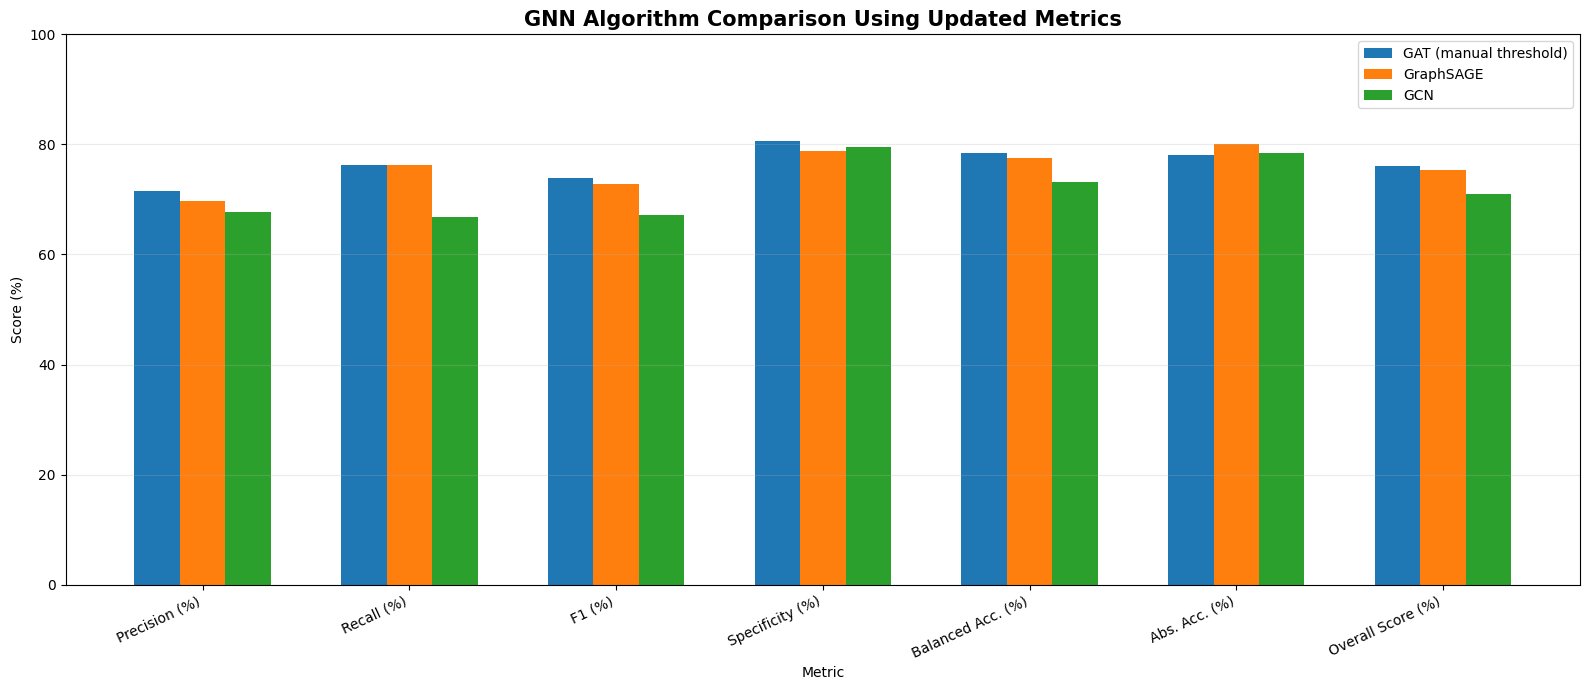

Saved bar chart: /content/drive/MyDrive/bfp_capstone_newrc/outputs/diagram_clean_gnn_algorithm_comparison_bar.png


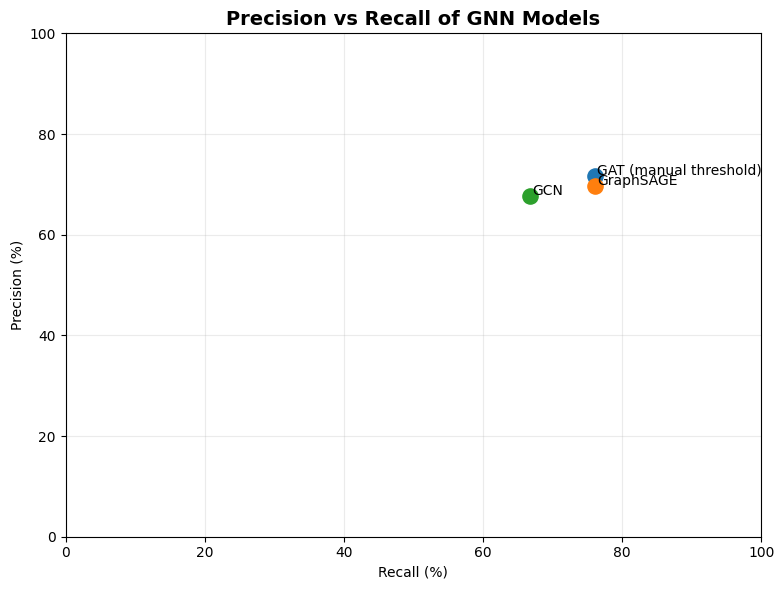

Saved precision-recall scatter: /content/drive/MyDrive/bfp_capstone_newrc/outputs/diagram_clean_precision_recall_scatter.png


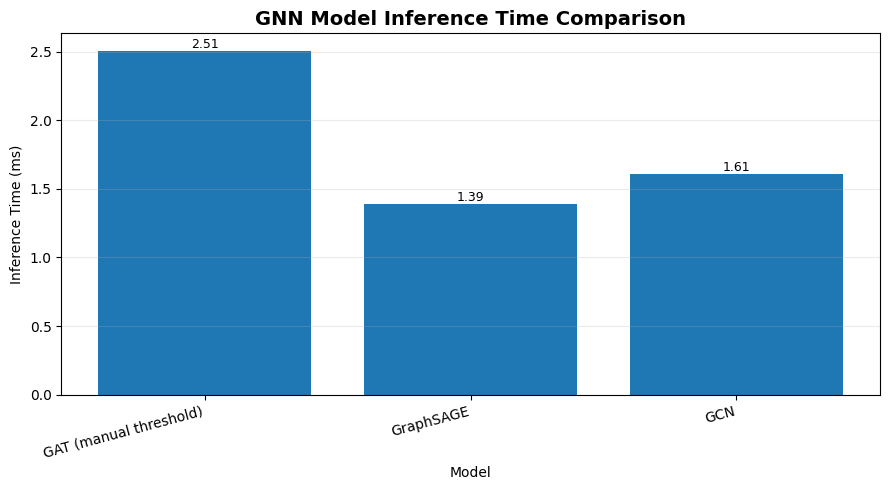

Saved inference speed chart: /content/drive/MyDrive/bfp_capstone_newrc/outputs/diagram_clean_inference_time_comparison.png


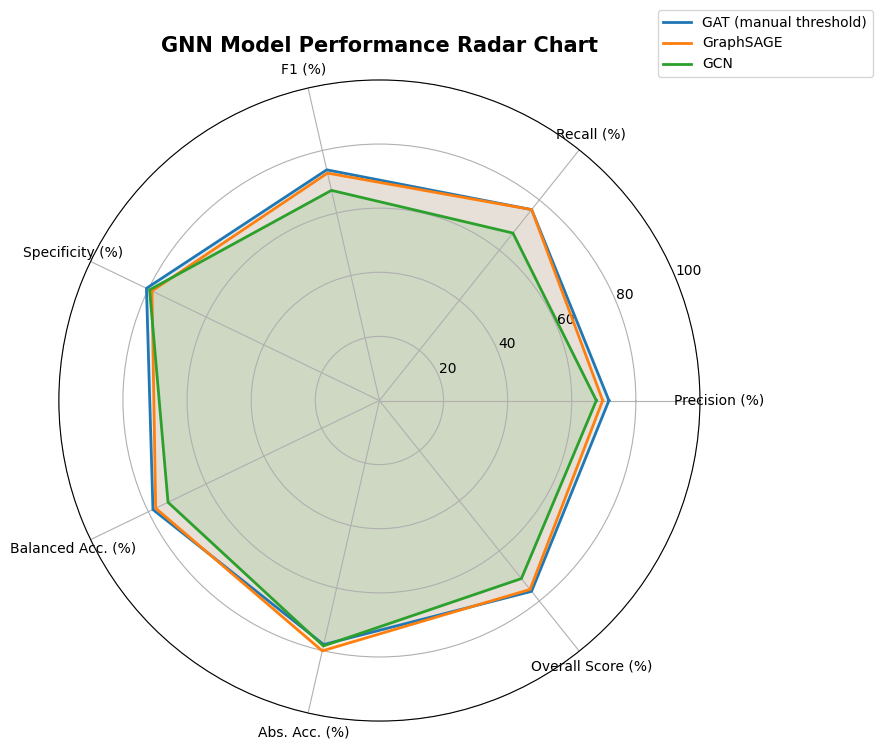

Saved radar chart: /content/drive/MyDrive/bfp_capstone_newrc/outputs/diagram_clean_gnn_algorithm_radar.png

Summary for paper/report:
                 Item                  Value
           Best model GAT (manual threshold)
    Overall score (%)                  76.14
        Precision (%)                   71.6
           Recall (%)                  76.17
         F1-score (%)                  73.81
      Specificity (%)                  80.65
Balanced accuracy (%)                  78.41
Absolute accuracy (%)                  78.09
   Selected threshold                   0.45
  Inference time (ms)                 2.5092

Saved summary: /content/drive/MyDrive/bfp_capstone_newrc/outputs/clean_summary_for_paper.csv

Cell 22 complete.


In [25]:
# ============================================================
# Cell 22 — Clean GNN Algorithm Comparison Diagrams
#
# Fixed version:
# - removes TP, FP, TN, FN
# - removes Predicted Positives and Actual Positives
# - removes Prediction Accuracy if it is missing/NaN
# - supports Abs. Accuracy and Inference Speed
# - avoids NaN-to-integer errors
# ============================================================

print("Creating clean GNN algorithm comparison diagrams...")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# Get results table
# ------------------------------------------------------------

if "results_df" not in globals():
    raise NameError("results_df is missing. Run Cell 19 or Cell 19.4 first.")

algo_df = results_df.copy()

# ------------------------------------------------------------
# Standardize model names for paper display
# ------------------------------------------------------------

algo_df["Model"] = algo_df["Model"].astype(str)

algo_df["Model"] = algo_df["Model"].replace({
    "GAT_MANUAL_RECALL_THRESHOLD": "GAT (manual threshold)",
    "GAT_MANUAL_THRESHOLD": "GAT (manual threshold)"
})

# If both base GAT and manual GAT exist, keep manual GAT for paper comparison
if "GAT (manual threshold)" in algo_df["Model"].values:
    algo_df = algo_df[algo_df["Model"] != "GAT"].copy()

# Keep only main models if present
preferred_models = ["GAT (manual threshold)", "GraphSAGE", "GCN"]
available_preferred = [m for m in preferred_models if m in algo_df["Model"].values]

if len(available_preferred) > 0:
    algo_df = algo_df[algo_df["Model"].isin(available_preferred)].copy()

# ------------------------------------------------------------
# Fix column naming variations
# ------------------------------------------------------------

if "Inference Time (ms)" not in algo_df.columns:
    if "Inference (ms)" in algo_df.columns:
        algo_df["Inference Time (ms)"] = algo_df["Inference (ms)"]
    elif "Inference (s)" in algo_df.columns:
        algo_df["Inference Time (ms)"] = algo_df["Inference (s)"] * 1000
    else:
        algo_df["Inference Time (ms)"] = np.nan

if "Relative Inference Speed (%)" not in algo_df.columns:
    if "Rel. Speed (%)" in algo_df.columns:
        algo_df["Relative Inference Speed (%)"] = algo_df["Rel. Speed (%)"]
    else:
        valid_times = pd.to_numeric(algo_df["Inference Time (ms)"], errors="coerce")
        fastest_time = valid_times[valid_times > 0].min()

        if pd.notna(fastest_time):
            algo_df["Relative Inference Speed (%)"] = (
                fastest_time / valid_times
            ) * 100
        else:
            algo_df["Relative Inference Speed (%)"] = np.nan

# ------------------------------------------------------------
# Convert important metrics to numeric
# ------------------------------------------------------------

numeric_cols = [
    "Precision (%)",
    "Recall (%)",
    "F1 (%)",
    "Specificity (%)",
    "Class. Acc. (%)",
    "Balanced Acc. (%)",
    "Abs. Acc. (%)",
    "Inference Time (ms)",
    "Relative Inference Speed (%)",
    "Threshold",
]

for col in numeric_cols:
    if col in algo_df.columns:
        algo_df[col] = pd.to_numeric(algo_df[col], errors="coerce")

# ------------------------------------------------------------
# Reconstruct specificity if missing but balanced accuracy and recall exist
# Balanced Accuracy = (Recall + Specificity) / 2
# ------------------------------------------------------------

if "Specificity (%)" not in algo_df.columns:
    algo_df["Specificity (%)"] = np.nan

if "Balanced Acc. (%)" in algo_df.columns and "Recall (%)" in algo_df.columns:
    missing_spec = algo_df["Specificity (%)"].isna()
    algo_df.loc[missing_spec, "Specificity (%)"] = (
        2 * algo_df.loc[missing_spec, "Balanced Acc. (%)"]
        - algo_df.loc[missing_spec, "Recall (%)"]
    )

# ------------------------------------------------------------
# Required metrics check
# ------------------------------------------------------------

required_cols = [
    "Model",
    "Precision (%)",
    "Recall (%)",
    "F1 (%)",
    "Specificity (%)",
    "Class. Acc. (%)",
    "Balanced Acc. (%)",
    "Abs. Acc. (%)",
]

missing_cols = [c for c in required_cols if c not in algo_df.columns]

if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")

# Drop rows that still do not have core metrics
algo_df = algo_df.dropna(
    subset=[
        "Precision (%)",
        "Recall (%)",
        "F1 (%)",
        "Specificity (%)",
        "Balanced Acc. (%)",
        "Abs. Acc. (%)",
    ]
).copy()

if len(algo_df) == 0:
    raise ValueError("No valid model rows remain after removing NaN metric rows.")

# ------------------------------------------------------------
# Recompute clean scores
# ------------------------------------------------------------

algo_df["Quality Score (%)"] = (
    0.25 * algo_df["F1 (%)"] +
    0.20 * algo_df["Balanced Acc. (%)"] +
    0.20 * algo_df["Recall (%)"] +
    0.15 * algo_df["Precision (%)"] +
    0.10 * algo_df["Specificity (%)"] +
    0.10 * algo_df["Abs. Acc. (%)"]
)

algo_df["Emergency Routing Score (%)"] = (
    0.30 * algo_df["Recall (%)"] +
    0.25 * algo_df["F1 (%)"] +
    0.15 * algo_df["Balanced Acc. (%)"] +
    0.10 * algo_df["Precision (%)"] +
    0.10 * algo_df["Specificity (%)"] +
    0.10 * algo_df["Abs. Acc. (%)"]
)

algo_df["Conservative Score (%)"] = (
    0.25 * algo_df["Specificity (%)"] +
    0.20 * algo_df["Precision (%)"] +
    0.20 * algo_df["F1 (%)"] +
    0.15 * algo_df["Balanced Acc. (%)"] +
    0.10 * algo_df["Recall (%)"] +
    0.10 * algo_df["Abs. Acc. (%)"]
)

algo_df["Overall Score (%)"] = (
    0.40 * algo_df["Quality Score (%)"] +
    0.35 * algo_df["Emergency Routing Score (%)"] +
    0.25 * algo_df["Conservative Score (%)"]
)

# Deployment score includes inference speed only if available
if algo_df["Relative Inference Speed (%)"].notna().any():
    algo_df["Deployment Score (%)"] = (
        0.90 * algo_df["Overall Score (%)"] +
        0.10 * algo_df["Relative Inference Speed (%)"].fillna(0)
    )
else:
    algo_df["Deployment Score (%)"] = algo_df["Overall Score (%)"]

# ------------------------------------------------------------
# Sort by Overall Score
# ------------------------------------------------------------

algo_df = algo_df.sort_values(
    "Overall Score (%)",
    ascending=False
).reset_index(drop=True)

# ------------------------------------------------------------
# Display clean table
# ------------------------------------------------------------

display_cols = [
    "Model",
    "Precision (%)",
    "Recall (%)",
    "F1 (%)",
    "Specificity (%)",
    "Class. Acc. (%)",
    "Balanced Acc. (%)",
    "Abs. Acc. (%)",
    "Threshold",
    "Inference Time (ms)",
    "Relative Inference Speed (%)",
    "Quality Score (%)",
    "Emergency Routing Score (%)",
    "Conservative Score (%)",
    "Overall Score (%)",
    "Deployment Score (%)",
]

display_cols = [c for c in display_cols if c in algo_df.columns]

print("")
print("Clean GNN Algorithm Comparison Table:")
print(algo_df[display_cols].round(2).to_string(index=False))

clean_table_path = os.path.join(
    OUTPUT_DIR,
    "clean_gnn_algorithm_comparison_table.csv"
)

algo_df[display_cols].to_csv(clean_table_path, index=False)

print("")
print(f"Saved clean comparison table: {clean_table_path}")

# ============================================================
# Diagram 1 — Main comparison bar chart
# ============================================================

metrics_to_plot = [
    "Precision (%)",
    "Recall (%)",
    "F1 (%)",
    "Specificity (%)",
    "Balanced Acc. (%)",
    "Abs. Acc. (%)",
    "Overall Score (%)",
]

metrics_to_plot = [m for m in metrics_to_plot if m in algo_df.columns]

x = np.arange(len(metrics_to_plot))
models_order = algo_df["Model"].tolist()

bar_width = 0.22

fig, ax = plt.subplots(figsize=(16, 7))

for i, model_name in enumerate(models_order):
    vals = [
        float(algo_df.loc[algo_df["Model"] == model_name, metric].iloc[0])
        for metric in metrics_to_plot
    ]

    ax.bar(
        x + (i - (len(models_order) - 1) / 2) * bar_width,
        vals,
        width=bar_width,
        label=model_name
    )

ax.set_title(
    "GNN Algorithm Comparison Using Updated Metrics",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Metric")
ax.set_ylabel("Score (%)")
ax.set_xticks(x)
ax.set_xticklabels(metrics_to_plot, rotation=25, ha="right")
ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.25)
ax.legend()

plt.tight_layout()

bar_path = os.path.join(
    OUTPUT_DIR,
    "diagram_clean_gnn_algorithm_comparison_bar.png"
)

plt.savefig(bar_path, dpi=250, bbox_inches="tight")
plt.show()

print(f"Saved bar chart: {bar_path}")

# ============================================================
# Diagram 2 — Precision vs Recall scatter
# ============================================================

fig, ax = plt.subplots(figsize=(8, 6))

for _, row in algo_df.iterrows():
    ax.scatter(
        row["Recall (%)"],
        row["Precision (%)"],
        s=120,
        label=row["Model"]
    )

    ax.text(
        row["Recall (%)"] + 0.3,
        row["Precision (%)"] + 0.3,
        row["Model"],
        fontsize=10
    )

ax.set_title(
    "Precision vs Recall of GNN Models",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Recall (%)")
ax.set_ylabel("Precision (%)")
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.grid(True, alpha=0.25)

plt.tight_layout()

scatter_path = os.path.join(
    OUTPUT_DIR,
    "diagram_clean_precision_recall_scatter.png"
)

plt.savefig(scatter_path, dpi=250, bbox_inches="tight")
plt.show()

print(f"Saved precision-recall scatter: {scatter_path}")

# ============================================================
# Diagram 3 — Inference speed comparison
# ============================================================

if algo_df["Inference Time (ms)"].notna().any():
    fig, ax = plt.subplots(figsize=(9, 5))

    x = np.arange(len(algo_df))

    ax.bar(
        x,
        algo_df["Inference Time (ms)"]
    )

    ax.set_title(
        "GNN Model Inference Time Comparison",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel("Model")
    ax.set_ylabel("Inference Time (ms)")
    ax.set_xticks(x)
    ax.set_xticklabels(algo_df["Model"], rotation=15, ha="right")
    ax.grid(axis="y", alpha=0.25)

    for i, row in algo_df.iterrows():
        if pd.notna(row["Inference Time (ms)"]):
            ax.text(
                i,
                row["Inference Time (ms)"],
                f'{row["Inference Time (ms)"]:.2f}',
                ha="center",
                va="bottom",
                fontsize=9
            )

    plt.tight_layout()

    speed_path = os.path.join(
        OUTPUT_DIR,
        "diagram_clean_inference_time_comparison.png"
    )

    plt.savefig(speed_path, dpi=250, bbox_inches="tight")
    plt.show()

    print(f"Saved inference speed chart: {speed_path}")

# ============================================================
# Diagram 4 — Radar chart
# ============================================================

radar_metrics = [
    "Precision (%)",
    "Recall (%)",
    "F1 (%)",
    "Specificity (%)",
    "Balanced Acc. (%)",
    "Abs. Acc. (%)",
    "Overall Score (%)",
]

radar_metrics = [m for m in radar_metrics if m in algo_df.columns]

radar_df = algo_df.set_index("Model")[radar_metrics].copy()

labels = radar_metrics
num_vars = len(labels)

angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
angles += angles[:1]

fig = plt.figure(figsize=(9, 9))
ax = plt.subplot(111, polar=True)

for model_name, row in radar_df.iterrows():
    values = row.tolist()
    values += values[:1]

    ax.plot(
        angles,
        values,
        linewidth=2,
        label=model_name
    )

    ax.fill(
        angles,
        values,
        alpha=0.12
    )

ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels, fontsize=10)
ax.set_ylim(0, 100)

ax.set_title(
    "GNN Model Performance Radar Chart",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.legend(
    loc="upper right",
    bbox_to_anchor=(1.28, 1.12)
)

ax.grid(True)

plt.tight_layout()

radar_path = os.path.join(
    OUTPUT_DIR,
    "diagram_clean_gnn_algorithm_radar.png"
)

plt.savefig(radar_path, dpi=250, bbox_inches="tight")
plt.show()

print(f"Saved radar chart: {radar_path}")

# ============================================================
# Summary for paper/report
# ============================================================

best_model = algo_df.sort_values(
    "Overall Score (%)",
    ascending=False
).iloc[0]

summary_items = [
    {
        "Item": "Best model",
        "Value": best_model["Model"]
    },
    {
        "Item": "Overall score (%)",
        "Value": round(float(best_model["Overall Score (%)"]), 2)
    },
    {
        "Item": "Precision (%)",
        "Value": round(float(best_model["Precision (%)"]), 2)
    },
    {
        "Item": "Recall (%)",
        "Value": round(float(best_model["Recall (%)"]), 2)
    },
    {
        "Item": "F1-score (%)",
        "Value": round(float(best_model["F1 (%)"]), 2)
    },
    {
        "Item": "Specificity (%)",
        "Value": round(float(best_model["Specificity (%)"]), 2)
    },
    {
        "Item": "Balanced accuracy (%)",
        "Value": round(float(best_model["Balanced Acc. (%)"]), 2)
    },
    {
        "Item": "Absolute accuracy (%)",
        "Value": round(float(best_model["Abs. Acc. (%)"]), 2)
    },
]

if "Threshold" in best_model and pd.notna(best_model["Threshold"]):
    summary_items.append({
        "Item": "Selected threshold",
        "Value": round(float(best_model["Threshold"]), 2)
    })

if "Inference Time (ms)" in best_model and pd.notna(best_model["Inference Time (ms)"]):
    summary_items.append({
        "Item": "Inference time (ms)",
        "Value": round(float(best_model["Inference Time (ms)"]), 4)
    })

summary_for_paper = pd.DataFrame(summary_items)

summary_path = os.path.join(
    OUTPUT_DIR,
    "clean_summary_for_paper.csv"
)

summary_for_paper.to_csv(summary_path, index=False)

print("")
print("Summary for paper/report:")
print(summary_for_paper.to_string(index=False))

print("")
print(f"Saved summary: {summary_path}")
print("")
print("Cell 22 complete.")

In [26]:
# ============================================================
# Cell 21.1 — Export ALT-ready edge_weights.json
#
# Purpose:
# - Converts the final exported GAT/manual-threshold map into routing weights.
# - Uses distance + constraint score + GAT confidence.
# - Produces edge_weight_sec for ALT routing.
# - Allows passable constrained roads to be used if they are still faster
#   than a far unconstrained route.
#
# Run this AFTER Cell 21.
# ============================================================

print("Exporting ALT-ready edge weights...")

import os
import json
import math
import numpy as np
import pandas as pd
import geopandas as gpd

# ------------------------------------------------------------
# Required checks
# ------------------------------------------------------------

if "final_export_gdf" not in globals():
    raise NameError("final_export_gdf is missing. Run Cell 21 first.")

if "OUTPUT_DIR" not in globals():
    raise NameError("OUTPUT_DIR is missing.")

# Use the same folder from Cell 21 when available
if "export_folder" in globals():
    EDGE_EXPORT_DIR = export_folder
elif "EXPORT_DIR" in globals():
    EDGE_EXPORT_DIR = EXPORT_DIR
else:
    EDGE_EXPORT_DIR = os.path.join(OUTPUT_DIR, "best_model_export")
    os.makedirs(EDGE_EXPORT_DIR, exist_ok=True)

os.makedirs(EDGE_EXPORT_DIR, exist_ok=True)

# ------------------------------------------------------------
# SETTINGS
# ------------------------------------------------------------

# If True, GAT-only predicted roads affect routing.
# If False, only manual verified constraints affect routing.
# Since you want backend routing using GAT predictions, keep True.
USE_GAT_ONLY_PREDICTIONS_IN_ROUTING = True

# If True, construction is treated as blocked.
# If False, construction is passable but heavily penalized.
BLOCK_CONSTRUCTION = False

# Default emergency vehicle speed if no speed/maxspeed/highway info exists.
DEFAULT_SPEED_KMH = 30.0

# Optional speed estimate by road class if 'highway' column exists.
SPEED_BY_HIGHWAY = {
    "primary": 45.0,
    "secondary": 40.0,
    "tertiary": 35.0,
    "residential": 25.0,
    "service": 20.0,
    "unclassified": 25.0,
    "track": 15.0,
    "road": 25.0,
}

# ------------------------------------------------------------
# Constraint scores, 0 to 1
# Replace these values with your final approved scoring table.
# 0.00 = no hassle
# 1.00 = highest hassle / hardest to pass
# ------------------------------------------------------------

CONSTRAINT_SCORE_0_1 = {
    "normal": 0.00,

    # GAT-only prediction classes
    "predicted_constraint_review": 0.30,
    "predicted_constraint_high_confidence": 0.45,

    # Narrow roads
    "narrow_road_slight": 0.45,
    "narrow_road": 0.55,
    "narrow_road_severe": 0.85,

    # Traffic constraints
    "traffic_highway": 0.60,
    "traffic_general": 0.70,
    "traffic_pnm": 0.80,
    "traffic_market": 0.85,
    "traffic_school": 0.65,
    "traffic_school_peak": 0.90,
    "traffic_nightmarket": 1.00,

    # Hard constraint
    "construction": 1.00,
}

# Maximum multiplier when effective constraint score = 1.
# Example:
# max multiplier 1.80 means that edge can become up to 80% slower.
MAX_MULTIPLIER_BY_TYPE = {
    "normal": 1.00,

    "predicted_constraint_review": 1.15,
    "predicted_constraint_high_confidence": 1.25,

    "narrow_road_slight": 1.25,
    "narrow_road": 1.45,
    "narrow_road_severe": 1.80,

    "traffic_highway": 1.25,
    "traffic_general": 1.35,
    "traffic_pnm": 1.60,
    "traffic_market": 1.55,
    "traffic_school": 1.45,
    "traffic_school_peak": 1.60,
    "traffic_nightmarket": 1.75,

    "construction": 3.00,
}

# Higher value makes constraint score more influential.
# 1.0 = normal use of scores.
# 1.2 or 1.5 = more aggressive avoidance.
CONSTRAINT_PENALTY_STRENGTH = 1.0

# Endpoint rounding for graph node creation.
# 7 decimals is roughly centimeter-level in lon/lat and works well for exported OSM/QGIS lines.
NODE_ROUND_DECIMALS = 7

# ------------------------------------------------------------
# Prepare edge GeoDataFrame
# ------------------------------------------------------------

edges_gdf = final_export_gdf.copy()

if not isinstance(edges_gdf, gpd.GeoDataFrame):
    edges_gdf = gpd.GeoDataFrame(edges_gdf, geometry="geometry", crs="EPSG:4326")

if edges_gdf.crs is None:
    edges_gdf = edges_gdf.set_crs(epsg=4326)

edges_gdf = edges_gdf.to_crs(epsg=4326).copy()

if "road_id" not in edges_gdf.columns:
    edges_gdf["road_id"] = np.arange(len(edges_gdf))

# Calculate road length in meters using UTM Zone 51N, suitable for Panabo/Davao area.
edges_m = edges_gdf.to_crs(epsg=32651).copy()
edges_gdf["length_m"] = edges_m.geometry.length

# ------------------------------------------------------------
# Geometry endpoint helpers for source_node / target_node
# ------------------------------------------------------------

def get_main_linestring(geom):
    if geom is None or geom.is_empty:
        return None

    if geom.geom_type == "LineString":
        return geom

    if geom.geom_type == "MultiLineString":
        return max(list(geom.geoms), key=lambda g: g.length)

    return None


def endpoint_keys(geom, decimals=7):
    line = get_main_linestring(geom)

    if line is None:
        return None, None

    coords = list(line.coords)

    if len(coords) < 2:
        return None, None

    start = coords[0]
    end = coords[-1]

    u_key = f"{round(float(start[0]), decimals)}_{round(float(start[1]), decimals)}"
    v_key = f"{round(float(end[0]), decimals)}_{round(float(end[1]), decimals)}"

    return u_key, v_key


node_id_map = {}
next_node_id = 0

source_nodes = []
target_nodes = []
source_keys = []
target_keys = []

for geom in edges_gdf.geometry:
    u_key, v_key = endpoint_keys(geom, NODE_ROUND_DECIMALS)

    if u_key is None or v_key is None:
        source_nodes.append(None)
        target_nodes.append(None)
        source_keys.append(None)
        target_keys.append(None)
        continue

    if u_key not in node_id_map:
        node_id_map[u_key] = next_node_id
        next_node_id += 1

    if v_key not in node_id_map:
        node_id_map[v_key] = next_node_id
        next_node_id += 1

    source_nodes.append(node_id_map[u_key])
    target_nodes.append(node_id_map[v_key])
    source_keys.append(u_key)
    target_keys.append(v_key)

edges_gdf["source_node"] = source_nodes
edges_gdf["target_node"] = target_nodes
edges_gdf["source_coord_key"] = source_keys
edges_gdf["target_coord_key"] = target_keys

# ------------------------------------------------------------
# Routing type and speed helpers
# ------------------------------------------------------------

def parse_speed_value(value):
    """
    Converts maxspeed values like '30', '30 km/h', or '30;40' into km/h.
    Returns None if invalid.
    """
    if pd.isna(value):
        return None

    text = str(value).lower().strip()

    if text == "":
        return None

    # Handle values like "30;40" by taking first number.
    import re
    match = re.search(r"(\d+(\.\d+)?)", text)

    if not match:
        return None

    speed = float(match.group(1))

    # If value looks like mph, convert to km/h.
    if "mph" in text:
        speed *= 1.60934

    return speed


def get_speed_kmh(row):
    # Prefer explicit speed columns if present.
    for col in ["speed_kmh", "maxspeed", "max_speed", "speed"]:
        if col in row.index:
            parsed = parse_speed_value(row[col])

            if parsed is not None and parsed > 0:
                return float(parsed)

    # Use highway class if present.
    if "highway" in row.index and pd.notna(row["highway"]):
        highway = str(row["highway"]).lower().strip()

        if highway in SPEED_BY_HIGHWAY:
            return SPEED_BY_HIGHWAY[highway]

    return DEFAULT_SPEED_KMH


def choose_routing_constraint_type(row):
    """
    Chooses which constraint type will affect routing.

    Manual constraints:
    - Always use routing_constraint_type or display_constraint_type.

    GAT-only predictions:
    - If USE_GAT_ONLY_PREDICTIONS_IN_ROUTING is True, use display_constraint_type
      for predicted_constraint_review/high_confidence.
    - If False, treat them as normal for routing.
    """
    display_type = str(row.get("display_constraint_type", "normal"))
    routing_type = str(row.get("routing_constraint_type", "normal"))
    annotation_source = str(row.get("annotation_source", ""))

    is_manual = int(row.get("is_manual_verified", 0)) == 1
    is_gat_only = int(row.get("is_gat_only_prediction", 0)) == 1

    if is_manual:
        if routing_type and routing_type != "normal":
            return routing_type

        return display_type

    if is_gat_only and USE_GAT_ONLY_PREDICTIONS_IN_ROUTING:
        return display_type

    return "normal"


def get_confidence_factor(row, constraint_type):
    """
    Manual verified constraints use 1.0 confidence.
    GAT-only predictions use model_probability.
    Normal roads use 0.0.
    """
    is_manual = int(row.get("is_manual_verified", 0)) == 1

    if is_manual:
        return 1.0

    if constraint_type == "normal":
        return 0.0

    if "model_probability" in row.index and pd.notna(row["model_probability"]):
        return float(np.clip(row["model_probability"], 0.0, 1.0))

    if "model_probability_pct" in row.index and pd.notna(row["model_probability_pct"]):
        return float(np.clip(row["model_probability_pct"] / 100.0, 0.0, 1.0))

    if "final_display_confidence_pct" in row.index and pd.notna(row["final_display_confidence_pct"]):
        return float(np.clip(row["final_display_confidence_pct"] / 100.0, 0.0, 1.0))

    return 1.0


def is_oneway(row):
    """
    Basic OSM oneway parser.
    If unknown, assume bidirectional.
    """
    if "oneway" not in row.index or pd.isna(row["oneway"]):
        return False

    value = str(row["oneway"]).lower().strip()

    return value in ["yes", "true", "1", "-1"]


def calculate_edge_weight(row):
    ctype = choose_routing_constraint_type(row)

    length_m = float(row["length_m"])
    speed_kmh = get_speed_kmh(row)
    speed_mps = max(speed_kmh * 1000.0 / 3600.0, 0.1)

    base_time_sec = length_m / speed_mps

    raw_score = float(CONSTRAINT_SCORE_0_1.get(ctype, 0.0))
    confidence_factor = get_confidence_factor(row, ctype)

    effective_score = raw_score * confidence_factor * CONSTRAINT_PENALTY_STRENGTH
    effective_score = float(np.clip(effective_score, 0.0, 1.0))

    max_multiplier = float(MAX_MULTIPLIER_BY_TYPE.get(ctype, 1.0))
    routing_multiplier = 1.0 + ((max_multiplier - 1.0) * effective_score)

    blocked = False

    if BLOCK_CONSTRUCTION and ctype == "construction":
        blocked = True
        constraint_penalty_sec = None
        estimated_time_sec = None
        edge_weight_sec = None
    else:
        estimated_time_sec = base_time_sec * routing_multiplier
        constraint_penalty_sec = estimated_time_sec - base_time_sec
        edge_weight_sec = estimated_time_sec

    return pd.Series({
        "constraint_type_for_routing": ctype,
        "constraint_score_0_1": raw_score,
        "confidence_factor": confidence_factor,
        "effective_constraint_score": effective_score,
        "speed_kmh": speed_kmh,
        "base_time_sec": base_time_sec,
        "routing_multiplier_calc": routing_multiplier,
        "constraint_penalty_sec": constraint_penalty_sec,
        "estimated_time_sec": estimated_time_sec,
        "edge_weight_sec": edge_weight_sec,
        "is_blocked_for_routing": int(blocked),
        "is_oneway": int(is_oneway(row)),
    })


weight_df = edges_gdf.apply(calculate_edge_weight, axis=1)

for col in weight_df.columns:
    edges_gdf[col] = weight_df[col]

# ------------------------------------------------------------
# Build node list with coordinates
# ------------------------------------------------------------

nodes = []

for coord_key, node_id in node_id_map.items():
    try:
        lon_text, lat_text = coord_key.split("_")
        lon = float(lon_text)
        lat = float(lat_text)
    except Exception:
        lon = None
        lat = None

    nodes.append({
        "node_id": int(node_id),
        "coordinate_key": coord_key,
        "lon": lon,
        "lat": lat,
    })

# ------------------------------------------------------------
# Build edge records for ALT
# ------------------------------------------------------------

edge_records = []
directed_edge_records = []

for _, row in edges_gdf.iterrows():
    if pd.isna(row["source_node"]) or pd.isna(row["target_node"]):
        continue

    source = int(row["source_node"])
    target = int(row["target_node"])

    edge_weight = None if pd.isna(row["edge_weight_sec"]) else round(float(row["edge_weight_sec"]), 3)
    estimated_time = None if pd.isna(row["estimated_time_sec"]) else round(float(row["estimated_time_sec"]), 3)
    penalty_time = None if pd.isna(row["constraint_penalty_sec"]) else round(float(row["constraint_penalty_sec"]), 3)

    base_record = {
        "edge_id": str(row["road_id"]),
        "road_id": int(row["road_id"]) if pd.notna(row["road_id"]) else None,
        "source_node": source,
        "target_node": target,

        "length_m": round(float(row["length_m"]), 3),
        "speed_kmh": round(float(row["speed_kmh"]), 3),
        "base_time_sec": round(float(row["base_time_sec"]), 3),

        "constraint_type": str(row["constraint_type_for_routing"]),
        "display_constraint_type": str(row.get("display_constraint_type", row["constraint_type_for_routing"])),
        "routing_constraint_type": str(row.get("routing_constraint_type", row["constraint_type_for_routing"])),
        "annotation_source": str(row.get("annotation_source", "")),

        "constraint_score_0_1": round(float(row["constraint_score_0_1"]), 3),
        "confidence_factor": round(float(row["confidence_factor"]), 3),
        "effective_constraint_score": round(float(row["effective_constraint_score"]), 3),
        "routing_multiplier": round(float(row["routing_multiplier_calc"]), 3),

        "constraint_penalty_sec": penalty_time,
        "estimated_time_sec": estimated_time,
        "edge_weight_sec": edge_weight,

        "is_blocked": bool(row["is_blocked_for_routing"]),
        "is_oneway": bool(row["is_oneway"]),

        "model_probability": round(float(row["model_probability"]), 5) if "model_probability" in row.index and pd.notna(row["model_probability"]) else None,
        "model_threshold": round(float(row["model_threshold"]), 5) if "model_threshold" in row.index and pd.notna(row["model_threshold"]) else None,
        "best_result_label": str(row.get("best_result_label", "")),
        "actual_model_used": str(row.get("actual_model_used", "")),
    }

    edge_records.append(base_record)

    # Directed records for backend graph building.
    # If the road is not one-way, export both directions.
    forward_record = base_record.copy()
    forward_record["direction"] = "forward"
    directed_edge_records.append(forward_record)

    if not bool(row["is_oneway"]):
        reverse_record = base_record.copy()
        reverse_record["source_node"] = target
        reverse_record["target_node"] = source
        reverse_record["direction"] = "reverse"
        reverse_record["edge_id"] = str(row["road_id"]) + "_rev"
        directed_edge_records.append(reverse_record)

# ------------------------------------------------------------
# Build output JSON
# ------------------------------------------------------------

metadata = {
    "description": "ALT-ready weighted road graph edges using distance, constraint score, and GAT/manual-threshold confidence.",
    "best_result_label": str(edges_gdf["best_result_label"].iloc[0]) if "best_result_label" in edges_gdf.columns else "",
    "actual_model_used": str(edges_gdf["actual_model_used"].iloc[0]) if "actual_model_used" in edges_gdf.columns else "",
    "model_threshold": float(edges_gdf["model_threshold"].iloc[0]) if "model_threshold" in edges_gdf.columns else None,
    "use_gat_only_predictions_in_routing": USE_GAT_ONLY_PREDICTIONS_IN_ROUTING,
    "block_construction": BLOCK_CONSTRUCTION,
    "default_speed_kmh": DEFAULT_SPEED_KMH,
    "constraint_penalty_strength": CONSTRAINT_PENALTY_STRENGTH,
    "cost_field_for_ALT": "edge_weight_sec",
    "eta_field": "estimated_time_sec",
    "constraint_score_range": "0 to 1",
    "formula": {
        "base_time_sec": "length_m / (speed_kmh * 1000 / 3600)",
        "effective_constraint_score": "constraint_score_0_1 * confidence_factor * constraint_penalty_strength",
        "routing_multiplier": "1 + ((max_multiplier_by_type - 1) * effective_constraint_score)",
        "estimated_time_sec": "base_time_sec * routing_multiplier",
        "edge_weight_sec": "estimated_time_sec"
    },
    "number_of_road_segments": len(edge_records),
    "number_of_directed_edges": len(directed_edge_records),
    "number_of_nodes": len(nodes),
}

edge_weights = {
    "metadata": metadata,
    "constraint_score_0_1": CONSTRAINT_SCORE_0_1,
    "max_multiplier_by_type": MAX_MULTIPLIER_BY_TYPE,
    "nodes": nodes,
    "edges": edge_records,
    "directed_edges": directed_edge_records,
}

# ------------------------------------------------------------
# Save files
# ------------------------------------------------------------

edge_json_path = os.path.join(EDGE_EXPORT_DIR, "edge_weights.json")
edge_csv_path = os.path.join(EDGE_EXPORT_DIR, "edge_weights.csv")
directed_edge_csv_path = os.path.join(EDGE_EXPORT_DIR, "edge_weights_directed.csv")
weighted_geojson_path = os.path.join(EDGE_EXPORT_DIR, "best_model_predicted_constraints_WITH_EDGE_WEIGHTS.geojson")
weighted_gpkg_path = os.path.join(EDGE_EXPORT_DIR, "best_model_predicted_constraints_WITH_EDGE_WEIGHTS.gpkg")
formula_config_path = os.path.join(EDGE_EXPORT_DIR, "route_cost_formula_config.json")

with open(edge_json_path, "w") as f:
    json.dump(edge_weights, f, indent=2)

pd.DataFrame(edge_records).to_csv(edge_csv_path, index=False)
pd.DataFrame(directed_edge_records).to_csv(directed_edge_csv_path, index=False)

edges_gdf.to_file(weighted_geojson_path, driver="GeoJSON")
edges_gdf.to_file(weighted_gpkg_path, driver="GPKG")

formula_config = {
    "constraint_score_0_1": CONSTRAINT_SCORE_0_1,
    "max_multiplier_by_type": MAX_MULTIPLIER_BY_TYPE,
    "use_gat_only_predictions_in_routing": USE_GAT_ONLY_PREDICTIONS_IN_ROUTING,
    "block_construction": BLOCK_CONSTRUCTION,
    "default_speed_kmh": DEFAULT_SPEED_KMH,
    "constraint_penalty_strength": CONSTRAINT_PENALTY_STRENGTH,
    "formula": metadata["formula"]
}

with open(formula_config_path, "w") as f:
    json.dump(formula_config, f, indent=2)

print("")
print("Saved ALT routing files:")
print(edge_json_path)
print(edge_csv_path)
print(directed_edge_csv_path)
print(weighted_geojson_path)
print(weighted_gpkg_path)
print(formula_config_path)

print("")
print("Edge-weight summary by routing constraint type:")
summary_cols = [
    "constraint_type_for_routing",
    "length_m",
    "constraint_score_0_1",
    "confidence_factor",
    "effective_constraint_score",
    "routing_multiplier_calc",
    "base_time_sec",
    "constraint_penalty_sec",
    "estimated_time_sec",
    "edge_weight_sec"
]

print(
    edges_gdf[summary_cols]
    .groupby("constraint_type_for_routing")
    .mean(numeric_only=True)
    .round(3)
)

print("")
print("Routing files are ready for backend ALT.")
print("Use edge_weights.json -> directed_edges -> edge_weight_sec as ALT graph cost.")

Exporting ALT-ready edge weights...

Saved ALT routing files:
/content/drive/MyDrive/bfp_capstone_newrc/outputs/best_model_export/edge_weights.json
/content/drive/MyDrive/bfp_capstone_newrc/outputs/best_model_export/edge_weights.csv
/content/drive/MyDrive/bfp_capstone_newrc/outputs/best_model_export/edge_weights_directed.csv
/content/drive/MyDrive/bfp_capstone_newrc/outputs/best_model_export/best_model_predicted_constraints_WITH_EDGE_WEIGHTS.geojson
/content/drive/MyDrive/bfp_capstone_newrc/outputs/best_model_export/best_model_predicted_constraints_WITH_EDGE_WEIGHTS.gpkg
/content/drive/MyDrive/bfp_capstone_newrc/outputs/best_model_export/route_cost_formula_config.json

Edge-weight summary by routing constraint type:
                                      length_m  constraint_score_0_1  \
constraint_type_for_routing                                            
construction                           105.880                  1.00   
narrow_road                            177.810            

Total Panabo road edges/segments: 3639

Split Summary:
split  Total_Edges  Constrained_Edges  Normal_Edges  Constraint_Rate (%)
 test          602                235           367                39.04
train         2420                800          1620                33.06
  val          617                173           444                28.04


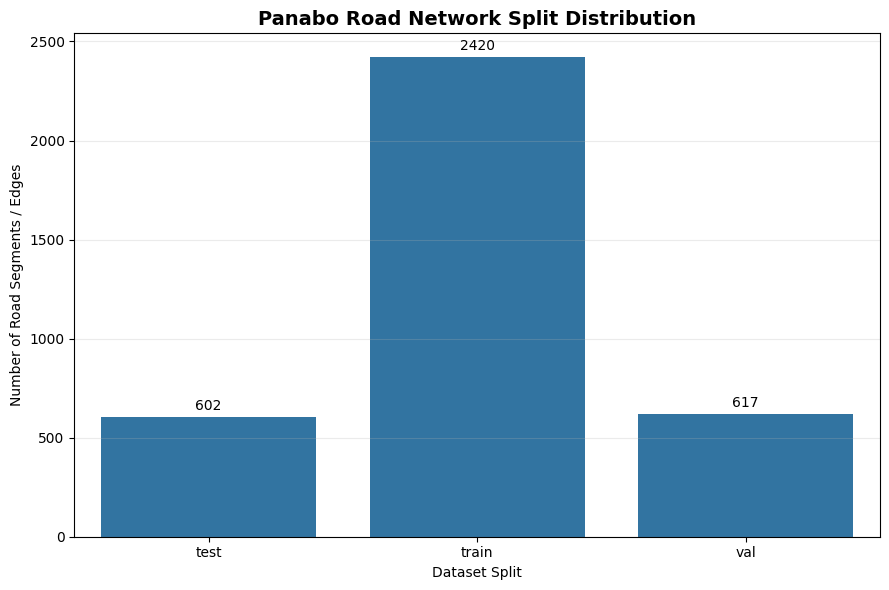

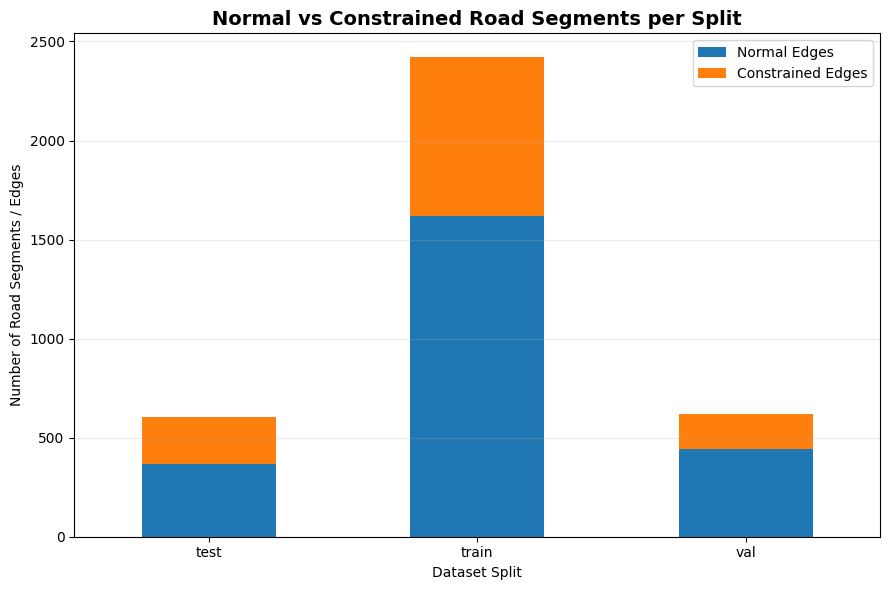


Actual Annotated Constraint Distribution:
    constraint_type  Edge_Count  Average_Score  Percentage (%)
             normal        2431           0.00           66.80
 narrow_road_slight        1063           0.45           29.21
 narrow_road_severe          76           0.85            2.09
        traffic_pnm          12           0.80            0.33
     traffic_school          12           0.65            0.33
traffic_nightmarket          10           1.00            0.27
        narrow_road           9           0.55            0.25
    traffic_general           9           0.70            0.25
    traffic_highway           7           0.60            0.19
       construction           5           1.00            0.14
     traffic_market           5           0.85            0.14


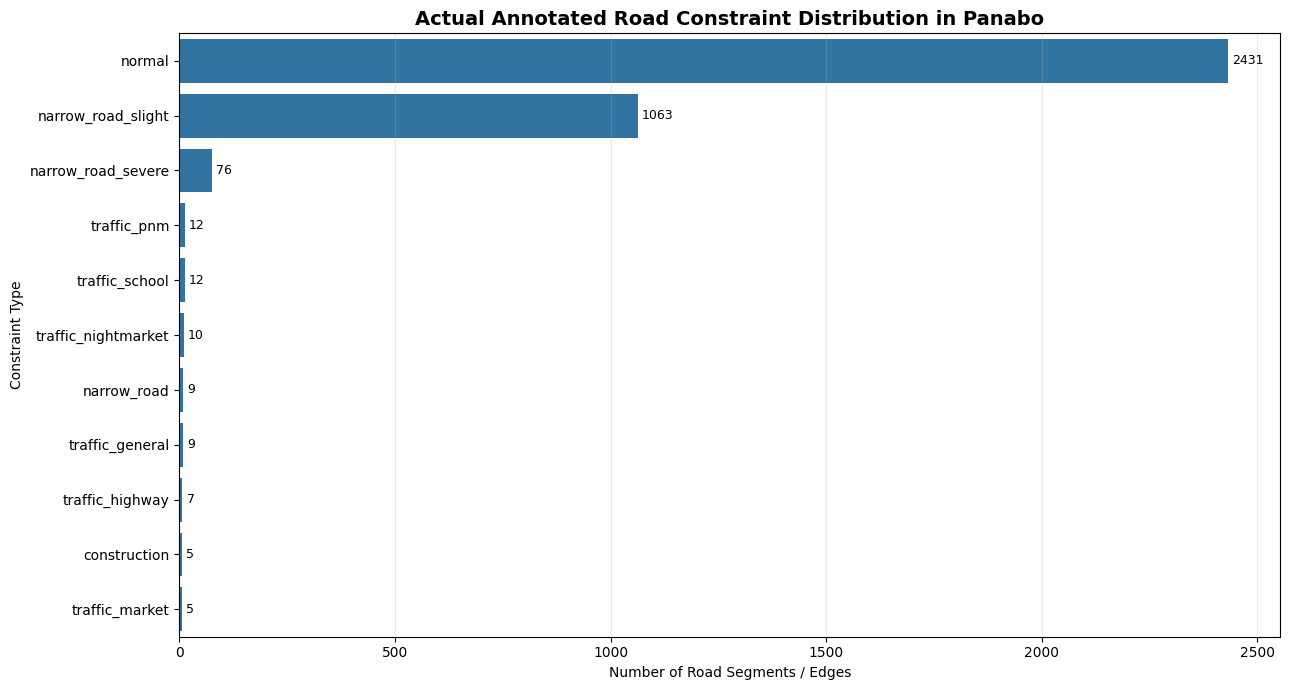

In [27]:
# ============================================================
# Cell 23 — Dataset split and constraint distribution diagrams
# ============================================================

total_edges = len(df)

split_summary = df.groupby("split").agg(
    Total_Edges=("seg_id", "count"),
    Constrained_Edges=("is_constrained", "sum")
).reset_index()

split_summary["Normal_Edges"] = split_summary["Total_Edges"] - split_summary["Constrained_Edges"]
split_summary["Constraint_Rate (%)"] = (split_summary["Constrained_Edges"] / split_summary["Total_Edges"]) * 100

print(f"Total Panabo road edges/segments: {total_edges}")
print("\nSplit Summary:")
print(split_summary.round(2).to_string(index=False))

split_summary.to_csv(OUTPUT_DIR + "diagram_split_edges_summary.csv", index=False)

plt.figure(figsize=(9, 6))
ax = sns.barplot(data=split_summary, x="split", y="Total_Edges")

plt.title("Panabo Road Network Split Distribution", fontsize=14, fontweight="bold")
plt.xlabel("Dataset Split")
plt.ylabel("Number of Road Segments / Edges")
plt.grid(axis="y", alpha=0.25)

for container in ax.containers:
    ax.bar_label(container, fmt="%d", fontsize=10, padding=3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR + "diagram_total_edges_per_split.png", dpi=250, bbox_inches="tight")
plt.show()

split_stacked = split_summary.set_index("split")[["Normal_Edges", "Constrained_Edges"]]
split_stacked.plot(kind="bar", stacked=True, figsize=(9, 6))

plt.title("Normal vs Constrained Road Segments per Split", fontsize=14, fontweight="bold")
plt.xlabel("Dataset Split")
plt.ylabel("Number of Road Segments / Edges")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.25)
plt.legend(["Normal Edges", "Constrained Edges"])

plt.tight_layout()
plt.savefig(OUTPUT_DIR + "diagram_normal_vs_constrained_split.png", dpi=250, bbox_inches="tight")
plt.show()

constraint_count_df = df.groupby("constraint_type").agg(
    Edge_Count=("seg_id", "count"),
    Average_Score=("constraint_score", "mean")
).reset_index()

constraint_count_df["Percentage (%)"] = (
    constraint_count_df["Edge_Count"] / len(df)
) * 100

constraint_count_df = constraint_count_df.sort_values("Edge_Count", ascending=False)

print("\nActual Annotated Constraint Distribution:")
print(constraint_count_df.round(2).to_string(index=False))

constraint_count_df.to_csv(
    OUTPUT_DIR + "diagram_actual_constraint_distribution.csv",
    index=False
)

plt.figure(figsize=(13, 7))
ax = sns.barplot(
    data=constraint_count_df,
    x="Edge_Count",
    y="constraint_type"
)

plt.title("Actual Annotated Road Constraint Distribution in Panabo", fontsize=14, fontweight="bold")
plt.xlabel("Number of Road Segments / Edges")
plt.ylabel("Constraint Type")
plt.grid(axis="x", alpha=0.25)

for container in ax.containers:
    ax.bar_label(container, fmt="%d", fontsize=9, padding=3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR + "diagram_actual_constraint_distribution.png", dpi=250, bbox_inches="tight")
plt.show()

Constraint Score Reference:
    Constraint Type  Constraint Score                                                        Description
             normal              0.00                                       No annotated road constraint
 narrow_road_slight              0.45                       Slightly narrow / moderate but passable road
        narrow_road              0.55                                               Standard narrow road
    traffic_highway              0.60                                         Highway traffic-prone road
    traffic_general              0.70                General traffic-prone road, usually 4:00 PM-7:30 PM
        traffic_pnm              0.80         PNM / night-market nearby traffic, usually 4:00 PM-8:00 PM
 narrow_road_severe              0.85                                         Severe narrow road cluster
     traffic_market              0.85                                         Public market crowded road
traffic_school_peak        

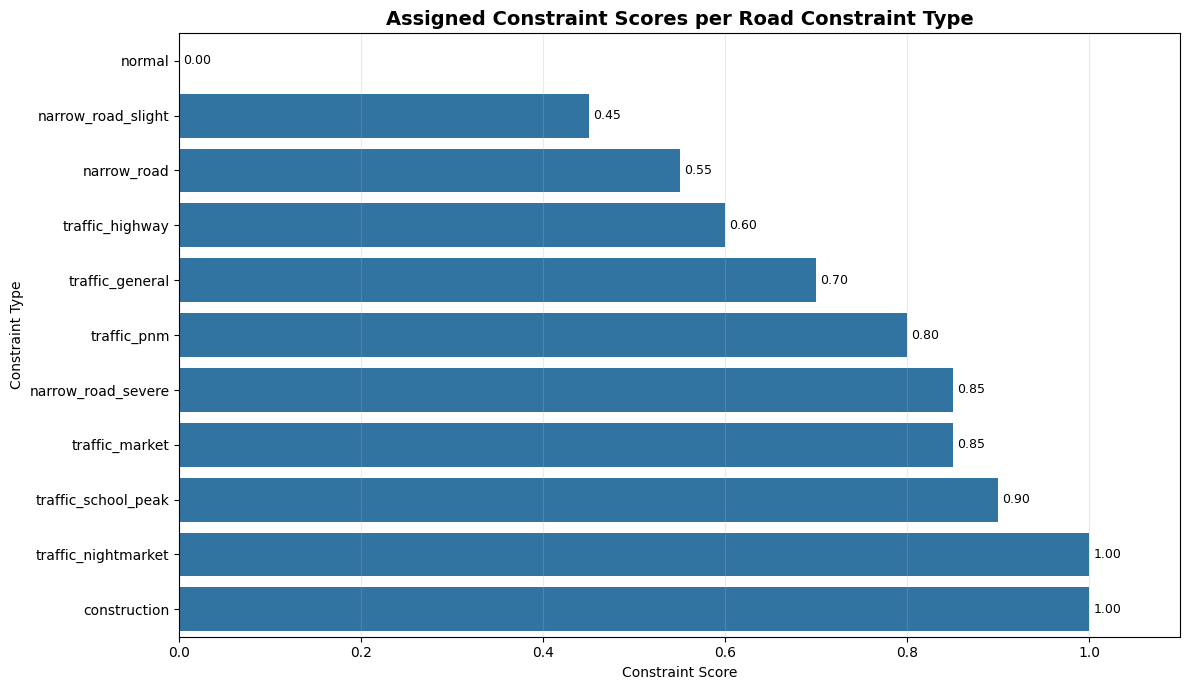

Saved: /content/drive/MyDrive/bfp_capstone_newrc/outputs/diagram_constraint_scores.png


In [28]:
# ============================================================
# Cell 24 — Constraint score reference and diagram
# ============================================================

constraint_score_reference = pd.DataFrame([
    {"Constraint Type": "normal", "Constraint Score": 0.00, "Description": "No annotated road constraint"},
    {"Constraint Type": "narrow_road_slight", "Constraint Score": 0.45, "Description": "Slightly narrow / moderate but passable road"},
    {"Constraint Type": "narrow_road", "Constraint Score": 0.55, "Description": "Standard narrow road"},
    {"Constraint Type": "traffic_highway", "Constraint Score": 0.60, "Description": "Highway traffic-prone road"},
    {"Constraint Type": "traffic_general", "Constraint Score": 0.70, "Description": "General traffic-prone road, usually 4:00 PM-7:30 PM"},
    {"Constraint Type": "traffic_pnm", "Constraint Score": 0.80, "Description": "PNM / night-market nearby traffic, usually 4:00 PM-8:00 PM"},
    {"Constraint Type": "narrow_road_severe", "Constraint Score": 0.85, "Description": "Severe narrow road cluster"},
    {"Constraint Type": "traffic_market", "Constraint Score": 0.85, "Description": "Public market crowded road"},
    {"Constraint Type": "traffic_school_peak", "Constraint Score": 0.90, "Description": "School road almost impassable during 6:30-8:00 AM and 3:30-5:30 PM"},
    {"Constraint Type": "traffic_nightmarket", "Constraint Score": 1.00, "Description": "Night-market crowded road, usually 4:00 PM-12:00 AM"},
    {"Constraint Type": "construction", "Constraint Score": 1.00, "Description": "Temporary construction / hard road constraint"},
])

print("Constraint Score Reference:")
print(constraint_score_reference.to_string(index=False))

constraint_score_reference.to_csv(
    OUTPUT_DIR + "diagram_constraint_score_reference.csv",
    index=False
)

score_plot_df = constraint_score_reference.copy()
score_plot_df = score_plot_df.sort_values("Constraint Score", ascending=True)

plt.figure(figsize=(12, 7))
ax = sns.barplot(
    data=score_plot_df,
    x="Constraint Score",
    y="Constraint Type"
)

plt.title("Assigned Constraint Scores per Road Constraint Type", fontsize=14, fontweight="bold")
plt.xlabel("Constraint Score")
plt.ylabel("Constraint Type")
plt.xlim(0, 1.10)
plt.grid(axis="x", alpha=0.25)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=9, padding=3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR + "diagram_constraint_scores.png", dpi=250, bbox_inches="tight")
plt.show()

print(f"Saved: {OUTPUT_DIR}diagram_constraint_scores.png")

In [29]:
# ============================================================
# Compatibility fix for old summary cells
# ============================================================

if "Overall Score (%)" not in results_df.columns:
    if "Conservative Score (%)" in results_df.columns:
        results_df["Overall Score (%)"] = results_df["Conservative Score (%)"]
        print("Created Overall Score (%) from Conservative Score (%).")
    elif "Quality Score (%)" in results_df.columns:
        results_df["Overall Score (%)"] = results_df["Quality Score (%)"]
        print("Created Overall Score (%) from Quality Score (%).")
    elif "Emergency Routing Score (%)" in results_df.columns:
        results_df["Overall Score (%)"] = results_df["Emergency Routing Score (%)"]
        print("Created Overall Score (%) from Emergency Routing Score (%).")
    else:
        raise KeyError("No score column found to create Overall Score (%).")

In [30]:
# ============================================================
# Cell 25 — Summary table for report
# SAFE VERSION:
# Works with old results and conservative results.
# Does not require Overall Score (%).
# ============================================================

print("Creating summary table for report...")

import numpy as np
import pandas as pd
import os

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------

if "results_df" not in globals():
    raise NameError("results_df is missing. Run your model evaluation cell first.")

if "df" not in globals():
    raise NameError("df is missing. Run your feature/data preparation cells first.")

if "OUTPUT_DIR" not in globals():
    raise NameError("OUTPUT_DIR is missing. Run your path setup cell first.")

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# Choose best score column safely
# ------------------------------------------------------------

score_priority = [
    "Conservative Score (%)",
    "Quality Score (%)",
    "Emergency Routing Score (%)",
    "Overall Score (%)"
]

main_score_col = None

for col in score_priority:
    if col in results_df.columns:
        main_score_col = col
        break

if main_score_col is None:
    raise KeyError(
        "No usable score column found. Expected one of: "
        "Conservative Score (%), Quality Score (%), Emergency Routing Score (%), Overall Score (%)."
    )

# Sort by selected main score
results_df = results_df.sort_values(
    main_score_col,
    ascending=False
).reset_index(drop=True)

best_algo = results_df.iloc[0]

print("")
print(f"Best model selected using: {main_score_col}")
print(f"Best model: {best_algo['Model']}")

# ------------------------------------------------------------
# Helper functions
# ------------------------------------------------------------

def safe_count_split(split_name):
    if "split" in df.columns:
        return int((df["split"] == split_name).sum())
    return "N/A"

def safe_count_col(col_name):
    if col_name in df.columns:
        return int(df[col_name].sum())
    return "N/A"

def safe_metric(row, col_name, decimals=2):
    if col_name in row.index:
        value = row[col_name]

        if isinstance(value, (int, float, np.integer, np.floating)):
            return round(float(value), decimals)

        return value

    return "N/A"

# ------------------------------------------------------------
# Build summary rows
# ------------------------------------------------------------

summary_rows = [
    {
        "Item": "Total Panabo road segments/edges",
        "Value": len(df)
    },
    {
        "Item": "Training road segments/edges",
        "Value": safe_count_split("train")
    },
    {
        "Item": "Validation road segments/edges",
        "Value": safe_count_split("val")
    },
    {
        "Item": "Testing road segments/edges",
        "Value": safe_count_split("test")
    },
    {
        "Item": "Total annotated constrained edges",
        "Value": safe_count_col("is_constrained")
    },
    {
        "Item": "Best GNN model",
        "Value": best_algo["Model"]
    },
    {
        "Item": f"Best model main score — {main_score_col}",
        "Value": safe_metric(best_algo, main_score_col)
    },
    {
        "Item": "Best model quality score (%)",
        "Value": safe_metric(best_algo, "Quality Score (%)")
    },
    {
        "Item": "Best model emergency routing score (%)",
        "Value": safe_metric(best_algo, "Emergency Routing Score (%)")
    },
    {
        "Item": "Best model conservative score (%)",
        "Value": safe_metric(best_algo, "Conservative Score (%)")
    },
    {
        "Item": "Best model old overall score (%)",
        "Value": safe_metric(best_algo, "Overall Score (%)")
    },
    {
        "Item": "Best model F1-score (%)",
        "Value": safe_metric(best_algo, "F1 (%)")
    },
    {
        "Item": "Best model recall (%)",
        "Value": safe_metric(best_algo, "Recall (%)")
    },
    {
        "Item": "Best model precision (%)",
        "Value": safe_metric(best_algo, "Precision (%)")
    },
    {
        "Item": "Best model balanced accuracy (%)",
        "Value": safe_metric(best_algo, "Balanced Acc. (%)")
    },
    {
        "Item": "Best model classification accuracy (%)",
        "Value": safe_metric(best_algo, "Class. Acc. (%)")
    },
    {
        "Item": "Best model threshold",
        "Value": safe_metric(best_algo, "Threshold")
    },
    {
        "Item": "Best model predicted constrained roads",
        "Value": safe_metric(best_algo, "Predicted Positives", decimals=0)
    },
    {
        "Item": "Actual constrained roads in test set",
        "Value": safe_metric(best_algo, "Actual Positives", decimals=0)
    },
    {
        "Item": "Best model RMSE",
        "Value": safe_metric(best_algo, "RMSE")
    },
    {
        "Item": "Best model MAE",
        "Value": safe_metric(best_algo, "MAE")
    },
    {
        "Item": "Best model inference time (ms)",
        "Value": safe_metric(best_algo, "Inference (ms)")
    },
]

summary_for_paper = pd.DataFrame(summary_rows)

# ------------------------------------------------------------
# Print and save
# ------------------------------------------------------------

print("")
print("Summary for Paper/Report:")
print(summary_for_paper.to_string(index=False))

summary_path = OUTPUT_DIR + "diagram_summary_for_paper.csv"

summary_for_paper.to_csv(
    summary_path,
    index=False
)

print("")
print(f"Saved: {summary_path}")

Creating summary table for report...

Best model selected using: Conservative Score (%)
Best model: GAT_MANUAL_RECALL_THRESHOLD

Summary for Paper/Report:
                                          Item                       Value
              Total Panabo road segments/edges                        3639
                  Training road segments/edges                        2420
                Validation road segments/edges                         617
                   Testing road segments/edges                         602
             Total annotated constrained edges                        1208
                                Best GNN model GAT_MANUAL_RECALL_THRESHOLD
Best model main score — Conservative Score (%)                       76.43
                  Best model quality score (%)                       75.98
        Best model emergency routing score (%)                        76.1
             Best model conservative score (%)                       76.43
              Best m

In [31]:
# ============================================================
# Cell 20.1 — Clean algorithm comparison table
# Uses GAT_MANUAL_RECALL_THRESHOLD as the official GAT result
# ============================================================

print("Building clean comparison table using GAT manual threshold as GAT result...")

import os
import numpy as np
import pandas as pd

if "results_df" not in globals():
    raise NameError("results_df is missing. Run Cell 19 and Cell 19.4 first.")

if "OUTPUT_DIR" not in globals():
    raise NameError("OUTPUT_DIR is missing.")

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# Helper: choose the preferred row for each algorithm
# ------------------------------------------------------------

def get_best_row_for_algorithm(results_df, algorithm_name):
    """
    For GAT, prefer GAT_MANUAL_RECALL_THRESHOLD if it exists.
    For GCN and GraphSAGE, use the normal row.
    """

    if algorithm_name == "GAT":
        preferred_names = [
            "GAT_MANUAL_RECALL_THRESHOLD",
            "GAT_RECALL_RESCUED",
            "GAT"
        ]
    else:
        preferred_names = [algorithm_name]

    for name in preferred_names:
        matched = results_df[results_df["Model"] == name].copy()

        if len(matched) > 0:
            row = matched.iloc[0].copy()
            row["Actual Model Key"] = algorithm_name
            row["Result Label"] = name

            if name == "GAT_MANUAL_RECALL_THRESHOLD":
                row["Model"] = "GAT (manual threshold)"
            elif name == "GAT_RECALL_RESCUED":
                row["Model"] = "GAT (recall rescued)"
            else:
                row["Model"] = algorithm_name

            return row

    return None


comparison_rows = []

for algo in ["GCN", "GAT", "GraphSAGE"]:
    row = get_best_row_for_algorithm(results_df, algo)

    if row is not None:
        comparison_rows.append(row)

algo_compare_df = pd.DataFrame(comparison_rows)

if len(algo_compare_df) == 0:
    raise ValueError("No comparison rows found. Check results_df['Model'].")

# ------------------------------------------------------------
# Fix numeric columns
# ------------------------------------------------------------

numeric_cols = [
    "Pred. Acc. (%)",
    "Abs. Acc. (%)",
    "Class. Acc. (%)",
    "Balanced Acc. (%)",
    "Precision (%)",
    "Recall (%)",
    "F1 (%)",
    "Specificity (%)",
    "RMSE",
    "MAE",
    "Threshold",
    "Predicted Positives",
    "Actual Positives",
    "TP",
    "FP",
    "TN",
    "FN",
    "Quality Score (%)",
    "Emergency Routing Score (%)",
    "Conservative Score (%)",
    "Overall Score (%)",
    "Inference (ms)",
]

for col in numeric_cols:
    if col in algo_compare_df.columns:
        algo_compare_df[col] = pd.to_numeric(algo_compare_df[col], errors="coerce")

# If Inference (ms) is missing for manual GAT, copy original GAT inference if available
if "Inference (ms)" in results_df.columns:
    original_gat = results_df[results_df["Model"] == "GAT"]

    if len(original_gat) > 0:
        gat_inference = pd.to_numeric(
            original_gat["Inference (ms)"].iloc[0],
            errors="coerce"
        )

        mask_manual_gat = algo_compare_df["Result Label"] == "GAT_MANUAL_RECALL_THRESHOLD"
        algo_compare_df.loc[mask_manual_gat, "Inference (ms)"] = gat_inference

# If Overall Score does not exist, recompute it
if "Overall Score (%)" not in algo_compare_df.columns:
    algo_compare_df["Overall Score (%)"] = (
        0.30 * algo_compare_df["F1 (%)"] +
        0.25 * algo_compare_df["Balanced Acc. (%)"] +
        0.20 * algo_compare_df["Recall (%)"] +
        0.15 * algo_compare_df["Precision (%)"] +
        0.10 * algo_compare_df["Abs. Acc. (%)"]
    )

algo_compare_df = algo_compare_df.sort_values(
    "Overall Score (%)",
    ascending=False
).reset_index(drop=True)

# ------------------------------------------------------------
# Save and print
# ------------------------------------------------------------

display_cols = [
    "Model",
    "Actual Model Key",
    "Result Label",
    "Precision (%)",
    "Recall (%)",
    "F1 (%)",
    "Specificity (%)",
    "Class. Acc. (%)",
    "Balanced Acc. (%)",
    "Threshold",
    "Predicted Positives",
    "Actual Positives",
    "TP",
    "FP",
    "TN",
    "FN",
    "Quality Score (%)",
    "Emergency Routing Score (%)",
    "Conservative Score (%)",
    "Overall Score (%)",
    "Inference (ms)",
]

display_cols = [c for c in display_cols if c in algo_compare_df.columns]

print("")
print("CLEAN GNN ALGORITHM COMPARISON")
print(algo_compare_df[display_cols].round(2).to_string(index=False))

compare_path = OUTPUT_DIR + "clean_algorithm_comparison_gat_manual.csv"

algo_compare_df[display_cols].to_csv(
    compare_path,
    index=False
)

print("")
print(f"Saved clean comparison table to: {compare_path}")

Building clean comparison table using GAT manual threshold as GAT result...

CLEAN GNN ALGORITHM COMPARISON
                 Model Actual Model Key                Result Label  Precision (%)  Recall (%)  F1 (%)  Specificity (%)  Class. Acc. (%)  Balanced Acc. (%)  Threshold  Predicted Positives  Actual Positives    TP   FP    TN   FN  Quality Score (%)  Emergency Routing Score (%)  Conservative Score (%)  Overall Score (%)  Inference (ms)
GAT (manual threshold)              GAT GAT_MANUAL_RECALL_THRESHOLD          71.60       76.17   73.81            80.65            78.90              78.41       0.45                  NaN               NaN   NaN  NaN   NaN  NaN              75.98                        76.10                   76.43              76.14            2.69
             GraphSAGE        GraphSAGE                   GraphSAGE          69.65       76.17   72.76            78.75            77.74              77.46       0.57                257.0             235.0 179.0 78.0 289.0

Creating comparative bar chart...


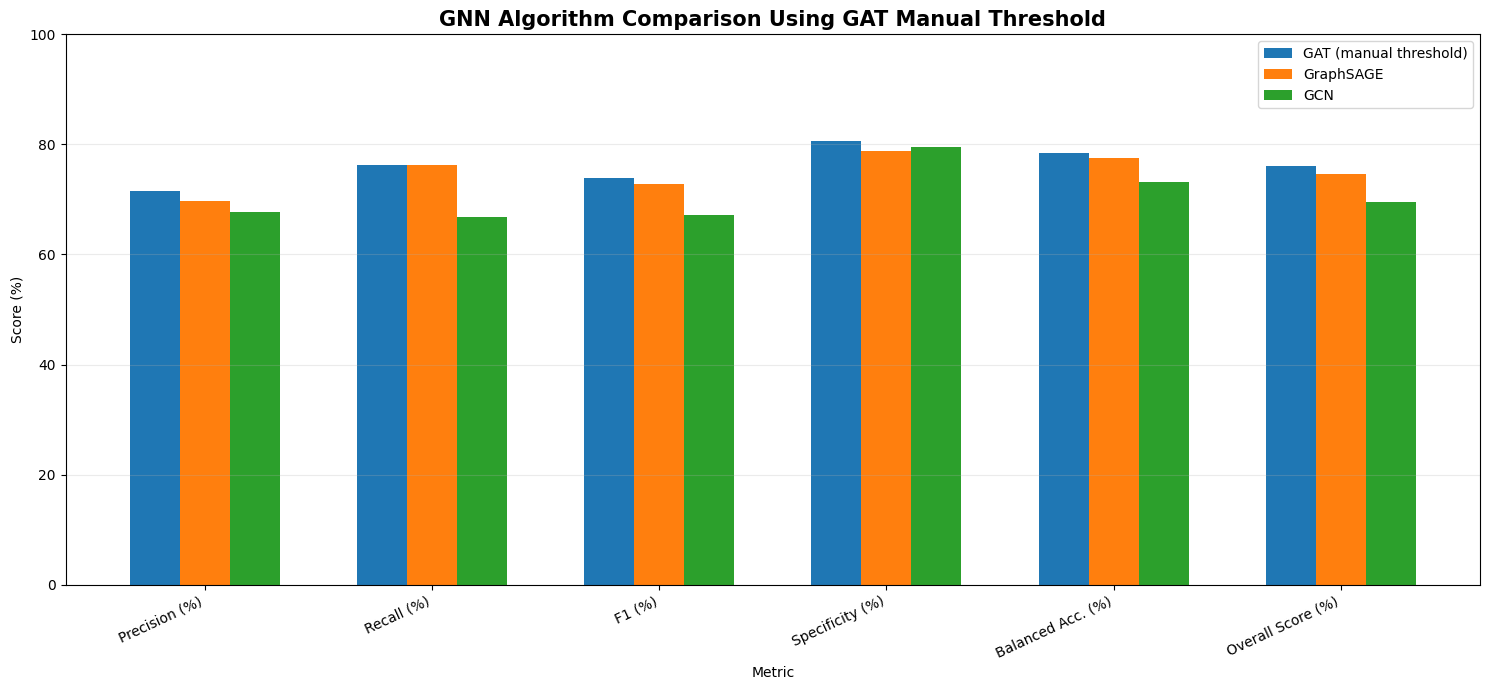

Saved bar chart to: /content/drive/MyDrive/bfp_capstone_newrc/outputs/diagram_algorithm_comparison_gat_manual_bar.png


In [32]:
# ============================================================
# Cell 20.2 — Comparative bar chart
# Shows GCN, GAT manual threshold, and GraphSAGE
# ============================================================

print("Creating comparative bar chart...")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if "algo_compare_df" not in globals():
    raise NameError("algo_compare_df is missing. Run Cell 20.1 first.")

metrics_to_plot = [
    "Precision (%)",
    "Recall (%)",
    "F1 (%)",
    "Specificity (%)",
    "Balanced Acc. (%)",
    "Overall Score (%)",
]

metrics_to_plot = [
    m for m in metrics_to_plot
    if m in algo_compare_df.columns
]

plot_df = algo_compare_df[["Model"] + metrics_to_plot].copy()

x = np.arange(len(metrics_to_plot))
bar_width = 0.22

fig, ax = plt.subplots(figsize=(15, 7))

for i, (_, row) in enumerate(plot_df.iterrows()):
    values = [float(row[m]) for m in metrics_to_plot]

    ax.bar(
        x + (i - 1) * bar_width,
        values,
        width=bar_width,
        label=row["Model"]
    )

ax.set_title("GNN Algorithm Comparison Using GAT Manual Threshold", fontsize=15, fontweight="bold")
ax.set_xlabel("Metric")
ax.set_ylabel("Score (%)")
ax.set_xticks(x)
ax.set_xticklabels(metrics_to_plot, rotation=25, ha="right")
ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.25)
ax.legend()

plt.tight_layout()

bar_path = OUTPUT_DIR + "diagram_algorithm_comparison_gat_manual_bar.png"

plt.savefig(
    bar_path,
    dpi=250,
    bbox_inches="tight"
)

plt.show()

print(f"Saved bar chart to: {bar_path}")

Creating radar chart...


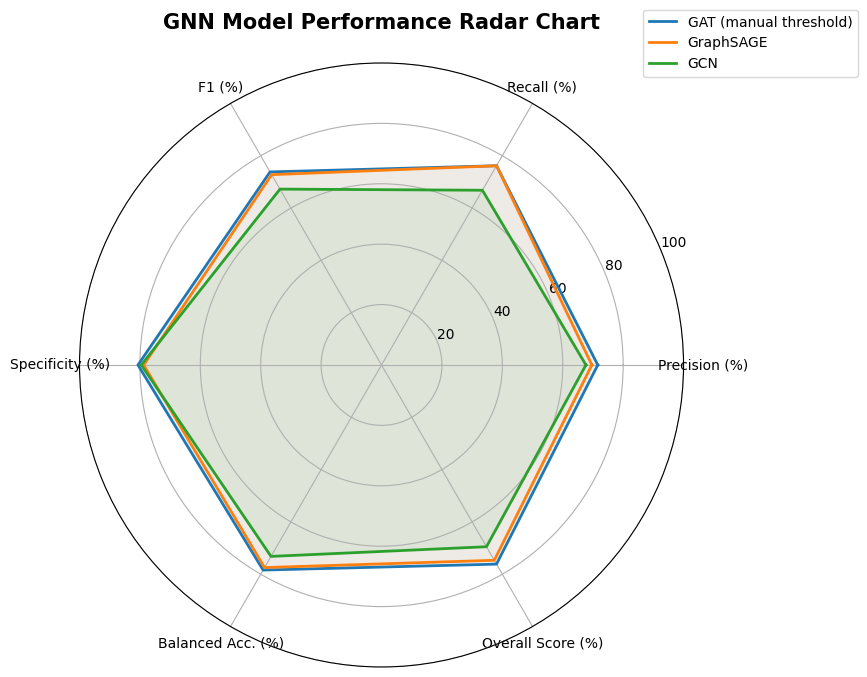

Saved radar chart to: /content/drive/MyDrive/bfp_capstone_newrc/outputs/diagram_algorithm_comparison_gat_manual_radar.png


In [33]:
# ============================================================
# Cell 20.3 — Radar chart for important metrics
# ============================================================

print("Creating radar chart...")

import os
import numpy as np
import matplotlib.pyplot as plt

if "algo_compare_df" not in globals():
    raise NameError("algo_compare_df is missing. Run Cell 20.1 first.")

radar_metrics = [
    "Precision (%)",
    "Recall (%)",
    "F1 (%)",
    "Specificity (%)",
    "Balanced Acc. (%)",
    "Overall Score (%)",
]

radar_metrics = [
    m for m in radar_metrics
    if m in algo_compare_df.columns
]

num_vars = len(radar_metrics)

angles = np.linspace(
    0,
    2 * np.pi,
    num_vars,
    endpoint=False
).tolist()

angles += angles[:1]

fig = plt.figure(figsize=(9, 9))
ax = plt.subplot(111, polar=True)

for _, row in algo_compare_df.iterrows():
    values = [float(row[m]) for m in radar_metrics]
    values += values[:1]

    ax.plot(
        angles,
        values,
        linewidth=2,
        label=row["Model"]
    )

    ax.fill(
        angles,
        values,
        alpha=0.08
    )

ax.set_xticks(angles[:-1])
ax.set_xticklabels(radar_metrics, fontsize=10)
ax.set_ylim(0, 100)
ax.set_title("GNN Model Performance Radar Chart", fontsize=15, fontweight="bold", pad=25)
ax.legend(loc="upper right", bbox_to_anchor=(1.30, 1.10))
ax.grid(True)

plt.tight_layout()

radar_path = OUTPUT_DIR + "diagram_algorithm_comparison_gat_manual_radar.png"

plt.savefig(
    radar_path,
    dpi=250,
    bbox_inches="tight"
)

plt.show()

print(f"Saved radar chart to: {radar_path}")

In [34]:
# ============================================================
# Cell 20.4 — Important metrics summary table for paper/report
# ============================================================

print("Creating important metrics summary table...")

import os
import pandas as pd

if "algo_compare_df" not in globals():
    raise NameError("algo_compare_df is missing. Run Cell 20.1 first.")

summary_cols = [
    "Model",
    "Precision (%)",
    "Recall (%)",
    "F1 (%)",
    "Specificity (%)",
    "Class. Acc. (%)",
    "Balanced Acc. (%)",
    "Threshold",
    "Predicted Positives",
    "Actual Positives",
    "TP",
    "FP",
    "TN",
    "FN",
    "Quality Score (%)",
    "Emergency Routing Score (%)",
    "Conservative Score (%)",
    "Overall Score (%)",
]

summary_cols = [
    c for c in summary_cols
    if c in algo_compare_df.columns
]

paper_summary_df = algo_compare_df[summary_cols].copy()

paper_summary_df["Important Metrics 70+"] = (
    (paper_summary_df["Precision (%)"] >= 70) &
    (paper_summary_df["Recall (%)"] >= 70) &
    (paper_summary_df["F1 (%)"] >= 70)
)

paper_summary_df = paper_summary_df.sort_values(
    "Overall Score (%)",
    ascending=False
).reset_index(drop=True)

print("")
print("IMPORTANT METRICS SUMMARY")
print(paper_summary_df.round(2).to_string(index=False))

summary_path = OUTPUT_DIR + "important_metrics_summary_for_paper_gat_manual.csv"

paper_summary_df.to_csv(
    summary_path,
    index=False
)

print("")
print(f"Saved summary table to: {summary_path}")

Creating important metrics summary table...

IMPORTANT METRICS SUMMARY
                 Model  Precision (%)  Recall (%)  F1 (%)  Specificity (%)  Class. Acc. (%)  Balanced Acc. (%)  Threshold  Predicted Positives  Actual Positives    TP   FP    TN   FN  Quality Score (%)  Emergency Routing Score (%)  Conservative Score (%)  Overall Score (%)  Important Metrics 70+
GAT (manual threshold)          71.60       76.17   73.81            80.65            78.90              78.41       0.45                  NaN               NaN   NaN  NaN   NaN  NaN              75.98                        76.10                   76.43              76.14                   True
             GraphSAGE          69.65       76.17   72.76            78.75            77.74              77.46       0.57                257.0             235.0 179.0 78.0 289.0 56.0              74.89                        74.93                   73.97              74.67                  False
                   GCN          67.67 

In [35]:
# ============================================================
# Cell 20.5 — Confusion matrix from TP/FP/TN/FN
# Uses best row from algo_compare_df
# ============================================================

print("Creating confusion matrix for best model...")

import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

if "algo_compare_df" not in globals():
    raise NameError("algo_compare_df is missing. Run Cell 20.1 first.")

best_compare_row = algo_compare_df.sort_values(
    "Overall Score (%)",
    ascending=False
).iloc[0]

best_display_name = best_compare_row["Model"]

for col in ["TP", "FP", "TN", "FN"]:
    if col not in best_compare_row.index:
        raise KeyError(f"{col} is missing from algo_compare_df. Run Cell 19.4 and Cell 20.1 first.")

tp = int(best_compare_row["TP"])
fp = int(best_compare_row["FP"])
tn = int(best_compare_row["TN"])
fn = int(best_compare_row["FN"])

cm = np.array([
    [tn, fp],
    [fn, tp]
])

fig, ax = plt.subplots(figsize=(6, 5))

im = ax.imshow(cm)

ax.set_title(f"Confusion Matrix — {best_display_name}", fontsize=14, fontweight="bold")
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["Normal", "Constrained"])
ax.set_yticklabels(["Normal", "Constrained"])

for i in range(2):
    for j in range(2):
        ax.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
            fontsize=13,
            fontweight="bold"
        )

fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()

cm_path = OUTPUT_DIR + "diagram_best_model_confusion_matrix_gat_manual.png"

plt.savefig(
    cm_path,
    dpi=250,
    bbox_inches="tight"
)

plt.show()

cm_df = pd.DataFrame(
    cm,
    index=["Actual Normal", "Actual Constrained"],
    columns=["Predicted Normal", "Predicted Constrained"]
)

cm_csv_path = OUTPUT_DIR + "best_model_confusion_matrix_gat_manual.csv"

cm_df.to_csv(cm_csv_path)

print("")
print(cm_df)
print("")
print(f"Saved confusion matrix image to: {cm_path}")
print(f"Saved confusion matrix CSV to: {cm_csv_path}")

Creating confusion matrix for best model...


ValueError: cannot convert float NaN to integer

In [ ]:
# ============================================================
# Cell 20.6 — GAT threshold sensitivity chart
# Uses gat_manual_df from Cell 19.4
# ============================================================

print("Creating GAT threshold sensitivity chart...")

import os
import pandas as pd
import matplotlib.pyplot as plt

if "gat_manual_df" not in globals():
    manual_path = OUTPUT_DIR + "gat_manual_threshold_results.csv"

    if os.path.exists(manual_path):
        gat_manual_df = pd.read_csv(manual_path)
    else:
        raise NameError("gat_manual_df is missing. Run Cell 19.4 first.")

threshold_plot_cols = [
    "Precision (%)",
    "Recall (%)",
    "F1 (%)",
    "Overall Score (%)",
    "Recall Priority Score (%)",
]

threshold_plot_cols = [
    c for c in threshold_plot_cols
    if c in gat_manual_df.columns
]

fig, ax = plt.subplots(figsize=(12, 6))

for col in threshold_plot_cols:
    ax.plot(
        gat_manual_df["Threshold"],
        gat_manual_df[col],
        marker="o",
        linewidth=2,
        label=col
    )

# Mark selected manual threshold if available
if "results_df" in globals():
    selected = results_df[results_df["Model"] == "GAT_MANUAL_RECALL_THRESHOLD"]

    if len(selected) > 0:
        selected_threshold = float(selected["Threshold"].iloc[0])
        ax.axvline(
            selected_threshold,
            linestyle="--",
            linewidth=2,
            label=f"Selected threshold = {selected_threshold:.2f}"
        )

ax.set_title("GAT Manual Threshold Sensitivity", fontsize=14, fontweight="bold")
ax.set_xlabel("Threshold")
ax.set_ylabel("Score (%)")
ax.set_ylim(0, 100)
ax.grid(True, alpha=0.25)
ax.legend()

plt.tight_layout()

threshold_chart_path = OUTPUT_DIR + "diagram_gat_manual_threshold_sensitivity.png"

plt.savefig(
    threshold_chart_path,
    dpi=250,
    bbox_inches="tight"
)

plt.show()

print(f"Saved threshold sensitivity chart to: {threshold_chart_path}")

In [ ]:
# ============================================================
# Cell 20.7 — Best result resolver for export
# Fixes GAT_MANUAL_RECALL_THRESHOLD model lookup
# ============================================================

print("Resolving best result label to actual trained model...")

if "results_df" not in globals():
    raise NameError("results_df is missing.")

if "models" not in globals():
    raise NameError("models is missing.")

if "algo_compare_df" in globals() and len(algo_compare_df) > 0:
    best_export_row = algo_compare_df.sort_values(
        "Overall Score (%)",
        ascending=False
    ).iloc[0]
else:
    best_export_row = results_df.sort_values(
        "Overall Score (%)",
        ascending=False
    ).iloc[0]

best_result_label = str(best_export_row["Model"])
best_threshold = float(best_export_row["Threshold"])

def resolve_actual_model_key(label):
    label_upper = str(label).upper()

    if "GAT" in label_upper:
        return "GAT"
    elif "GCN" in label_upper:
        return "GCN"
    elif "GRAPHSAGE" in label_upper:
        return "GraphSAGE"

    raise KeyError(
        f"Could not resolve model label '{label}' to actual models key. "
        f"Available models: {list(models.keys())}"
    )

best_model_name = resolve_actual_model_key(best_result_label)
best_model = models[best_model_name]

print("")
print("Best result label:", best_result_label)
print("Actual model key used for inference/export:", best_model_name)
print("Threshold used:", best_threshold)

In [ ]:
# Save best trained GAT model with manual threshold as .pt

import torch
import json
from pathlib import Path
from google.colab import drive

# Mount Google Drive
drive.mount("/content/drive")

# Output folder
OUTPUT_DIR = Path("/content/drive/MyDrive/bfp_capstone_newrc/outputs/best_model_export")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# File paths
BEST_MODEL_PT_PATH = OUTPUT_DIR / "best_gat_manual_threshold_model.pt"
BEST_MODEL_INFO_PATH = OUTPUT_DIR / "best_gat_manual_threshold_model_info.json"

# Since GAT manual threshold uses the trained GAT model + threshold adjustment
BASE_MODEL_KEY = "GAT"
BEST_MODEL_DISPLAY_NAME = "GAT (manual threshold)"
SELECTED_THRESHOLD = 0.45

# Get the actual trained GAT model from your models dictionary
best_model = models[BASE_MODEL_KEY]
best_model.eval()

# Try to save feature columns if they exist in your notebook
try:
    saved_feature_cols = feature_cols
except NameError:
    saved_feature_cols = None

# Try to save model metrics if results_df exists
try:
    saved_metrics = results_df.to_dict(orient="records")
except NameError:
    saved_metrics = None

# Save PyTorch checkpoint
checkpoint = {
    "model_display_name": BEST_MODEL_DISPLAY_NAME,
    "base_model_key": BASE_MODEL_KEY,
    "selected_threshold": SELECTED_THRESHOLD,
    "model_state_dict": best_model.state_dict(),
    "feature_cols": saved_feature_cols,
    "metrics": saved_metrics,
    "note": "GAT manual threshold uses the trained GAT model weights with threshold = 0.45."
}

torch.save(checkpoint, BEST_MODEL_PT_PATH)

# Save readable info file also
model_info = {
    "model_display_name": BEST_MODEL_DISPLAY_NAME,
    "base_model_key": BASE_MODEL_KEY,
    "selected_threshold": SELECTED_THRESHOLD,
    "pt_file": str(BEST_MODEL_PT_PATH),
    "feature_cols": saved_feature_cols,
    "note": "Use this .pt file to reload the trained GAT model. Apply threshold 0.45 during prediction."
}

with open(BEST_MODEL_INFO_PATH, "w") as f:
    json.dump(model_info, f, indent=4)

print("Saved best trained model:")
print(BEST_MODEL_PT_PATH)

print("\nSaved model info:")
print(BEST_MODEL_INFO_PATH)